# Explainable Federated Learning for Cross-Platform Early-Stage Ransomware Detection
**Full pipeline, revised for journal submission (single notebook).** Windows (RanSAP), Android (DroidRan) and Linux (ftrace)
are three heterogeneous clients (20 / 22 / 34 features after temporal feature construction).

### What changed in this revision (mapped to the open points of the assessment)

| Research component | Assessment before | What this notebook now adds | Section |
|---|---|---|---|
| Three heterogeneous datasets | Implemented | Leakage / duplicate / label-confounding audit of every split | 1b |
| Explainability | Implemented; interpretation needs validation | Stability across seeds, method agreement, deletion faithfulness, concept necessity; computed verdict | 8b |
| Federated XGBoost | Implemented | Communication cost; threshold-transfer audit | 6b, 10a |
| Cross-platform neural FedAvg | Implemented | Leave-one-platform-out transfer of the aggregated block vs scratch / XGBoost | 7e |
| Early-stage detection | Partial | Linux trace-prefix detection, Android in-stage latency, Windows damage-before-detection | 0.4, 5.3-5.5 |
| Generalizable ransomware detection | Not yet established on all platforms | Android leave-one-family / vector-out, Linux leave-one-process-out, Windows group-aware threshold, session-fingerprint probe | 2b, 7c, 7f |
| Experimental comparisons | Substantial, require auditing | Trivial baselines, label-shuffle control, equal-effort tuning, Holm correction, new metrics (oracle TPR@10 % FPR, Brier) | 4b, 7d |
| Journal readiness | Major revision needed | Data-driven claims matrix, generated limitations, reviewer risk register, LaTeX tables, reproducibility manifest | 10-11 |

**Nothing in the claims matrix is typed in: each status is computed from the result tables by a rule printed in the code.**
If a component is not established, the matrix says so and states what failed.

**Run it.** Kaggle with the three raw datasets attached (RanSAP, DroidRan, Linux ftrace CSV). Section 0 builds all files from the raw data
and skips anything already prepared. `QUICK=1` (environment variable) runs a tiny smoke test - never quote QUICK numbers.
The full run is long (Android group-CV, 5 seeds x 4 model families x 5 variants, bootstraps); budget several hours plus the Linux scan.

| Title part | What this notebook does |
|---|---|
| Cross-Platform | One shared **binary** task on all 3 platforms, trained jointly with multi-task FedAvg, federated XGBoost inside each platform, transfer to a held-out platform |
| Early-Stage Detection | Windows: first 1/2/5/10 s and damage before alert. Android: attack-stage-resolved plus latency. Linux: trace-prefix (fraction of trace) |
| Ransomware Detection | Binary detection on **all three** platforms, XGBoost / SVM / Decision Tree / Logistic Regression, tuned and untuned |
| Supporting evidence | Ablation, family / benign-software / environment holdouts, non-IID clients, bootstrap significance with Holm correction |

In [1]:
import os, sys, json, time, warnings, zipfile, re
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

QUICK = os.environ.get("QUICK", "0") == "1"      # QUICK=1 -> tiny smoke-test run (minutes), never use for reported numbers
SEEDS = [2026, 2027, 2028, 2029, 2030][: (2 if QUICK else 5)]
SEED = SEEDS[0]
MAX_FPR = 0.10                  # alert budget: at most 10% benign false alarms
SVM_MAX_TRAIN = 8000 if not QUICK else 1500            # SVM is O(n^2): subsample large training sets
FED_ROUNDS = 20 if not QUICK else 3
FED_LOCAL_STEPS = 100 if not QUICK else 10
FED_BATCH = 128
FED_LR = 1e-3
FXGB_ROUNDS = 20 if not QUICK else 3
FXGB_LOCAL_TREES = 5
BOOT_N = 2000 if not QUICK else 100             # paired-bootstrap resamples
BOOT_N_CLUSTER = 1000 if not QUICK else 100     # cluster-bootstrap resamples
PERM_REPEATS = 5 if not QUICK else 2            # permutation-importance repeats
RANDOM_DELETIONS = 30 if not QUICK else 5       # random feature sets per deletion test
GEN_MAX_TRAIN = 60000 if not QUICK else 3000    # training-row cap inside the Android group-CV folds
STRICT_SEP = 0.85                               # Android_Strict drops features whose univariate separability >= this
ALPHA = 0.05
EARLY_RECALL_TARGET, EARLY_FPR_LIMIT = 0.80, 0.15   # rule for 'early-stage detection is supported'

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./working")
WORK.mkdir(parents=True, exist_ok=True)
OUT = WORK / "Full_Pipeline_Results"
OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)

SEARCH_ROOTS = [p for p in [WORK, Path("/kaggle/input"), Path("/mnt/user-data/uploads")] if p.exists()]
RAW_ROOTS = [p for p in [Path("/kaggle/input"), Path(os.environ.get("RAW_DATA_DIR", "/nonexistent"))] if p.exists()]


def walk_all(roots, max_depth=12):
    """os.walk that FOLLOWS symlinks (Kaggle dataset mounts are often symlinks, which Path.rglob skips)."""
    for root in roots:
        root = Path(root)
        base = len(root.parts)
        for dp, dns, fns in os.walk(root, followlinks=True):
            dpp = Path(dp)
            if len(dpp.parts) - base >= max_depth:
                dns[:] = []
            yield dpp, dns, fns


def find_file(name, required=True, roots=None):
    """Find a file by exact name. Earlier roots win (our own prepared files in WORK come first)."""
    for root in (roots or SEARCH_ROOTS):
        hits = [dp / name for dp, _, fns in walk_all([root]) if name in fns]
        if hits:
            return sorted(hits, key=lambda p: (len(str(p)), str(p)))[0]
    if required:
        raise FileNotFoundError(f"'{name}' not found under {[str(r) for r in (roots or SEARCH_ROOTS)]}.")
    return None


def save_csv(df, name):
    df.to_csv(OUT / name, index=False)
    return OUT / name


print("Work dir:", WORK)
print("Search roots:", [str(r) for r in SEARCH_ROOTS])


def show(df, n=None):
    df = df if n is None else df.head(n)
    try:
        display(df)
    except NameError:
        print(df.to_string())

Work dir: /kaggle/working
Search roots: ['/kaggle/working', '/kaggle/input']


## 0. Build the datasets from the RAW files (start from zero)
Each builder is skipped when its output already exists in the work folder, so the notebook can be re-run.
Set `REBUILD = True` to force everything to be rebuilt.

| Platform | Raw input | Output |
|---|---|---|
| Windows | RanSAP `ata_read.csv` / `ata_write.csv` per execution | `ransap_train.csv`, `ransap_test.csv` (execution-disjoint) |
| Android | 36 DroidRan Excel workbooks (12 families x 3 attack vectors) | `Android_Train/Validation/Test.parquet` (family-disjoint) |
| Linux | `isitencrypted_dataset.csv` (function-graph traces) | `Linux_Train/Test.parquet`, `Feature_Whitelist.json` (process-disjoint) |

In [2]:
import csv, io, gc, hashlib
from collections import Counter, defaultdict
from itertools import combinations

from sklearn.model_selection import train_test_split, GroupKFold

REBUILD = False
PREP = WORK / "prepared"
PREP.mkdir(exist_ok=True)


def have(*names):
    """True when every file already exists somewhere under the work folder (also reuses an earlier run's output)."""
    return (not REBUILD) and all(find_file(n, required=False, roots=[WORK]) is not None for n in names)


try:
    from tqdm.auto import tqdm
except Exception:                                   # tqdm missing: plain iterator
    tqdm = lambda x, **k: x

### 0.1 Windows (RanSAP)
Labels come from the software-group name: the 7 ransomware families (each with `-largefiles` / `-w10dirs`
variants) are ransomware; AESCrypt, Excel, Firefox, SDelete and Zip are benign. Features are cumulative counts and
bytes of read/write events inside the first 1, 2, 5, 10, 20 and 30 seconds of each execution.
The split keeps all windows of an execution in the same partition.

In [3]:
RANSOMWARE_FAMILIES = {"Cerber", "Darkside", "GandCrab4", "Ryuk", "Sodinokibi", "TeslaCrypt", "WannaCry"}
BENIGN_GROUPS = {"AESCrypt", "Excel", "Firefox", "SDelete", "Zip"}
TIME_POINTS = [1, 2, 5, 10, 20, 30]


RANSAP_HINT = Path("/kaggle/input/datasets/hiranomanabu/ransap-2022-ransomware-behavioral-features/"
                   "RanSAP/dataset/original")


def find_ransap_original():
    if RANSAP_HINT.exists():
        return RANSAP_HINT
    for dp, dns, _ in walk_all(RAW_ROOTS):
        if dp.name == "original" and dp.parent.name == "dataset":
            return dp
    return None


def classify_group(group):
    if group in BENIGN_GROUPS:
        return 0
    for fam in RANSOMWARE_FAMILIES:
        if group in {fam, f"{fam}-largefiles", f"{fam}-w10dirs"}:
            return 1
    raise ValueError(f"Unverified software group: {group}")


def summarize_events(path, kind, start_time, chunk_size=100_000):
    n = len(TIME_POINTS)
    counts, byte_sums = np.zeros(n, np.int64), np.zeros(n)
    m4s, m5s, mcs = np.zeros(n), np.zeros(n), np.zeros(n, np.int64)
    cols = [0, 3] if kind == "read" else [0, 3, 4, 5]
    for chunk in pd.read_csv(path, header=None, usecols=cols, chunksize=chunk_size):
        elapsed = chunk.iloc[:, 0].to_numpy(float) - start_time
        sizes = chunk.iloc[:, 1].to_numpy(float)
        for i, sec in enumerate(TIME_POINTS):
            mask = (elapsed >= 0) & (elapsed < sec)
            counts[i] += mask.sum()
            byte_sums[i] += sizes[mask].sum()
            if kind == "write":
                m4, m5 = chunk.iloc[:, 2].to_numpy(float)[mask], chunk.iloc[:, 3].to_numpy(float)[mask]
                ok = np.isfinite(m4) & np.isfinite(m5)
                m4s[i] += m4[ok].sum(); m5s[i] += m5[ok].sum(); mcs[i] += ok.sum()
    return counts, byte_sums, m4s, m5s, mcs


def first_timestamp(path):
    return float(pd.read_csv(path, header=None, usecols=[0], nrows=1).iloc[0, 0])


def build_windows():
    original = find_ransap_original()
    if original is None:
        raise FileNotFoundError("RanSAP not found: attach the 'RanSAP (2022) ransomware behavioral features' "
                                "dataset (needs a folder dataset/original).")
    recs = []
    write_files = [Path(dp) / "ata_write.csv" for dp, _, fns in os.walk(original, followlinks=True)
                   if "ata_write.csv" in fns]
    for wp in write_files:
        ed = wp.parent
        rel = ed.relative_to(original)
        if len(rel.parts) < 3 or not (ed / "ata_read.csv").exists():
            continue
        recs.append(dict(environment=rel.parts[0], software_group=rel.parts[1], execution_id=rel.parts[-1],
                         read_path=str(ed / "ata_read.csv"), write_path=str(wp)))
    manifest = pd.DataFrame(recs)
    manifest["label"] = manifest["software_group"].map(classify_group).astype(int)
    print("RanSAP executions:", len(manifest), "| groups:", manifest.software_group.nunique(),
          "| label counts:", manifest.label.value_counts().to_dict())
    rows, errors = [], []
    for _, s in tqdm(manifest.iterrows(), total=len(manifest)):
        try:
            t0 = min(first_timestamp(s.read_path), first_timestamp(s.write_path))
            rc, rb, _, _, _ = summarize_events(s.read_path, "read", t0)
            wc, wb, m4, m5, mc = summarize_events(s.write_path, "write", t0)
            for i, sec in enumerate(TIME_POINTS):
                rows.append(dict(environment=s.environment, software_group=s.software_group,
                                 execution_id=s.execution_id, execution_path=str(Path(s.write_path).parent),
                                 seconds=sec, read_count=rc[i], write_count=wc[i], read_bytes=rb[i],
                                 write_bytes=wb[i], read_write_ratio=rc[i] / max(wc[i], 1),
                                 write_metric_4_mean=(m4[i] / mc[i] if mc[i] > 0 else np.nan),
                                 write_metric_5_mean=(m5[i] / mc[i] if mc[i] > 0 else np.nan), label=s.label))
        except Exception as e:
            errors.append((s.execution_id, str(e)))
    if errors:
        print("Execution read errors:", len(errors), errors[:3])
    feats = pd.DataFrame(rows)
    ex = feats[["execution_path", "label"]].drop_duplicates()
    tr_ids, te_ids = train_test_split(ex["execution_path"], test_size=0.20, random_state=42, stratify=ex["label"])
    tr = feats[feats.execution_path.isin(set(tr_ids))]
    te = feats[feats.execution_path.isin(set(te_ids))]
    assert set(tr.execution_path).isdisjoint(set(te.execution_path))
    tr.to_csv(PREP / "ransap_train.csv", index=False)
    te.to_csv(PREP / "ransap_test.csv", index=False)
    print(f"Windows: train {len(tr)} rows / test {len(te)} rows ({tr.execution_path.nunique()} / "
          f"{te.execution_path.nunique()} executions)")


if have("ransap_train.csv", "ransap_test.csv"):
    print("Windows files already prepared - skipping")
else:
    build_windows()

RanSAP executions: 1044 | groups: 26 | label counts: {1: 843, 0: 201}


  0%|          | 0/1044 [00:00<?, ?it/s]

Windows: train 5010 rows / test 1254 rows (835 / 209 executions)


### 0.2 Android (DroidRan)
36 workbooks (family = file name, attack vector = parent folder); each workbook has one sheet per attack stage
(Before, Initial Access, Privilege Escalation, Command & Control, Impact). The split is **family-disjoint**:
12 families are shuffled with seed 42 and assigned 8 / 2 / 2 to train / validation / test.

In [4]:
AND_RAW_FEATURES = ["Total RAM (GB)", "Free RAM (GB)", "Available Internal Memory (MB)", "Available storage (GB)",
                    "Total Internal Memory (GB)", "Received (kb/s)", "Transmitted (kb/s)", "Voltage (mV)",
                    "Temp (oC)", "Th Sensor 0", "Th Sensor 1", "Th Sensor 2", "Temperature (oC)",
                    "Frequency (MHz)"] + [f"CPU {i}" for i in range(8)]
AND_STAGE_BY_SHEET = {"Before": 0, "Initial Access": 1, "Privilege Escalation": 2,
                      "Command & Control": 3, "Impact": 4}


def build_android():
    files = sorted(dp / f for dp, _, fns in walk_all(RAW_ROOTS) for f in fns
                   if f.lower().endswith((".xlsx", ".xls")) and "prepared" not in dp.parts
                   and "Full_Pipeline_Results" not in dp.parts)
    if not files:
        raise FileNotFoundError("No Excel workbooks found: attach the DroidRan dataset to the notebook.")
    print("DroidRan workbooks:", len(files))
    frames = []
    for i, path in enumerate(files, 1):
        print(f"[{i:02d}/{len(files)}] {path.parent.name}/{path.name}")
        book = pd.ExcelFile(path)
        for sheet in book.sheet_names:
            df = pd.read_excel(book, sheet_name=sheet)
            if list(df.columns) != AND_RAW_FEATURES + [AND_STAGE]:
                raise ValueError(f"Unexpected columns in {path.name}/{sheet}: {list(df.columns)}")
            df["_source_workbook"] = str(path)
            df["_family"] = path.stem
            df["_attack_vector"] = path.parent.name
            df["_source_sheet"] = str(sheet)
            df["_row_position"] = np.arange(len(df), dtype=np.int64)
            frames.append(df)
    data = pd.concat(frames, ignore_index=True, sort=False)
    del frames
    gc.collect()
    data[AND_STAGE] = pd.to_numeric(data[AND_STAGE], errors="coerce")
    assert data[AND_STAGE].isin(list(AND_STAGE_NAMES)).all(), "unexpected Attack Stage labels"
    data[AND_STAGE] = data[AND_STAGE].astype("int8")
    sheet_stage = data["_source_sheet"].map(AND_STAGE_BY_SHEET)
    assert (sheet_stage == data[AND_STAGE]).all(), "sheet name and Attack Stage disagree"
    for c in AND_RAW_FEATURES:
        data[c] = pd.to_numeric(data[c], errors="coerce")
    data[AND_RAW_FEATURES] = data[AND_RAW_FEATURES].replace([np.inf, -np.inf], np.nan)
    h = pd.util.hash_pandas_object(data[AND_RAW_FEATURES].fillna(-9.99e99), index=False)
    data["_feature_hash"] = h.astype("uint64").astype(str)
    print("Rows:", len(data), "| families:", data._family.nunique(), "| vectors:", data._attack_vector.nunique(),
          "| exact duplicate feature rows:", int(data["_feature_hash"].duplicated().sum()))
    fams = np.array(sorted(data["_family"].unique()))
    np.random.default_rng(42).shuffle(fams)
    n = len(fams)
    n_val = max(1, round(n * 2 / 12))
    n_te = max(1, round(n * 2 / 12))
    tr_f, va_f, te_f = fams[: n - n_val - n_te].tolist(), fams[n - n_val - n_te: n - n_te].tolist(), fams[n - n_te:].tolist()
    print("Train families:", tr_f, "\nValidation families:", va_f, "\nTest families:", te_f)
    for name, fl in [("Train", tr_f), ("Validation", va_f), ("Test", te_f)]:
        part = data[data._family.isin(fl)]
        assert set(part[AND_STAGE]) == set(AND_STAGE_NAMES), f"{name} split misses an attack stage"
        part.to_parquet(PREP / f"Android_{name}.parquet", index=False)
        print(f"Android {name}: {len(part)} rows")


AND_STAGE = "Attack Stage"
AND_STAGE_NAMES = {0: "Before", 1: "Initial Access", 2: "Privilege Escalation", 3: "Command & Control", 4: "Impact"}
if have("Android_Train.parquet", "Android_Validation.parquet", "Android_Test.parquet"):
    print("Android files already prepared - skipping")
else:
    build_android()

DroidRan workbooks: 36
[01/36] App_Squatting/Covidlock.xlsx
[02/36] App_Squatting/Crycryptor.xlsx
[03/36] App_Squatting/Doublelocker.xlsx
[04/36] App_Squatting/FakeAppLocker.xlsx
[05/36] App_Squatting/Filecoder_c.xlsx
[06/36] App_Squatting/Jisut.xlsx
[07/36] App_Squatting/Koler.xlsx
[08/36] App_Squatting/LockerGoga.xlsx
[09/36] App_Squatting/RafelRat.xlsx
[10/36] App_Squatting/SimpLocker.xlsx
[11/36] App_Squatting/Slocker.xlsx
[12/36] App_Squatting/Spynote.xlsx
[13/36] Email_Squatting/Covidlock.xlsx
[14/36] Email_Squatting/Crycryptor.xlsx
[15/36] Email_Squatting/Doublelocker.xlsx
[16/36] Email_Squatting/FakeAppLocker.xlsx
[17/36] Email_Squatting/Filecoder_c.xlsx
[18/36] Email_Squatting/Jisut.xlsx
[19/36] Email_Squatting/Koler.xlsx
[20/36] Email_Squatting/LockerGoga.xlsx
[21/36] Email_Squatting/RafelRat.xlsx
[22/36] Email_Squatting/SimpLocker.xlsx
[23/36] Email_Squatting/Slocker.xlsx
[24/36] Email_Squatting/Spynote.xlsx
[25/36] GUI_Squatting/Covidlock.xlsx
[26/36] GUI_Squatting/Crycrypt

### 0.3 Linux (ftrace function-graph traces)
Each CSV record has 14 fields: process name (field 2), a multi-line function-graph trace (field 12) and the label
`y`/`n` = *is this process encrypting* (field 13). The file is far too large to read fully, so records are
collected from **evenly spaced byte positions** (anchors), exactly the idea of the earlier notebook, with a time
budget. Per process at most 100 unique traces are kept. 34 numeric features are extracted from each trace.
Split = whole processes held out, with disjoint anchors and trace hashes.

In [5]:
LIN_TARGET_PER_PROCESS = 100      # max unique traces kept per process
LIN_N_PROBES = 1500               # phase 1: evenly spaced probes (visited in RANDOM order) that only IDENTIFY which process lives where
LIN_PROBE_BUDGET_MIN = 20         # time limit for phase 1
LIN_ROWS_PER_VISIT = 25           # phase 2: records read at each visited position (each record is ~3 MB)
LIN_TIME_BUDGET_MIN = 60          # time limit for phases 1 + 2 together

CALL_RE = re.compile(r"\|\s*([A-Za-z_][A-Za-z0-9_.]*)(?:\+0x[0-9a-fA-F]+)?\(\)\s*(?:\{|;)")
DURATION_RE = re.compile(r"(\d+(?:\.\d+)?)\s*us\s*\|")
GROUP_PATTERNS = {
    "memory": re.compile(r"page|memcg|alloc|lru|rmap|vma|(?:^|_)mm_"),
    "filesystem": re.compile(r"ext4|vfs|inode|dentry|filemap|writeback|btrfs"),
    "scheduler": re.compile(r"sched|resched|context_switch"),
    "locking": re.compile(r"spin_lock|mutex|rwsem|rcu_read"),
    "crypto": re.compile(r"(?:^|_)(?:crypto|aes|des|encrypt|decrypt|cipher|sha1|sha256|sha512|chacha20)(?:_|$)"),
}
TOP_FUNCTIONS = ["rcu_read_unlock_strict", "__mod_memcg_lruvec_state", "__mod_node_page_state",
                 "__mod_lruvec_state", "page_remove_rmap", "lock_page_memcg", "__tlb_remove_page_size",
                 "unlock_page_memcg", "vm_normal_page", "_cond_resched", "rcu_all_qs", "__inc_numa_state",
                 "_raw_spin_lock", "get_page_from_freelist", "__alloc_pages_nodemask"]


def _safe_float(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan


def linux_extract(row, anchor, process):
    trace = row[12]
    fc, dcount, dsum, dmax, nlines = Counter(), 0, 0.0, 0.0, 0
    for line in trace.splitlines():
        nlines += 1
        m = CALL_RE.search(line)
        if m:
            fc[m.group(1)] += 1
        d = DURATION_RE.search(line)
        if d:
            v = float(d.group(1))
            dcount += 1; dsum += v; dmax = max(dmax, v)
    out = {"label_raw": row[13].strip().lower(), "process_name": process, "source_anchor": int(anchor),
           "pid": row[1].strip(), "trace_sha256": hashlib.sha256(trace.encode("utf-8")).hexdigest(),
           "trace_char_length": len(trace), "trace_line_count": nlines, "function_call_count": sum(fc.values()),
           "unique_function_count": len(fc), "duration_count": dcount,
           "duration_mean_us": dsum / dcount if dcount else 0.0, "duration_max_us": dmax}
    for g, pat in GROUP_PATTERNS.items():
        out[f"group_{g}_calls"] = sum(c for n, c in fc.items() if pat.search(n.lower()))
    for n in TOP_FUNCTIONS:
        out[f"fn_{n}"] = fc[n]
    for n, i in {"CPU Percent": 4, "Memory Info RSS": 5, "Memory Info VMS": 6, "Read Count": 8,
                 "Write Count": 9, "Read Bytes": 10, "Write Bytes": 11}.items():
        out[n] = _safe_float(row[i])
    return out


def _valid_linux_row(row):
    return (len(row) == 14 and row[13].strip().lower() in ("y", "n")
            and row[12].lstrip().startswith("# tracer: function_graph"))


def _rows_from(src, offset, max_rows, stop_after_valid=None, junk_limit=600000):
    """Seek to a byte offset and yield valid records. The first partial record is skipped automatically."""
    n_valid, n_seen = 0, 0
    with src.open("rb") as raw:
        raw.seek(offset)
        with io.TextIOWrapper(raw, encoding="utf-8", errors="replace", newline="") as f:
            reader = csv.reader(f)
            while n_valid < max_rows and n_seen < junk_limit:
                try:
                    row = next(reader)
                except (StopIteration, csv.Error):
                    return
                n_seen += 1
                if _valid_linux_row(row):
                    n_valid += 1
                    yield row
                    if stop_after_valid and n_valid >= stop_after_valid:
                        return


def build_linux():
    src = find_file("isitencrypted_dataset.csv", roots=RAW_ROOTS or SEARCH_ROOTS)
    size = src.stat().st_size
    print(f"Linux CSV: {src} ({size / 1e9:.2f} GB)")
    csv.field_size_limit(sys.maxsize)
    t0 = time.time()
    rs = np.random.RandomState(42)

    # ---- phase 1: discovery. The file is stored in long blocks (one process after another), so evenly spaced probes
    # reveal which (label, process) lives at which byte position.
    # Probes are VISITED IN RANDOM ORDER: the file layout is python3 (about 0-30%) -> benign programs (30-86%) ->
    # encrypting binaries (86-100%), so a time limit on an ordered sweep would never reach the encrypting part.
    probes = np.unique(np.linspace(0, max(size - 2, 0), LIN_N_PROBES).astype(np.int64)
                       + rs.randint(0, max(size // (LIN_N_PROBES * 4), 1), LIN_N_PROBES))
    probes = rs.permutation(probes)
    where = defaultdict(list)                                  # (label, process) -> byte offsets
    for k, off in enumerate(probes):
        if (time.time() - t0) / 60 > LIN_PROBE_BUDGET_MIN:
            print(f"Discovery time budget reached after {k} probes")
            break
        for row in _rows_from(src, int(off), 1, stop_after_valid=1):
            where[(row[13].strip().lower(), row[2].strip())].append(int(off))
        if (k + 1) % 100 == 0:
            n_pos = sum(1 for (l, _), v in where.items() if l == "y" and len(v) >= 3)
            n_neg = sum(1 for (l, _), v in where.items() if l == "n" and len(v) >= 3)
            print(f"  probes {k + 1}/{len(probes)} | positive processes {n_pos} | negative processes {n_neg} "
                  f"| {(time.time() - t0) / 60:.1f} min")
            if k + 1 >= 600 and n_pos >= 6 and n_neg >= 8:
                print("Enough processes discovered - stopping discovery early")
                break
    print("Discovered (label, process, probes, file-position range %):")
    for (l, p), v in sorted(where.items(), key=lambda kv: (kv[0][0], -len(kv[1]))):
        print(f"   {l}  {p:24s} probes={len(v):4d}  position {100 * min(v) / size:5.1f}% - {100 * max(v) / size:5.1f}%")
    if not where:
        raise RuntimeError("No valid Linux records found - check the CSV path/format.")

    # ---- phase 2: collection. Round-robin over the discovered processes so that rare processes are not starved.
    queues = {k: list(rs.permutation(v)) for k, v in where.items()}
    collected, seen, per_proc = [], set(), Counter()
    active = list(queues)
    while active and (time.time() - t0) / 60 < LIN_TIME_BUDGET_MIN:
        still = []
        for key in active:
            if per_proc[key] >= LIN_TARGET_PER_PROCESS or not queues[key]:
                continue
            off = int(queues[key].pop())
            for row in _rows_from(src, off, LIN_ROWS_PER_VISIT):
                k2 = (row[13].strip().lower(), row[2].strip())
                if per_proc[k2] >= LIN_TARGET_PER_PROCESS:
                    continue
                h = hashlib.sha256(row[12].encode("utf-8")).hexdigest()
                if h in seen:
                    continue
                seen.add(h)
                per_proc[k2] += 1
                collected.append(linux_extract(row, off, k2[1]))
            still.append(key)
        active = still
        print(f"  collected {len(collected)} records | {sum(v >= LIN_TARGET_PER_PROCESS for v in per_proc.values())}"
              f"/{len(per_proc)} processes full | {(time.time() - t0) / 60:.1f} min")
    df = pd.DataFrame(collected)
    if df.empty:
        raise RuntimeError("No Linux records collected.")
    print("Collected:", len(df), "| per label:", df.label_raw.value_counts().to_dict())

    # ---- clean: traces shared by different processes, exact duplicates, processes with mixed labels
    conflicts = df.groupby("trace_sha256")["process_name"].transform("nunique") > 1
    df = df[~conflicts].drop_duplicates("trace_sha256").reset_index(drop=True)
    lab_n = df.groupby("process_name")["label_raw"].nunique()
    mixed = lab_n[lab_n > 1].index.tolist()
    if mixed:
        print("Dropping processes with mixed labels:", mixed)
        df = df[~df.process_name.isin(mixed)].reset_index(drop=True)
    pos = sorted(df[df.label_raw == "y"].process_name.unique())
    neg = sorted(df[df.label_raw == "n"].process_name.unique())
    print("Positive (encrypting) processes:", pos, "\nNegative processes:", neg)
    if len(pos) < 2 or len(neg) < 3:
        raise RuntimeError(f"Only {len(pos)} positive and {len(neg)} negative processes found - a process-disjoint "
                           "split needs at least 2 and 3. Increase LIN_N_PROBES / LIN_PROBE_BUDGET_MIN and rerun.")

    # ---- process-disjoint split. Processes that share a byte position stay together (connected components).
    procs = sorted(df.process_name.unique())
    parent = {p: p for p in procs}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    owner = {}
    for p, a in zip(df.process_name, df.source_anchor):
        if a in owner and find(owner[a]) != find(p):
            parent[find(p)] = find(owner[a])
        owner.setdefault(a, p)
    comp = {}
    for p in procs:
        comp.setdefault(find(p), []).append(p)
    units = list(comp.values())
    stat = []
    for u in units:
        s = df[df.process_name.isin(u)]
        stat.append((int((s.label_raw == "y").sum()), int((s.label_raw == "n").sum())))
    tot_pos, tot_neg = sum(s[0] for s in stat), sum(s[1] for s in stat)
    pos_rate = tot_pos / (tot_pos + tot_neg)
    best, best_score = None, 1e18
    for relax in (1.0, 0.5, 0.0):                              # prefer big enough classes in both parts
        min_te_pos, min_te_neg = relax * 40, relax * 40
        min_tr_pos, min_tr_neg = relax * 60, relax * 60
        for _ in range(30000):
            k = rs.randint(1, len(units))
            pick = rs.choice(len(units), k, replace=False)
            te_pos = sum(stat[i][0] for i in pick); te_neg = sum(stat[i][1] for i in pick)
            tr_pos, tr_neg = tot_pos - te_pos, tot_neg - te_neg
            if min(te_pos, te_neg, tr_pos, tr_neg) <= 0:
                continue
            if te_pos < min_te_pos or te_neg < min_te_neg or tr_pos < min_tr_pos or tr_neg < min_tr_neg:
                continue
            frac = (te_pos + te_neg) / (tot_pos + tot_neg)
            score = abs(frac - 0.25) + 0.4 * abs(te_pos / (te_pos + te_neg) - pos_rate)
            if score < best_score:
                best, best_score = pick, score
        if best is not None:
            break
    if best is None:
        raise RuntimeError("Cannot build a process-disjoint Linux split with both classes in train and test.")
    test_procs = {p for i in best for p in units[i]}
    m = df.process_name.isin(test_procs)
    train, test = df[~m].copy(), df[m].copy()
    assert set(train.process_name).isdisjoint(set(test.process_name))
    assert set(train.trace_sha256).isdisjoint(set(test.trace_sha256))
    meta = {"label_raw", "process_name", "source_anchor", "pid", "trace_sha256"}
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in meta and train[c].nunique(dropna=True) > 1]
    for d in (train, test):                                    # keep the matrix finite
        d[feats] = d[feats].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    train.to_parquet(PREP / "Linux_Train.parquet", index=False)
    test.to_parquet(PREP / "Linux_Test.parquet", index=False)
    (PREP / "Feature_Whitelist.json").write_text(json.dumps(feats, indent=2))
    for nm, d in (("train", train), ("test", test)):
        print(f"Linux {nm}: {len(d)} rows | positives {int((d.label_raw == 'y').sum())} | processes "
              f"{sorted(d.process_name.unique())}")
    print("Linux features:", len(feats))


if have("Linux_Train.parquet", "Linux_Test.parquet", "Feature_Whitelist.json"):
    print("Linux files already prepared - skipping")
else:
    build_linux()

print("\nPrepared files:", sorted(p.name for p in PREP.iterdir()))

Linux CSV: /kaggle/input/datasets/abidaabida3221/linux-ransomware-related-data/isitencrypted_dataset.csv (158.06 GB)
  probes 100/1500 | positive processes 3 | negative processes 6 | 1.0 min
  probes 200/1500 | positive processes 8 | negative processes 6 | 2.0 min
  probes 300/1500 | positive processes 10 | negative processes 6 | 2.9 min
  probes 500/1500 | positive processes 10 | negative processes 7 | 4.9 min
  probes 600/1500 | positive processes 10 | negative processes 7 | 5.8 min
  probes 700/1500 | positive processes 11 | negative processes 7 | 6.7 min
  probes 800/1500 | positive processes 11 | negative processes 7 | 7.6 min
  probes 900/1500 | positive processes 11 | negative processes 7 | 8.6 min
  probes 1000/1500 | positive processes 11 | negative processes 7 | 9.6 min
  probes 1100/1500 | positive processes 11 | negative processes 7 | 10.6 min
  probes 1200/1500 | positive processes 11 | negative processes 7 | 11.5 min
  probes 1300/1500 | positive processes 11 | negative p

### 0.4 Linux trace-prefix features (needed for early-stage detection on Linux)
Each Linux record is one *function-graph trace*. A trace is time-ordered, so its **first x % of lines** is exactly what a
monitor would have seen after observing the process for a short time. For every trace kept in `Linux_Train/Test.parquet`
this step re-reads the raw record (same byte anchor, same SHA-256) and recomputes the 34 features on the first
5 / 10 / 25 / 50 / 100 % of the trace lines. The 100 % row must reproduce the stored features (checked below).

*Unit = fraction of the trace, not wall-clock seconds* (the traces carry no absolute timestamps); this is stated in the paper limitations.
If the raw CSV is not attached (only prepared files), this step is skipped and Linux early-stage is reported as unavailable.

In [6]:
LIN_PREFIX_FRACS = [0.05, 0.10, 0.25, 0.50, 1.00]
LIN_PSUTIL = ["CPU Percent", "Memory Info RSS", "Memory Info VMS", "Read Count", "Write Count", "Read Bytes", "Write Bytes"]


def build_linux_prefix():
    src = find_file("isitencrypted_dataset.csv", roots=RAW_ROOTS or SEARCH_ROOTS)
    csv.field_size_limit(sys.maxsize)
    tr_ = pd.read_parquet(find_file("Linux_Train.parquet"))
    te_ = pd.read_parquet(find_file("Linux_Test.parquet"))
    feats = json.loads(find_file("Feature_Whitelist.json").read_text())
    targets = set(tr_["trace_sha256"]) | set(te_["trace_sha256"])
    anchors = sorted(set(tr_["source_anchor"]) | set(te_["source_anchor"]))
    print(f"Prefix features for {len(targets)} traces from {len(anchors)} anchors")
    t0, found, rows = time.time(), set(), []
    for off in tqdm(anchors):
        if (time.time() - t0) / 60 > LIN_TIME_BUDGET_MIN:
            print("Time budget reached - prefix file will be partial")
            break
        for row in _rows_from(src, int(off), LIN_ROWS_PER_VISIT):
            h = hashlib.sha256(row[12].encode("utf-8")).hexdigest()
            if h not in targets or h in found:
                continue
            found.add(h)
            lines = row[12].splitlines()
            for fr in LIN_PREFIX_FRACS:
                k = max(1, int(round(len(lines) * fr)))
                r2 = list(row)
                r2[12] = "\n".join(lines[:k])
                rec = linux_extract(r2, off, row[2].strip())
                rec["trace_sha256"], rec["prefix_frac"], rec["prefix_lines"] = h, fr, k
                rows.append(rec)
    df = pd.DataFrame(rows)
    keep = ["label_raw", "process_name", "source_anchor", "trace_sha256", "prefix_frac", "prefix_lines"] + feats
    for c in feats:
        if c not in df.columns:
            df[c] = 0.0
    df = df[keep]
    df[feats] = df[feats].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    df.to_parquet(PREP / "Linux_Prefix.parquet", index=False)
    print(f"Linux prefix file: {len(df)} rows, {df.trace_sha256.nunique()} traces "
          f"({len(found)}/{len(targets)} recovered)")


if have("Linux_Prefix.parquet"):
    print("Linux prefix file already prepared - skipping")
else:
    try:
        build_linux_prefix()
    except FileNotFoundError as e:
        print("Linux raw CSV not attached -> Linux early-stage will be reported as unavailable.\n", e)

Prefix features for 1707 traces from 93 anchors


  0%|          | 0/93 [00:00<?, ?it/s]

Linux prefix file: 8535 rows, 1707 traces (1707/1707 recovered)


## 1. Load the three platforms
Every platform keeps its **own leakage-aware split unit**:
Windows = execution-disjoint, Android = ransomware-family-disjoint, Linux = process-disjoint.

In [7]:
from sklearn.model_selection import train_test_split

PLATFORMS = ["Windows", "Android", "Linux"]
D = {}  # D[platform] = dict(train=df, val=df, test=df, features=[...], label=col, group=col)

# ---------------------------------------------------------------- Windows
WIN_EXEC = "execution_path"
WIN_BEHAVIOR = ["read_count", "write_count", "read_bytes", "write_bytes",
                "write_metric_4_mean", "write_metric_5_mean"]
WIN_BASE = WIN_BEHAVIOR + ["no_write_observed"]
WIN_TIME = (WIN_BASE
            + [f"{f}_delta" for f in WIN_BEHAVIOR]
            + [f"{f}_rate" for f in WIN_BEHAVIOR]
            + ["observation_seconds"])


def add_windows_features(df):
    """Past-only temporal features (delta/rate vs the previous window of the SAME execution)."""
    df = df.sort_values([WIN_EXEC, "seconds"]).reset_index(drop=True).copy()
    df["no_write_observed"] = (df["write_count"] == 0).astype(int)
    df["observation_seconds"] = df["seconds"]
    prev_sec = df.groupby(WIN_EXEC)["seconds"].shift(1)
    elapsed = (df["seconds"] - prev_sec).replace(0, np.nan)
    for f in WIN_BEHAVIOR:
        delta = (df[f] - df.groupby(WIN_EXEC)[f].shift(1)).fillna(0)
        df[f"{f}_delta"] = delta
        df[f"{f}_rate"] = (delta / elapsed).fillna(0)
    return df


def windows_dev_split(train_df, seed):
    """Execution-disjoint train/validation split (never split windows of one execution)."""
    ex = train_df.groupby(WIN_EXEC, as_index=False).agg(label=("label", "first"))
    assert train_df.groupby(WIN_EXEC)["label"].nunique().max() == 1, "inconsistent execution labels"
    tr_ids, va_ids = train_test_split(ex[WIN_EXEC], test_size=0.20, stratify=ex["label"], random_state=seed)
    tr = train_df[train_df[WIN_EXEC].isin(set(tr_ids))].reset_index(drop=True)
    va = train_df[train_df[WIN_EXEC].isin(set(va_ids))].reset_index(drop=True)
    assert set(tr[WIN_EXEC]).isdisjoint(set(va[WIN_EXEC]))
    return tr, va


win_train_full = add_windows_features(pd.read_csv(find_file("ransap_train.csv")))
win_test = add_windows_features(pd.read_csv(find_file("ransap_test.csv")))
assert set(win_train_full[WIN_EXEC]).isdisjoint(set(win_test[WIN_EXEC])), "Windows train/test executions overlap!"
WIN_SECONDS = sorted(win_train_full["seconds"].unique().tolist())
WIN_EARLY_SECONDS = [s for s in WIN_SECONDS if s <= 10]
print("Windows window times (s):", WIN_SECONDS, "| early:", WIN_EARLY_SECONDS)

# ---------------------------------------------------------------- Android
AND_STAGE = "Attack Stage"
AND_STAGE_NAMES = {0: "Before", 1: "Initial Access", 2: "Privilege Escalation", 3: "Command & Control", 4: "Impact"}
AND_FEATURES = ["Total RAM (GB)", "Free RAM (GB)", "Available Internal Memory (MB)", "Available storage (GB)",
                "Total Internal Memory (GB)", "Received (kb/s)", "Transmitted (kb/s)", "Voltage (mV)", "Temp (oC)",
                "Th Sensor 0", "Th Sensor 1", "Th Sensor 2", "Temperature (oC)", "Frequency (MHz)"] + \
               [f"CPU {i}" for i in range(8)]


def load_android(name):
    df = pd.read_parquet(find_file(name))
    df["label"] = (df[AND_STAGE] > 0).astype(int)          # binary: attack in progress vs 'Before'
    return df.reset_index(drop=True)


and_train = load_android("Android_Train.parquet")
and_val = load_android("Android_Validation.parquet")
and_test = load_android("Android_Test.parquet")
assert set(and_train["_family"]).isdisjoint(set(and_test["_family"])), "Android family leakage (train/test)!"
assert set(and_train["_family"]).isdisjoint(set(and_val["_family"])), "Android family leakage (train/val)!"

# ---------------------------------------------------------------- Linux
lin_train_full = pd.read_parquet(find_file("Linux_Train.parquet"))
lin_test = pd.read_parquet(find_file("Linux_Test.parquet"))
LIN_FEATURES = json.loads(find_file("Feature_Whitelist.json").read_text())
for d in (lin_train_full, lin_test):
    d["label"] = d["label_raw"].astype(str).str.strip().str.lower().map({"n": 0, "y": 1}).astype(int)
assert set(lin_train_full["process_name"]).isdisjoint(set(lin_test["process_name"])), "Linux process leakage!"

LIN_VAL_PROCESSES = ["python3", "vi", "wget"]          # fixed split used in the earlier notebook (Step 29B-1)


def linux_dev_split(df):
    procs = set(df["process_name"])
    val_p = [p for p in LIN_VAL_PROCESSES if p in procs]
    va = df[df["process_name"].isin(val_p)]
    if va["label"].nunique() < 2:                       # fallback: pick processes so that both classes exist
        pos = sorted(df[df.label == 1]["process_name"].unique())
        neg = sorted(df[df.label == 0]["process_name"].unique())
        val_p = pos[:1] + neg[:2]
        va = df[df["process_name"].isin(val_p)]
    tr = df[~df["process_name"].isin(val_p)]
    assert set(tr["process_name"]).isdisjoint(set(va["process_name"]))
    return tr.reset_index(drop=True), va.reset_index(drop=True)


lin_train, lin_val = linux_dev_split(lin_train_full)

D["Windows"] = dict(features=WIN_TIME, group=WIN_EXEC)
D["Android"] = dict(train=and_train, val=and_val, test=and_test, features=AND_FEATURES, group="_family")
D["Linux"] = dict(train=lin_train, val=lin_val, test=lin_test, features=LIN_FEATURES, group="process_name")

summary = []
win_tr0, win_va0 = windows_dev_split(win_train_full, SEED)
for name, (tr, va, te) in {"Windows": (win_tr0, win_va0, win_test),
                           "Android": (and_train, and_val, and_test),
                           "Linux": (lin_train, lin_val, lin_test)}.items():
    summary.append(dict(platform=name, features=len(D[name]["features"]),
                        train_rows=len(tr), val_rows=len(va), test_rows=len(te),
                        train_pos=int(tr.label.sum()), val_pos=int(va.label.sum()), test_pos=int(te.label.sum())))
summary = pd.DataFrame(summary)
display(summary) if "display" in globals() else print(summary)
save_csv(summary, "00_dataset_summary.csv")

Windows window times (s): [1, 2, 5, 10, 20, 30] | early: [1, 2, 5, 10]
  platform  features  train_rows  val_rows  test_rows  train_pos  val_pos  \
0  Windows        20        4008      1002       1254       3234      810   
1  Android        22      192676     58206      48416     164282    50808   
2    Linux        34        1000       300        407        700      100   

   test_pos  
0      1014  
1     40452  
2       300  


PosixPath('/kaggle/working/Full_Pipeline_Results/00_dataset_summary.csv')

### 1b. Data-integrity and leakage audit (all platforms, all split pairs)
A reviewer's first question is whether any test information reached training. For every platform this checks
(i) split-unit overlap (execution / family / process), (ii) exact duplicate feature rows shared by train and test,
(iii) duplicates whose labels disagree (reported as *ambiguous duplicates* - irreducible error such as idle windows at 1 s, not leakage), and (iv) how strongly the label is tied to the grouping unit
(label confounding). Failing checks are printed, not hidden.

In [8]:
def _row_hashes(df, cols):
    x = df[cols].astype(float).round(6).fillna(-9.99e99)
    return pd.util.hash_pandas_object(x, index=False).to_numpy()


def split_audit(platform, tr, te, feats, group_col, trace_col=None):
    htr, hte = _row_hashes(tr, feats), _row_hashes(te, feats)
    s_tr = pd.DataFrame({"h": htr, "y": tr["label"].to_numpy()}).groupby("h")["y"].agg(["min", "max"])
    s_te = pd.DataFrame({"h": hte, "y": te["label"].to_numpy()}).groupby("h")["y"].agg(["min", "max"])
    common = s_tr.index.intersection(s_te.index)
    if len(common):
        a, b = s_tr.loc[common], s_te.loc[common]
        conflicts = int(((a["min"] != a["max"]) | (b["min"] != b["max"]) | (a["min"] != b["min"])).sum())
    else:
        conflicts = 0
    r = dict(platform=platform, split_unit=group_col,
             units_train=int(tr[group_col].nunique()), units_test=int(te[group_col].nunique()),
             unit_overlap=len(set(tr[group_col]) & set(te[group_col])),
             test_rows=len(te), test_rows_with_train_duplicate=int(np.isin(hte, common).sum()),
             pos_rate_train=float(tr["label"].mean()), pos_rate_test=float(te["label"].mean()))
    if trace_col:
        r["trace_hash_overlap"] = len(set(tr[trace_col]) & set(te[trace_col]))
    r["ambiguous_duplicates"] = conflicts            # identical features, different labels: irreducible error, NOT leakage
    r["passed"] = bool(r["unit_overlap"] == 0 and r.get("trace_hash_overlap", 0) == 0)   # leakage = shared unit or shared trace
    return r


_wtr, _wva = windows_dev_split(win_train_full, SEED)
audit_rows = [
    split_audit("Windows (train vs test)", win_train_full, win_test, WIN_TIME, WIN_EXEC),
    split_audit("Windows (dev-train vs dev-val)", _wtr, _wva, WIN_TIME, WIN_EXEC),
    split_audit("Android (train vs test)", and_train, and_test, AND_FEATURES, "_family"),
    split_audit("Android (train vs val)", and_train, and_val, AND_FEATURES, "_family"),
    split_audit("Linux (train vs test)", lin_train_full, lin_test, LIN_FEATURES, "process_name", "trace_sha256"),
    split_audit("Linux (dev-train vs dev-val)", lin_train, lin_val, LIN_FEATURES, "process_name", "trace_sha256"),
]
leak_audit = pd.DataFrame(audit_rows)
save_csv(leak_audit, "00b_leakage_audit.csv")
show(leak_audit.round(4))
AUDIT_PASSED, AUDIT_TOTAL = int(leak_audit["passed"].sum()), len(leak_audit)
print(f"Leakage audit: {AUDIT_PASSED}/{AUDIT_TOTAL} checks passed (pass = no shared split unit and no shared trace)")
if AUDIT_PASSED < AUDIT_TOTAL:
    print("WARNING: inspect the failing rows before trusting any number below.")

# --- label confounding: does the grouping unit determine the label?
conf = []
_lin_all = pd.concat([lin_train_full, lin_test], ignore_index=True)
_and_all = pd.concat([and_train, and_val, and_test], ignore_index=True)
_win_all = pd.concat([win_train_full, win_test], ignore_index=True)
for plat, df_, g in [("Windows", _win_all, "software_group"), ("Android", _and_all, "_family"), ("Linux", _lin_all, "process_name")]:
    lab = df_.groupby(g)["label"].agg(["mean", "size"])
    conf.append(dict(platform=plat, unit=g, units=len(lab),
                     pure_positive_units=int((lab["mean"] == 1).sum()), pure_negative_units=int((lab["mean"] == 0).sum()),
                     mixed_units=int(((lab["mean"] > 0) & (lab["mean"] < 1)).sum()),
                     label_determined_by_unit=bool(((lab["mean"] == 0) | (lab["mean"] == 1)).all())))
label_conf = pd.DataFrame(conf)
save_csv(label_conf, "00b_label_confounding.csv")
save_csv(_lin_all.groupby(["process_name", "label"]).size().reset_index(name="rows"), "00b_linux_process_labels.csv")
show(label_conf)
print("Interpretation: where label_determined_by_unit is True, held-out-unit evaluation measures *generalisation to new "
      "units that happen to share a label with old ones*, never within-unit discrimination. Android mixes both labels "
      "inside every family (Before vs attack stages), Linux and Windows do not.")

,platform,split_unit,units_train,units_test,unit_overlap,test_rows,test_rows_with_train_duplicate,pos_rate_train,pos_rate_test,ambiguous_duplicates,passed,trace_hash_overlap
0,Windows (train vs test),execution_path,835,209,0,1254,31,0.8072,0.8086,3,True,NaN
1,Windows (dev-train vs dev-val),execution_path,668,167,0,1002,25,0.8069,0.8084,4,True,NaN
2,Android (train vs test),_family,8,2,0,48416,0,0.8526,0.8355,0,True,NaN
3,Android (train vs val),_family,8,2,0,58206,0,0.8526,0.8729,0,True,NaN
4,Linux (train vs test),process_name,13,5,0,407,0,0.6154,0.7371,0,True,0.0
5,Linux (dev-train vs dev-val),process_name,10,3,0,300,0,0.7000,0.3333,0,True,0.0


Leakage audit: 6/6 checks passed (pass = no shared split unit and no shared trace)


,platform,unit,units,pure_positive_units,pure_negative_units,mixed_units,label_determined_by_unit
0,Windows,software_group,26,21,5,0,True
1,Android,_family,12,0,0,12,False
2,Linux,process_name,18,11,7,0,True


Interpretation: where label_determined_by_unit is True, held-out-unit evaluation measures *generalisation to new units that happen to share a label with old ones*, never within-unit discrimination. Android mixes both labels inside every family (Before vs attack stages), Linux and Windows do not.


## 2. Android shortcut audit
The *Before* stage is the same phone **before** infection, so device-state features (RAM, storage ...)
can separate it perfectly without learning anything about ransomware. We measure that and run
Android with **all** features and with the **shortcut candidates removed**; both are reported.
A stricter variant `Android_Strict` additionally drops every feature whose univariate separability is >= `STRICT_SEP` (0.85).

In [9]:
from sklearn.metrics import roc_auc_score

_sub = and_train.sample(min(50000, len(and_train)), random_state=SEED)
uni = []
for f in AND_FEATURES:
    x = _sub[f].to_numpy(float)
    x = np.nan_to_num(x, nan=np.nanmedian(x))
    a = roc_auc_score(_sub["label"], x)
    uni.append((f, a, max(a, 1 - a)))
uni = pd.DataFrame(uni, columns=["feature", "auc", "separability"]).sort_values("separability", ascending=False)
ANDROID_SHORTCUT = uni[uni.separability >= 0.98]["feature"].tolist()
print("Univariate separability (stage 'Before' vs attack):")
display(uni.head(10)) if "display" in globals() else print(uni.head(10))
print("Shortcut candidates (>=0.98):", ANDROID_SHORTCUT)
AND_FEATURES_NOSC = [f for f in AND_FEATURES if f not in ANDROID_SHORTCUT]
ANDROID_STRONG = uni[uni.separability >= STRICT_SEP]["feature"].tolist()
AND_FEATURES_STRICT = [f for f in AND_FEATURES if f not in ANDROID_STRONG]
save_csv(uni, "01_android_shortcut_audit.csv")

# Platform variants evaluated everywhere below
VARIANTS = {"Windows": WIN_TIME, "Android": AND_FEATURES, "Linux": LIN_FEATURES}
if ANDROID_SHORTCUT and len(AND_FEATURES_NOSC) >= 3:
    VARIANTS["Android_NoShortcut"] = AND_FEATURES_NOSC
    D["Android_NoShortcut"] = dict(D["Android"], features=AND_FEATURES_NOSC)

PRIMARY_ANDROID = "Android_NoShortcut" if "Android_NoShortcut" in VARIANTS else "Android"
if ANDROID_STRONG and len(AND_FEATURES_STRICT) >= 3:
    VARIANTS["Android_Strict"] = AND_FEATURES_STRICT          # also drops thermal / voltage style device-state features
    print(f"Android_Strict removes {len(ANDROID_STRONG)} features with separability >= {STRICT_SEP}: {ANDROID_STRONG}")

Univariate separability (stage 'Before' vs attack):
                       feature       auc  separability
6           Transmitted (kb/s)  1.000000      1.000000
3       Available storage (GB)  0.008836      0.991164
4   Total Internal Memory (GB)  0.035990      0.964010
8                    Temp (oC)  0.889687      0.889687
12            Temperature (oC)  0.855734      0.855734
10                 Th Sensor 1  0.851188      0.851188
11                 Th Sensor 2  0.849027      0.849027
9                  Th Sensor 0  0.848462      0.848462
1                Free RAM (GB)  0.234259      0.765741
7                 Voltage (mV)  0.741158      0.741158
Shortcut candidates (>=0.98): ['Transmitted (kb/s)', 'Available storage (GB)']
Android_Strict removes 6 features with separability >= 0.85: ['Transmitted (kb/s)', 'Available storage (GB)', 'Total Internal Memory (GB)', 'Temp (oC)', 'Temperature (oC)', 'Th Sensor 1']


## 3. Preprocessing, metrics, model zoo
* Preprocessing is **fitted on the training split only** (median impute -> signed log1p -> standardise).
* Decision threshold is chosen on **validation** (max detection rate with false-alarm rate <= 10%) and then
  **frozen** before the test set is touched.

In [11]:
import xgboost as xgb
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score)


def show(df, n=None):
    df = df if n is None else df.head(n)
    try:
        display(df)
    except NameError:
        print(df.to_string())


VARIANTS["Windows_Base7"] = WIN_BASE          # ablation: baseline features without temporal features


class Prep:
    def __init__(self, features):
        self.f = list(features)

    @staticmethod
    def _slog(x):
        return np.sign(x) * np.log1p(np.abs(x))

    def _raw(self, df):
        x = df[self.f].to_numpy(float, copy=True)
        x[~np.isfinite(x)] = np.nan
        return x

    def fit(self, df):
        x = self._raw(df)
        med = np.nanmedian(x, axis=0)
        self.med = np.where(np.isnan(med), 0.0, med)
        xl = self._slog(np.where(np.isnan(x), self.med, x))
        self.mu = xl.mean(0)
        sd = xl.std(0)
        self.sd = np.where(sd < 1e-8, 1.0, sd)
        return self

    def transform(self, df):
        x = self._raw(df)
        x = np.where(np.isnan(x), self.med, x)
        return ((self._slog(x) - self.mu) / self.sd).astype(np.float32)


def get_data(variant, seed=SEED):
    base = variant.split("_")[0]
    feats = VARIANTS[variant]
    if base == "Windows":
        tr, va = windows_dev_split(win_train_full, seed)
        te = win_test
    else:
        tr, va, te = D[base]["train"], D[base]["val"], D[base]["test"]
    prep = Prep(feats).fit(tr)
    return dict(variant=variant, base=base, features=feats, prep=prep, tr=tr, va=va, te=te,
                Xtr=prep.transform(tr), ytr=tr["label"].to_numpy(int),
                Xva=prep.transform(va), yva=va["label"].to_numpy(int),
                Xte=prep.transform(te), yte=te["label"].to_numpy(int))


def pick_threshold(y, p, max_fpr=MAX_FPR):
    """Highest detection rate subject to FPR <= max_fpr (validation only)."""
    y = np.asarray(y)
    if len(np.unique(y)) < 2:
        return 0.5
    fpr, tpr, thr = roc_curve(y, p)
    ok = np.where(fpr <= max_fpr)[0]
    if len(ok) == 0:
        return float(thr[1]) if len(thr) > 1 else 0.5
    if tpr[ok].max() <= 0:                       # budget unattainable with any detection: fall back to Youden's J
        best = int(np.argmax(tpr - fpr))
    else:
        best = ok[np.argmax(tpr[ok])]
    t = thr[best]
    return float(np.nextafter(1.0, 2.0) if not np.isfinite(t) else t)


def bin_metrics(y, p, thr):
    y = np.asarray(y).astype(int)
    p = np.asarray(p, float)
    pred = (p >= thr).astype(int)
    tn = int(((y == 0) & (pred == 0)).sum()); fp = int(((y == 0) & (pred == 1)).sum())
    fn = int(((y == 1) & (pred == 0)).sum()); tp = int(((y == 1) & (pred == 1)).sum())
    two = len(np.unique(y)) == 2
    if two:
        _f, _t, _ = roc_curve(y, p)
        tpr10 = float(_t[_f <= MAX_FPR].max())            # oracle: best detection rate at <=10% FPR on the TEST scores
        brier = float(np.mean((p - y) ** 2)) if (p.min() >= 0 and p.max() <= 1) else np.nan
    else:
        tpr10 = brier = np.nan
    return {
        "AUC": roc_auc_score(y, p) if two else np.nan,
        "AP": average_precision_score(y, p) if two else np.nan,
        "Accuracy": accuracy_score(y, pred),
        "BalAcc": balanced_accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "FPR": fp / max(fp + tn, 1), "TPR10": tpr10, "Brier": brier,
        "TP": tp, "FP": fp, "TN": tn, "FN": fn, "Threshold": thr,
    }


MODEL_KINDS = ["XGBoost", "SVM", "DecisionTree", "LogReg"]


def make_model(kind, seed, ytr, hp=None, n_est=None):
    hp = dict(hp or {})
    pos = max(int(ytr.sum()), 1)
    neg = max(len(ytr) - int(ytr.sum()), 1)
    if kind == "XGBoost":
        p = dict(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, min_child_weight=1)
        p.update(hp)
        if n_est:
            p["n_estimators"] = n_est
        return xgb.XGBClassifier(**p, tree_method="hist", scale_pos_weight=neg / pos, random_state=seed, n_jobs=-1,
                                 eval_metric="logloss", verbosity=0)
    if kind == "SVM":
        p = dict(C=1.0, gamma="scale")
        p.update(hp)
        return SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=seed, **p)
    if kind == "DecisionTree":
        p = dict(max_depth=5, min_samples_leaf=5)
        p.update(hp)
        return DecisionTreeClassifier(class_weight="balanced", random_state=seed, **p)
    if kind == "LogReg":
        p = dict(C=1.0)
        p.update(hp)
        return LogisticRegression(max_iter=3000, class_weight="balanced", **p)
    raise ValueError(kind)


def fit_predict(kind, d, seed, hp=None):
    X, y = d["Xtr"], d["ytr"]
    if kind == "SVM" and len(y) > SVM_MAX_TRAIN:           # stratified subsample for tractability
        rs = np.random.RandomState(seed)
        idx = np.concatenate([rs.choice(np.where(y == c)[0],
                                        max(2, int(SVM_MAX_TRAIN * (y == c).mean())), replace=False)
                              for c in (0, 1)])
        X, y = X[idx], y[idx]
    m = make_model(kind, seed, y, hp)
    t0 = time.time()
    m.fit(X, y)
    return m, m.predict_proba(d["Xva"])[:, 1], m.predict_proba(d["Xte"])[:, 1], time.time() - t0


def oof_threshold(tr, feats, group_col, seed, n_est=100, inner=5, max_fpr=MAX_FPR):
    """Threshold from GROUP-disjoint out-of-fold scores of the training data (what a new, unseen unit will look like)."""
    groups = tr[group_col].to_numpy()
    y = tr["label"].to_numpy(int)
    k = min(inner, len(np.unique(groups)))
    if k < 2:
        return 0.5
    oof = np.full(len(tr), np.nan)
    for a, b in GroupKFold(n_splits=k).split(tr, y, groups):
        ya = y[a]
        if len(np.unique(ya)) < 2:
            continue
        ta, tb = tr.iloc[a], tr.iloc[b]
        pr = Prep(feats).fit(ta)
        m = make_model("XGBoost", seed, ya, n_est=n_est)
        m.fit(pr.transform(ta), ya)
        oof[b] = m.predict_proba(pr.transform(tb))[:, 1]
    ok = ~np.isnan(oof)
    return pick_threshold(y[ok], oof[ok], max_fpr) if ok.sum() > 10 and len(np.unique(y[ok])) == 2 else 0.5

### 2b. Session-fingerprint probe (Android)
If device-state features let a classifier recognise *which recording session* a row came from, the 'Before vs attack'
separation can be session-specific rather than ransomware-specific. We train a family classifier on **Before** rows only
(random row split, so this is an upper bound on fingerprinting) and compare it with chance.

In [12]:
_b = and_train[and_train[AND_STAGE] == 0]
if _b["_family"].nunique() >= 2 and len(_b) > 200:
    _tr, _te = train_test_split(_b, test_size=0.3, random_state=SEED, stratify=_b["_family"])
    _pr = Prep(AND_FEATURES).fit(_tr)
    _codes = {f: i for i, f in enumerate(sorted(_b["_family"].unique()))}
    _clf = xgb.XGBClassifier(n_estimators=100 if not QUICK else 20, max_depth=3, tree_method="hist", n_jobs=-1,
                             random_state=SEED, verbosity=0)
    _clf.fit(_pr.transform(_tr), _tr["_family"].map(_codes))
    _acc = float((_clf.predict(_pr.transform(_te)) == _te["_family"].map(_codes).to_numpy()).mean())
    ANDROID_FINGERPRINT = dict(families=len(_codes), accuracy=_acc, chance=1 / len(_codes))
    print(f"Family identification from 'Before' rows: accuracy {_acc:.3f} vs chance {1 / len(_codes):.3f}")
    save_csv(pd.DataFrame([ANDROID_FINGERPRINT]), "01b_android_session_fingerprint.csv")
else:
    ANDROID_FINGERPRINT = None

Family identification from 'Before' rows: accuracy 0.336 vs chance 0.125


## 4. Centralised baselines on every platform (XGBoost, SVM, Decision Tree, Logistic Regression)
5 seeds. Windows also re-draws the execution-disjoint validation split for each seed.

In [13]:
rows, KEEP = [], {}     # KEEP[(variant, kind)] = seed-0 objects for later analyses
for variant in VARIANTS:
    for kind in MODEL_KINDS:
        for seed in SEEDS:
            d = get_data(variant, seed)
            m, pva, pte, secs = fit_predict(kind, d, seed)
            thr = pick_threshold(d["yva"], pva)
            r = bin_metrics(d["yte"], pte, thr)
            r.update(variant=variant, model=kind, seed=seed, fit_seconds=secs,
                     val_AUC=roc_auc_score(d["yva"], pva) if len(np.unique(d["yva"])) == 2 else np.nan)
            rows.append(r)
            if seed == SEED:
                KEEP[(variant, kind)] = dict(d=d, model=m, pva=pva, pte=pte, thr=thr)
        print(f"{variant:20s} {kind:13s} done")
central = pd.DataFrame(rows)
save_csv(central, "02_centralized_baselines_per_seed.csv")

METRICS = ["AUC", "AP", "F1", "Recall", "FPR", "BalAcc", "TPR10"]
central_mean = (central.groupby(["variant", "model"])[METRICS].agg(["mean", "std"]).round(4))
central_mean.columns = [f"{a}_{b}" for a, b in central_mean.columns]
central_mean = central_mean.reset_index()
save_csv(central_mean, "02_centralized_baselines_summary.csv")
show(central_mean)

Windows              XGBoost       done
Windows              SVM           done
Windows              DecisionTree  done
Windows              LogReg        done
Android              XGBoost       done
Android              SVM           done
Android              DecisionTree  done
Android              LogReg        done
Linux                XGBoost       done
Linux                SVM           done
Linux                DecisionTree  done
Linux                LogReg        done
Android_NoShortcut   XGBoost       done
Android_NoShortcut   SVM           done
Android_NoShortcut   DecisionTree  done
Android_NoShortcut   LogReg        done
Android_Strict       XGBoost       done
Android_Strict       SVM           done
Android_Strict       DecisionTree  done
Android_Strict       LogReg        done
Windows_Base7        XGBoost       done
Windows_Base7        SVM           done
Windows_Base7        DecisionTree  done
Windows_Base7        LogReg        done


,variant,model,AUC_mean,AUC_std,AP_mean,AP_std,F1_mean,F1_std,Recall_mean,Recall_std,FPR_mean,FPR_std,BalAcc_mean,BalAcc_std,TPR10_mean,TPR10_std
0,Android,DecisionTree,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
1,Android,LogReg,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.9999,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
2,Android,SVM,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0002,0.0003,0.9999,0.0001,1.0000,0.0000
3,Android,XGBoost,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
4,Android_NoShortcut,DecisionTree,0.9991,0.0001,0.9997,0.0000,0.9966,0.0000,0.9934,0.0000,0.0011,0.0000,0.9961,0.0000,0.9995,0.0000
5,Android_NoShortcut,LogReg,0.9998,0.0000,1.0000,0.0000,0.9906,0.0000,0.9996,0.0000,0.0948,0.0000,0.9524,0.0000,0.9996,0.0000
6,Android_NoShortcut,SVM,0.9999,0.0000,1.0000,0.0000,0.9907,0.0004,0.9998,0.0001,0.0940,0.0045,0.9529,0.0023,0.9998,0.0000
7,Android_NoShortcut,XGBoost,1.0000,0.0000,1.0000,0.0000,0.9999,0.0000,0.9998,0.0000,0.0000,0.0000,0.9999,0.0000,1.0000,0.0000
8,Android_Strict,DecisionTree,0.9939,0.0001,0.9980,0.0000,0.9939,0.0000,0.9880,0.0000,0.0009,0.0000,0.9936,0.0000,0.9880,0.0000
9,Android_Strict,LogReg,0.9838,0.0000,0.9970,0.0000,0.9686,0.0000,0.9593,0.0000,0.1085,0.0000,0.9254,0.0000,0.9580,0.0000


### 4b. Auditing the comparison protocol
Three controls a reviewer will ask for:
1. **Trivial baselines** - what do 'always alert' / 'never alert' score? (F1 alone is meaningless at 80-90 % prevalence.)
2. **Label-shuffle control** - the same pipeline trained on permuted labels must give AUC about 0.5; anything else means leakage.
3. **Equal tuning effort** - every model family gets the *same* small hyper-parameter grid, selected on the validation split only,
   then evaluated on the 5 seeds. This tests whether 'XGBoost wins' survives fair tuning.

In [14]:
PRIMARY = ["Windows", PRIMARY_ANDROID, "Linux"]

# (1) trivial baselines ------------------------------------------------------
triv = []
for v in PRIMARY:
    d = get_data(v, SEED)
    prev = float(d["yte"].mean())
    triv.append(dict(variant=v, test_rows=len(d["yte"]), test_positive_rate=prev,
                     always_alert_F1=2 * prev / (1 + prev), always_alert_accuracy=prev,
                     never_alert_accuracy=1 - prev, any_constant_score_AUC=0.5))
triv = pd.DataFrame(triv)
save_csv(triv, "02a_trivial_baselines.csv")
show(triv.round(4))

# (2) label-shuffle control -----------------------------------------------------
shuf = []
for v in PRIMARY:
    for seed in SEEDS[:3]:
        d = get_data(v, seed)
        ysh = np.random.RandomState(seed).permutation(d["ytr"])
        m = make_model("XGBoost", seed, ysh)
        m.fit(d["Xtr"], ysh)
        shuf.append(dict(variant=v, seed=seed, AUC_with_shuffled_labels=roc_auc_score(d["yte"], m.predict_proba(d["Xte"])[:, 1])))
shuf = pd.DataFrame(shuf)
save_csv(shuf, "02a_label_shuffle_control.csv")
shuf_sum = shuf.groupby("variant")["AUC_with_shuffled_labels"].agg(["mean", "std"]).round(4).reset_index()
shuf_sum["control_passed"] = (shuf_sum["mean"] - 0.5).abs() < 0.10
show(shuf_sum)
SHUFFLE_PASSED = bool(shuf_sum["control_passed"].all())

# (3) equal-effort tuning ---------------------------------------------------------
TUNE_GRID = {
    "XGBoost": [dict(max_depth=dp, n_estimators=n, learning_rate=lr) for dp in (2, 3, 5) for n, lr in ((100, 0.1), (300, 0.05))],
    "SVM": [dict(C=c, gamma=g) for c in (0.3, 3.0, 10.0) for g in ("scale", 0.01)],
    "DecisionTree": [dict(max_depth=dp, min_samples_leaf=m) for dp in (3, 5, 8, 12) for m in (2, 10)],
    "LogReg": [dict(C=c) for c in (0.01, 0.1, 1.0, 10.0, 100.0)],
}
if QUICK:
    TUNE_GRID = {k: v[:2] for k, v in TUNE_GRID.items()}

best_hp, tune_log = {}, []
for v in PRIMARY:
    d0 = get_data(v, SEED)
    for kind in MODEL_KINDS:
        scored = []
        for hp in TUNE_GRID[kind]:
            _, pva, _, _ = fit_predict(kind, d0, SEED, hp)
            a = roc_auc_score(d0["yva"], pva) if len(np.unique(d0["yva"])) == 2 else np.nan
            scored.append((a, hp))
            tune_log.append(dict(variant=v, model=kind, hp=json.dumps(hp), val_AUC=a))
        best_hp[(v, kind)] = max(scored, key=lambda t: (-1 if np.isnan(t[0]) else t[0]))[1]
save_csv(pd.DataFrame(tune_log), "02b_tuning_log_validation.csv")

tuned_rows = []
for v in PRIMARY:
    for kind in MODEL_KINDS:
        for seed in SEEDS:
            d = get_data(v, seed)
            _, pva, pte, _ = fit_predict(kind, d, seed, best_hp[(v, kind)])
            r = bin_metrics(d["yte"], pte, pick_threshold(d["yva"], pva))
            r.update(variant=v, model=kind, seed=seed, hp=json.dumps(best_hp[(v, kind)]))
            tuned_rows.append(r)
tuned = pd.DataFrame(tuned_rows)
save_csv(tuned, "02b_tuned_baselines_per_seed.csv")
cmp_ = (tuned.groupby(["variant", "model"])[METRICS].mean().add_suffix("_tuned")
        .join(central[central.variant.isin(PRIMARY)].groupby(["variant", "model"])[METRICS].mean().add_suffix("_default"))
        .reset_index())
cmp_["AUC_gain_from_tuning"] = cmp_["AUC_tuned"] - cmp_["AUC_default"]
save_csv(cmp_.round(4), "02b_default_vs_tuned.csv")
show(cmp_[["variant", "model", "AUC_default", "AUC_tuned", "AUC_gain_from_tuning", "Recall_tuned", "FPR_tuned", "TPR10_tuned"]].round(4))
best_after_tuning = tuned.groupby(["variant", "model"])["AUC"].mean().reset_index().sort_values(["variant", "AUC"], ascending=[True, False])
TUNED_WINNER = best_after_tuning.groupby("variant").first()["model"].to_dict()
print("Best model per platform after equal-effort tuning (mean test AUC):", TUNED_WINNER)

,variant,test_rows,test_positive_rate,always_alert_F1,always_alert_accuracy,never_alert_accuracy,any_constant_score_AUC
0,Windows,1254,0.8086,0.8942,0.8086,0.1914,0.5
1,Android_NoShortcut,48416,0.8355,0.9104,0.8355,0.1645,0.5
2,Linux,407,0.7371,0.8487,0.7371,0.2629,0.5


,variant,mean,std,control_passed
0,Android_NoShortcut,0.4900,0.0463,True
1,Linux,0.4330,0.0826,True
2,Windows,0.4908,0.0572,True


,variant,model,AUC_default,AUC_tuned,AUC_gain_from_tuning,Recall_tuned,FPR_tuned,TPR10_tuned
0,Android_NoShortcut,DecisionTree,0.9991,0.9996,0.0005,0.9998,0.0009,1.0000
1,Android_NoShortcut,LogReg,0.9998,0.9998,-0.0000,0.9996,0.0920,0.9996
2,Android_NoShortcut,SVM,0.9999,0.9999,0.0000,0.9999,0.0973,0.9999
3,Android_NoShortcut,XGBoost,1.0000,1.0000,-0.0000,0.9999,0.0002,1.0000
4,Linux,DecisionTree,0.9905,0.9729,-0.0176,0.9993,0.0542,1.0000
5,Linux,LogReg,0.4211,0.4954,0.0744,0.9633,0.8598,0.0000
6,Linux,SVM,0.7718,0.7170,-0.0547,0.9633,0.9065,0.0000
7,Linux,XGBoost,0.9950,0.9947,-0.0003,1.0000,0.0841,1.0000
8,Windows,DecisionTree,0.8421,0.8717,0.0296,0.7329,0.1817,0.1254
9,Windows,LogReg,0.7064,0.7316,0.0252,0.1919,0.0675,0.2574


Best model per platform after equal-effort tuning (mean test AUC): {'Android_NoShortcut': 'XGBoost', 'Linux': 'XGBoost', 'Windows': 'XGBoost'}


## 5. Early-stage detection
**Windows** - time-resolved: the first 1, 2, 5, 10 s (and later windows for reference). Execution-level alert =
any window up to *T* seconds exceeds the validation-calibrated threshold.
**Android** - stage-resolved: *Initial Access* and *Privilege Escalation* are the early stages; recall and AUC
are reported per attack stage against the pre-attack ('Before') state.
**Linux** - a record is one time-ordered trace; early-stage is measured on the *first x % of the trace* (5.3).
There is no wall-clock time, so this is reported as a proxy.

In [15]:


def exec_scores(meta, p, T):
    d = meta[[WIN_EXEC, "seconds", "label"]].copy()
    d["p"] = p
    d = d[d["seconds"] <= T]
    g = d.groupby(WIN_EXEC).agg(p=("p", "max"), y=("label", "first"))
    return g["y"].to_numpy(int), g["p"].to_numpy(float)


def windows_early_table(variant, kind):
    k = KEEP[(variant, kind)]
    d = k["d"]
    out = []
    for T in WIN_SECONDS:
        yv, sv = exec_scores(d["va"], k["pva"], T)
        yt, st = exec_scores(d["te"], k["pte"], T)
        thr = pick_threshold(yv, sv)
        r = bin_metrics(yt, st, thr)
        r.update(variant=variant, model=kind, observed_seconds=T, early=bool(T <= 10),
                 executions=len(yt), positives=int(yt.sum()))
        out.append(r)
    return pd.DataFrame(out)


win_early = pd.concat([windows_early_table(v, m) for v in ["Windows", "Windows_Base7"] for m in MODEL_KINDS],
                      ignore_index=True)
save_csv(win_early, "03_windows_early_stage.csv")
show(win_early[(win_early.variant == "Windows") & (win_early.model == "XGBoost")]
     [["observed_seconds", "early", "AUC", "Recall", "FPR", "F1", "TP", "FN", "FP", "TN"]].round(4))


def first_alert_latency(variant, kind):
    """Seconds until the first window of a ransomware execution crosses the frozen threshold."""
    k = KEEP[(variant, kind)]
    d = k["d"]
    yv, sv = exec_scores(d["va"], k["pva"], max(WIN_SECONDS))
    thr = pick_threshold(yv, sv)
    t = d["te"][[WIN_EXEC, "seconds", "label"]].copy()
    t["p"] = k["pte"]
    pos = t[t.label == 1]
    first = pos[pos.p >= thr].groupby(WIN_EXEC)["seconds"].min()
    n_pos = pos[WIN_EXEC].nunique()
    return dict(variant=variant, model=kind, positives=n_pos, detected=int(len(first)),
                median_latency_s=float(first.median()) if len(first) else np.nan,
                p90_latency_s=float(first.quantile(0.9)) if len(first) else np.nan,
                detected_by_10s=int((first <= 10).sum()))


win_latency = pd.DataFrame([first_alert_latency(v, m) for v in ["Windows", "Windows_Base7"] for m in MODEL_KINDS])
save_csv(win_latency, "03_windows_detection_latency.csv")
show(win_latency.round(2))


def android_stage_table(variant, kind):
    k = KEEP[(variant, kind)]
    d = k["d"]
    te = d["te"]
    stage = te[AND_STAGE].to_numpy(int)
    out = []
    for s in range(1, 5):
        m = (stage == 0) | (stage == s)
        y = (stage[m] > 0).astype(int)
        auc = roc_auc_score(y, k["pte"][m]) if len(np.unique(y)) == 2 else np.nan
        rec = float((k["pte"][stage == s] >= k["thr"]).mean())
        out.append(dict(variant=variant, model=kind, stage=s, stage_name=AND_STAGE_NAMES[s],
                        early=bool(s <= 2), n=int((stage == s).sum()), stage_vs_before_AUC=auc, recall=rec))
    out.append(dict(variant=variant, model=kind, stage=0, stage_name="Before (benign state)",
                    early=False, n=int((stage == 0).sum()), stage_vs_before_AUC=np.nan,
                    recall=float((k["pte"][stage == 0] >= k["thr"]).mean())))     # = FPR
    return pd.DataFrame(out)


and_early = pd.concat([android_stage_table(v, m) for v in VARIANTS if v.startswith("Android")
                       for m in MODEL_KINDS], ignore_index=True)
save_csv(and_early, "03_android_stage_early_detection.csv")
show(and_early[and_early.model == "XGBoost"].round(4))

,observed_seconds,early,AUC,Recall,FPR,F1,TP,FN,FP,TN
0,1,True,0.7018,0.4615,0.150,0.6166,78,91,6,34
1,2,True,0.8025,0.5740,0.175,0.7106,97,72,7,33
2,5,True,0.8954,0.5858,0.050,0.7333,99,70,2,38
3,10,True,0.9837,0.8994,0.025,0.9441,152,17,1,39
4,20,False,0.9988,0.9882,0.000,0.9940,167,2,0,40
5,30,False,1.0000,0.9645,0.000,0.9819,163,6,0,40


,variant,model,positives,detected,median_latency_s,p90_latency_s,detected_by_10s
0,Windows,XGBoost,169,163,10.0,20.0,115
1,Windows,SVM,169,136,10.0,30.0,87
2,Windows,DecisionTree,169,35,10.0,20.0,27
3,Windows,LogReg,169,23,5.0,5.0,22
4,Windows_Base7,XGBoost,169,166,10.0,20.0,118
5,Windows_Base7,SVM,169,133,10.0,30.0,75
6,Windows_Base7,DecisionTree,169,125,20.0,30.0,35
7,Windows_Base7,LogReg,169,13,5.0,5.0,13


,variant,model,stage,stage_name,early,n,stage_vs_before_AUC,recall
0,Android,XGBoost,1,Initial Access,True,13986,1.0000,1.0000
1,Android,XGBoost,2,Privilege Escalation,True,8370,1.0000,0.9999
2,Android,XGBoost,3,Command & Control,False,10449,1.0000,1.0000
3,Android,XGBoost,4,Impact,False,7647,1.0000,1.0000
4,Android,XGBoost,0,Before (benign state),False,7964,NaN,0.0000
20,Android_NoShortcut,XGBoost,1,Initial Access,True,13986,1.0000,1.0000
21,Android_NoShortcut,XGBoost,2,Privilege Escalation,True,8370,1.0000,1.0000
22,Android_NoShortcut,XGBoost,3,Command & Control,False,10449,1.0000,0.9996
23,Android_NoShortcut,XGBoost,4,Impact,False,7647,1.0000,0.9996
24,Android_NoShortcut,XGBoost,0,Before (benign state),False,7964,NaN,0.0000


### 5.3 Linux early-stage detection from a trace prefix
The model sees only the first *x %* of a process's function-graph trace.
Two feature sets are compared: all 34 features, and **trace-only** features (without the 7 process-telemetry counters,
which are snapshot values and would be available at any time).
Two training regimes: *full-trace* (train on complete traces only) and *prefix-augmented* (train on all prefix lengths).
The alert threshold is calibrated on the process-disjoint validation split **at the same prefix length**.

In [18]:
LIN_PREFIX_FILE = find_file("Linux_Prefix.parquet", required=False, roots=[WORK])
lin_prefix_res = None
if LIN_PREFIX_FILE is None:
    print("Linux_Prefix.parquet not available -> Linux early-stage detection is NOT measured (stated in the coverage table).")
else:
    lp = pd.read_parquet(LIN_PREFIX_FILE)
    lp["label"] = lp["label_raw"].astype(str).str.strip().str.lower().map({"n": 0, "y": 1}).astype(int)
    LIN_TRACE_ONLY = [f for f in LIN_FEATURES if f not in LIN_PSUTIL]
    # --- reproducibility check: the 100 % prefix must reproduce the stored features
    stored = pd.concat([lin_train_full, lin_test])[["trace_sha256"] + LIN_FEATURES].drop_duplicates("trace_sha256")
    # process-telemetry counters are snapshot values (independent of how much trace is read): take them from the stored file
    tele = [f for f in LIN_PSUTIL if f in LIN_FEATURES]
    lp = lp.drop(columns=tele).merge(stored[["trace_sha256"] + tele], on="trace_sha256", how="inner")
    full = lp[lp.prefix_frac == 1.0].merge(stored, on="trace_sha256", suffixes=("", "_stored"))
    dev_rows = []
    for f in LIN_FEATURES:
        sc = max(1.0, float(np.abs(full[f + "_stored"]).max())) if len(full) else 1.0
        dv = float(np.abs(full[f] - full[f + "_stored"]).max()) if len(full) else np.nan
        dev_rows.append(dict(feature=f, max_abs_dev=dv, rel_dev=dv / sc, reproduced=bool(dv / sc <= 1e-6)))
    prefix_check = pd.DataFrame(dev_rows)
    save_csv(prefix_check, "03_linux_prefix_reproducibility_check.csv")
    LIN_PREFIX_OK = prefix_check.loc[prefix_check.reproduced, "feature"].tolist()
    bad_f = prefix_check.loc[~prefix_check.reproduced, "feature"].tolist()
    print(f"Prefix(100%) reproduces {len(LIN_PREFIX_OK)}/{len(LIN_FEATURES)} stored features on {len(full)} traces")
    if bad_f:
        print("NOT reproduced (excluded from the prefix experiments):", bad_f)
        show(prefix_check[~prefix_check.reproduced].round(4))
    LIN_TRACE_ONLY = [f for f in LIN_PREFIX_OK if f not in LIN_PSUTIL]
    LIN_ALL_OK = [f for f in LIN_PREFIX_OK]
    assert len(LIN_TRACE_ONLY) >= 5, "too few trace-derived features reproduce - check the prefix builder against build_linux()"

    def lin_slice(base, frac):
        sub = lp[lp.prefix_frac == frac][["trace_sha256"] + LIN_PREFIX_OK]
        return base[["trace_sha256", "label", "process_name"]].merge(sub, on="trace_sha256", how="inner")

    fracs = sorted(lp.prefix_frac.unique())
    out = []
    for fset_name, fset in [(f"all reproducible features ({len(LIN_ALL_OK)})", LIN_ALL_OK), ("trace-only features", LIN_TRACE_ONLY)]:
        for regime in ["full-trace training", "prefix-augmented training"]:
            for seed in SEEDS:
                tr_parts = [lin_slice(lin_train, f) for f in (fracs if "augmented" in regime else [1.0])]
                va_parts = [lin_slice(lin_val, f) for f in (fracs if "augmented" in regime else [1.0])]
                trn = pd.concat(tr_parts, ignore_index=True)
                prep = Prep(fset).fit(trn)
                ytr = trn["label"].to_numpy(int)
                m = make_model("XGBoost", seed, ytr)
                m.fit(prep.transform(trn), ytr)
                for fr in fracs:
                    va_f, te_f = lin_slice(lin_val, fr), lin_slice(lin_test, fr)
                    if va_f["label"].nunique() < 2 or te_f["label"].nunique() < 2:
                        continue
                    pva = m.predict_proba(prep.transform(va_f))[:, 1]
                    pte = m.predict_proba(prep.transform(te_f))[:, 1]
                    r = bin_metrics(te_f["label"].to_numpy(int), pte, pick_threshold(va_f["label"].to_numpy(int), pva))
                    r.update(features=fset_name, regime=regime, seed=seed, prefix_frac=fr, test_rows=len(te_f))
                    out.append(r)
    lin_prefix_res = pd.DataFrame(out)
    save_csv(lin_prefix_res, "03_linux_prefix_early_stage_per_seed.csv")
    lin_prefix_sum = (lin_prefix_res.groupby(["features", "regime", "prefix_frac"])[["AUC", "Recall", "FPR", "TPR10", "F1"]]
                      .agg(["mean", "std"]).round(4))
    lin_prefix_sum.columns = [f"{a}_{b}" for a, b in lin_prefix_sum.columns]
    lin_prefix_sum = lin_prefix_sum.reset_index()
    save_csv(lin_prefix_sum, "03_linux_prefix_early_stage_summary.csv")
    show(lin_prefix_sum)

Prefix(100%) reproduces 34/34 stored features on 1707 traces


,features,regime,prefix_frac,AUC_mean,AUC_std,Recall_mean,Recall_std,FPR_mean,FPR_std,TPR10_mean,TPR10_std,F1_mean,F1_std
0,all reproducible features (34),full-trace training,0.05,0.9973,0.0004,0.9853,0.0201,0.0542,0.0203,1.0000,0.0000,0.9830,0.0079
1,all reproducible features (34),full-trace training,0.10,0.9976,0.0005,0.9813,0.0174,0.0523,0.0244,1.0000,0.0000,0.9813,0.0078
2,all reproducible features (34),full-trace training,0.25,0.9833,0.0113,0.9867,0.0184,0.0692,0.0084,1.0000,0.0000,0.9810,0.0104
3,all reproducible features (34),full-trace training,0.50,0.9725,0.0103,0.9947,0.0087,0.0804,0.0051,1.0000,0.0000,0.9832,0.0049
4,all reproducible features (34),full-trace training,1.00,0.9950,0.0018,1.0000,0.0000,0.0897,0.0084,1.0000,0.0000,0.9843,0.0014
5,all reproducible features (34),prefix-augmented training,0.05,1.0000,0.0000,1.0000,0.0000,0.0411,0.0307,1.0000,0.0000,0.9927,0.0054
6,all reproducible features (34),prefix-augmented training,0.10,1.0000,0.0000,1.0000,0.0000,0.0411,0.0307,1.0000,0.0000,0.9927,0.0054
7,all reproducible features (34),prefix-augmented training,0.25,1.0000,0.0000,1.0000,0.0000,0.0374,0.0264,1.0000,0.0000,0.9934,0.0046
8,all reproducible features (34),prefix-augmented training,0.50,1.0000,0.0000,1.0000,0.0000,0.0336,0.0205,1.0000,0.0000,0.9940,0.0036
9,all reproducible features (34),prefix-augmented training,1.00,1.0000,0.0000,1.0000,0.0000,0.0187,0.0000,1.0000,0.0000,0.9967,0.0000


### 5.4 Android: detection latency inside each attack stage (causal smoothing)
The stage-level table above says *whether* a stage is detected; it does not say *how quickly*. Each workbook sheet is a
time series, so we also measure the number of samples after stage onset until a **causal** moving average of the
detector score (past samples only, window *w*) first crosses a threshold. The threshold is the validation threshold for
the smoothed score at FPR <= 10 %. The sampling interval is not recorded in the dataset, so latency is in *samples*.
`Before` sheets give the false-alarm side: the share of clean recordings that ever raise an alert.

In [19]:
def causal_smooth(df, p, w):
    f = df[["_source_workbook", "_source_sheet", "_row_position"]].copy()
    f["p"] = np.asarray(p, float)
    f = f.sort_values(["_source_workbook", "_source_sheet", "_row_position"])
    f["s"] = f.groupby(["_source_workbook", "_source_sheet"])["p"].transform(lambda x: x.rolling(w, min_periods=1).mean())
    return f["s"].reindex(df.index).to_numpy()


def android_latency(variant, kind="XGBoost", windows=(1, 5, 10, 20)):
    k = KEEP[(variant, kind)]
    d = k["d"]
    va, te = d["va"], d["te"]
    rows = []
    for w in windows:
        sva, ste = causal_smooth(va, k["pva"], w), causal_smooth(te, k["pte"], w)
        thr = pick_threshold(d["yva"], sva)
        t = te[["_source_workbook", "_source_sheet", "_row_position", AND_STAGE]].copy()
        t["s"], t["alert"] = ste, ste >= thr
        for stage in range(0, 5):
            lat, n_sheets, seen = [], 0, 0
            for (wb, sh), g in t[t[AND_STAGE] == stage].groupby(["_source_workbook", "_source_sheet"]):
                g = g.sort_values("_row_position")
                n_sheets += 1
                hit = np.where(g["alert"].to_numpy())[0]
                if len(hit):
                    seen += 1
                    lat.append(int(hit[0]))
            rows.append(dict(variant=variant, model=kind, smoothing_window=w, stage=stage, stage_name=AND_STAGE_NAMES[stage],
                             early=bool(stage in (1, 2)), sheets=n_sheets,
                             sheets_alerted=seen, share_alerted=seen / max(n_sheets, 1),
                             median_latency_samples=float(np.median(lat)) if lat else np.nan,
                             p90_latency_samples=float(np.percentile(lat, 90)) if lat else np.nan,
                             rows_per_sheet_median=float(t[t[AND_STAGE] == stage].groupby(["_source_workbook", "_source_sheet"]).size().median())
                             if n_sheets else np.nan,
                             row_level_alert_rate=float(t.loc[t[AND_STAGE] == stage, "alert"].mean())))
    return pd.DataFrame(rows)


and_latency = pd.concat([android_latency(v) for v in VARIANTS if v.startswith("Android")], ignore_index=True)
save_csv(and_latency, "03_android_detection_latency.csv")
show(and_latency[(and_latency.variant == PRIMARY_ANDROID) & (and_latency.smoothing_window.isin([1, 10]))]
     .drop(columns=["model"]).round(3))

,variant,smoothing_window,stage,stage_name,early,sheets,sheets_alerted,share_alerted,median_latency_samples,p90_latency_samples,rows_per_sheet_median,row_level_alert_rate
20,Android_NoShortcut,1,0,Before,False,6,0,0.0,NaN,NaN,1056.0,0.000
21,Android_NoShortcut,1,1,Initial Access,True,6,6,1.0,0.0,0.0,2331.0,1.000
22,Android_NoShortcut,1,2,Privilege Escalation,True,6,6,1.0,0.0,0.0,1395.0,1.000
23,Android_NoShortcut,1,3,Command & Control,False,6,6,1.0,0.0,0.0,1741.5,1.000
24,Android_NoShortcut,1,4,Impact,False,6,6,1.0,0.0,0.0,1274.5,1.000
30,Android_NoShortcut,10,0,Before,False,6,0,0.0,NaN,NaN,1056.0,0.000
31,Android_NoShortcut,10,1,Initial Access,True,6,6,1.0,0.0,0.0,2331.0,1.000
32,Android_NoShortcut,10,2,Privilege Escalation,True,6,6,1.0,0.0,0.0,1395.0,1.000
33,Android_NoShortcut,10,3,Command & Control,False,6,6,1.0,0.0,0.0,1741.5,0.996
34,Android_NoShortcut,10,4,Impact,False,6,6,1.0,0.0,0.0,1274.5,0.996


### 5.5 Windows: how much damage happens before the alert?
Early detection only matters if it limits harm. For every ransomware execution that is detected we compute the share of
the bytes written within the first 30 s that had **already been written** when the first window crossed the frozen threshold
(execution-level validation threshold, as in 5.1). 0 % = detected before any write, 100 % = detected only at the end.

In [20]:
def windows_damage(variant, kind):
    k = KEEP[(variant, kind)]
    d = k["d"]
    yv, sv = exec_scores(d["va"], k["pva"], max(WIN_SECONDS))
    thr = pick_threshold(yv, sv)
    t = d["te"][[WIN_EXEC, "seconds", "label", "write_bytes", "write_count"]].copy()
    t["p"] = k["pte"]
    pos = t[t.label == 1]
    last = pos.sort_values("seconds").groupby(WIN_EXEC).tail(1).set_index(WIN_EXEC)
    first = (pos[pos.p >= thr].sort_values("seconds").groupby(WIN_EXEC).head(1).set_index(WIN_EXEC))
    dmg_b = (first["write_bytes"] / last.loc[first.index, "write_bytes"].replace(0, np.nan)).clip(0, 1)
    dmg_c = (first["write_count"] / last.loc[first.index, "write_count"].replace(0, np.nan)).clip(0, 1)
    n_pos = pos[WIN_EXEC].nunique()
    return dict(variant=variant, model=kind, ransomware_executions=n_pos, detected=int(len(first)),
                missed=int(n_pos - len(first)),
                median_share_of_bytes_already_written=float(dmg_b.median()) if len(dmg_b) else np.nan,
                p90_share_of_bytes_already_written=float(dmg_b.quantile(0.9)) if len(dmg_b) else np.nan,
                median_share_of_writes_already_done=float(dmg_c.median()) if len(dmg_c) else np.nan,
                median_first_alert_s=float(first["seconds"].median()) if len(first) else np.nan)


win_damage = pd.DataFrame([windows_damage(v, m) for v in ["Windows", "Windows_Base7"] for m in ["XGBoost", "SVM"]])
save_csv(win_damage, "03_windows_damage_before_detection.csv")
show(win_damage.round(3))

,variant,model,ransomware_executions,detected,missed,median_share_of_bytes_already_written,p90_share_of_bytes_already_written,median_share_of_writes_already_done,median_first_alert_s
0,Windows,XGBoost,169,163,6,0.100,0.578,0.100,10.0
1,Windows,SVM,169,136,33,0.102,1.000,0.102,10.0
2,Windows_Base7,XGBoost,169,166,3,0.053,0.578,0.053,10.0
3,Windows_Base7,SVM,169,133,36,0.133,1.000,0.133,10.0


## 6. Federated XGBoost inside each platform
Each platform is split into clients (Windows: 5 execution-disjoint clients, Android: one client per attack
vector, Linux: 3 process-disjoint clients). Every round each client trains `FXGB_LOCAL_TREES` trees **on its own
data**, boosting from the current global ensemble (`base_margin`); the server adds the clients' trees weighted by
sample count. No raw data leaves a client. Compared with centralised XGBoost and local-only XGBoost.

In [21]:
XGB_FED_PARAMS = dict(objective="binary:logistic", max_depth=3, eta=0.1, subsample=0.8, colsample_bytree=0.8,
                      tree_method="hist", base_score=0.5, verbosity=0, nthread=-1)
N_CLIENTS = {"Windows": 5, "Android": 3, "Linux": 3}


def make_clients(d, seed):
    base, tr = d["base"], d["tr"]
    n = N_CLIENTS[base]
    rs = np.random.RandomState(seed)
    if base == "Windows":
        ex = tr.groupby(WIN_EXEC, as_index=False).agg(label=("label", "first"))
        assign = {}
        for c in (0, 1):                                    # stratified round-robin deal of whole executions
            ids = ex[ex.label == c][WIN_EXEC].to_numpy().copy()
            rs.shuffle(ids)
            for i, e in enumerate(ids):
                assign[e] = i % n
        cid = tr[WIN_EXEC].map(assign).to_numpy()
    elif base == "Android":
        vec = sorted(tr["_attack_vector"].unique())
        n = min(n, len(vec))
        cid = tr["_attack_vector"].map({v: i % n for i, v in enumerate(vec)}).to_numpy()
    else:                                                   # Linux: whole processes per client
        g = tr.groupby("process_name").agg(n=("label", "size"), y=("label", "max")).reset_index()
        load = np.zeros(n)
        assign = {}
        pos = g[g.y == 1].sort_values("n", ascending=False)
        for i, (_, r) in enumerate(pos.iterrows()):
            assign[r.process_name] = i % n
            load[i % n] += r.n
        for _, r in g[g.y == 0].sort_values("n", ascending=False).iterrows():
            j = int(np.argmin(load))
            assign[r.process_name] = j
            load[j] += r.n
        cid = tr["process_name"].map(assign).to_numpy()
    clients = []
    for i in range(int(cid.max()) + 1):
        m = cid == i
        if m.sum() >= 5:
            clients.append((d["Xtr"][m], d["ytr"][m]))
    return clients


class FedXGB:
    def __init__(self, seed):
        self.ens, self.seed = [], seed

    def margin(self, X):
        m = np.zeros(len(X))
        if self.ens:
            dm = xgb.DMatrix(X)
            for b, w in self.ens:
                m += w * b.predict(dm, output_margin=True)
        return m

    def prob(self, X):
        return 1.0 / (1.0 + np.exp(-self.margin(X)))

    def fit_round(self, clients, rnd, local_trees):
        ups = []
        for i, (X, y) in enumerate(clients):
            pos = max(int(y.sum()), 1)
            neg = max(len(y) - int(y.sum()), 1)
            dm = xgb.DMatrix(X, label=y, base_margin=self.margin(X))
            params = dict(XGB_FED_PARAMS, seed=self.seed + rnd * 100 + i, scale_pos_weight=neg / pos)
            ups.append((xgb.train(params, dm, num_boost_round=local_trees), len(y)))
        tot = sum(n for _, n in ups)
        for b, n in ups:
            self.ens.append((b, n / tot))


def run_fed_xgb(d, seed):
    clients = make_clients(d, seed)
    fx = FedXGB(seed)
    hist = []
    for r in range(1, FXGB_ROUNDS + 1):
        fx.fit_round(clients, r, FXGB_LOCAL_TREES)
        pv = fx.prob(d["Xva"])
        hist.append(dict(round=r, val_AUC=roc_auc_score(d["yva"], pv) if len(np.unique(d["yva"])) == 2 else np.nan))
    return fx, pd.DataFrame(hist), clients


def run_local_only_xgb(d, clients, seed):
    """Each client trains alone with the same total number of trees; report the mean over clients."""
    res = []
    for i, (X, y) in enumerate(clients):
        if len(np.unique(y)) < 2:
            continue
        pos, neg = max(int(y.sum()), 1), max(len(y) - int(y.sum()), 1)
        m = xgb.XGBClassifier(n_estimators=FXGB_ROUNDS * FXGB_LOCAL_TREES, max_depth=3, learning_rate=0.1,
                              subsample=0.8, colsample_bytree=0.8, tree_method="hist", scale_pos_weight=neg / pos,
                              random_state=seed + i, n_jobs=-1, verbosity=0, eval_metric="logloss")
        m.fit(X, y)
        pva, pte = m.predict_proba(d["Xva"])[:, 1], m.predict_proba(d["Xte"])[:, 1]
        thr = pick_threshold(d["yva"], pva)
        res.append(bin_metrics(d["yte"], pte, thr))
    return pd.DataFrame(res)[METRICS].mean().to_dict()


fx_rows, fx_hist, FX_KEEP = [], [], {}
for variant in [v for v in VARIANTS if v != "Windows_Base7"]:
    for seed in SEEDS:
        d = get_data(variant, seed)
        fx, hist, clients = run_fed_xgb(d, seed)
        pva, pte = fx.prob(d["Xva"]), fx.prob(d["Xte"])
        thr = pick_threshold(d["yva"], pva)
        r = bin_metrics(d["yte"], pte, thr)
        r.update(variant=variant, method="Federated XGBoost", seed=seed, clients=len(clients))
        fx_rows.append(r)
        lo = run_local_only_xgb(d, clients, seed)
        lo.update(variant=variant, method="Local-only XGBoost (mean of clients)", seed=seed, clients=len(clients))
        fx_rows.append(lo)
        c = central[(central.variant == variant) & (central.model == "XGBoost") & (central.seed == seed)].iloc[0]
        fx_rows.append({**{k: c[k] for k in METRICS},
                        "variant": variant, "method": "Centralised XGBoost", "seed": seed, "clients": 1})
        if seed == SEED:
            hist["variant"] = variant
            fx_hist.append(hist)
            FX_KEEP[variant] = dict(d=d, fx=fx, pva=pva, pte=pte, thr=thr)
    print(f"{variant:20s} federated XGBoost done")

fedxgb = pd.DataFrame(fx_rows)
fedxgb_hist = pd.concat(fx_hist, ignore_index=True)
save_csv(fedxgb, "04_federated_xgboost_per_seed.csv")
save_csv(fedxgb_hist, "04_federated_xgboost_rounds.csv")
fedxgb_sum = fedxgb.groupby(["variant", "method"])[METRICS].agg(["mean", "std"]).round(4)
fedxgb_sum.columns = [f"{a}_{b}" for a, b in fedxgb_sum.columns]
fedxgb_sum = fedxgb_sum.reset_index()
save_csv(fedxgb_sum, "04_federated_xgboost_summary.csv")
show(fedxgb_sum)

Windows              federated XGBoost done
Android              federated XGBoost done
Linux                federated XGBoost done
Android_NoShortcut   federated XGBoost done
Android_Strict       federated XGBoost done


,variant,method,AUC_mean,AUC_std,AP_mean,AP_std,F1_mean,F1_std,Recall_mean,Recall_std,FPR_mean,FPR_std,BalAcc_mean,BalAcc_std,TPR10_mean,TPR10_std
0,Android,Centralised XGBoost,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
1,Android,Federated XGBoost,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
2,Android,Local-only XGBoost (mean of clients),1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
3,Android_NoShortcut,Centralised XGBoost,1.0000,0.0000,1.0000,0.0000,0.9999,0.0000,0.9998,0.0000,0.0000,0.0000,0.9999,0.0000,1.0000,0.0000
4,Android_NoShortcut,Federated XGBoost,1.0000,0.0000,1.0000,0.0000,0.9972,0.0002,1.0000,0.0000,0.0283,0.0020,0.9859,0.0010,1.0000,0.0000
5,Android_NoShortcut,Local-only XGBoost (mean of clients),1.0000,0.0000,1.0000,0.0000,0.9972,0.0004,1.0000,0.0000,0.0285,0.0036,0.9857,0.0018,1.0000,0.0000
6,Android_Strict,Centralised XGBoost,0.9993,0.0000,0.9999,0.0000,0.9878,0.0007,0.9983,0.0002,0.1160,0.0077,0.9412,0.0038,0.9981,0.0002
7,Android_Strict,Federated XGBoost,0.9985,0.0000,0.9997,0.0000,0.9878,0.0005,0.9955,0.0001,0.1025,0.0055,0.9465,0.0027,0.9955,0.0001
8,Android_Strict,Local-only XGBoost (mean of clients),0.9984,0.0000,0.9997,0.0000,0.9876,0.0006,0.9956,0.0002,0.1043,0.0065,0.9457,0.0032,0.9955,0.0001
9,Linux,Centralised XGBoost,0.9950,0.0018,0.9981,0.0007,0.9843,0.0014,1.0000,0.0000,0.0897,0.0084,0.9551,0.0042,1.0000,0.0000


## 7. Cross-platform multi-task FedAvg (the real cross-platform part)
Windows (20 features), Android (22 or fewer) and Linux (34) have **different feature spaces**, so raw features can
not be averaged. Each platform keeps a private *encoder* (input -> 32 dims) and a private *head*; the middle
*shared block* is what the server averages (weights proportional to sqrt(samples), so Android's 190k rows do not
drown Windows/Linux). **All three platforms now learn the same task: ransomware activity vs benign.**
Compared with **local-only** training (identical initialisation and update budget, no aggregation) and with
client-dropout schedules.

The network is a small NumPy MLP (manual back-propagation, Adam), so it runs anywhere with no GPU or PyTorch.

In [22]:
SHARED_DIM, HID = 32, 64
SHARED_KEYS = ["s1_W", "s1_b", "s2_W", "s2_b"]            # aggregated by the server
PRIMARY_ANDROID = "Android_NoShortcut" if "Android_NoShortcut" in VARIANTS else "Android"
XP_SETS = {"primary": ["Windows", PRIMARY_ANDROID, "Linux"]}
if PRIMARY_ANDROID != "Android":
    XP_SETS["android_all_features"] = ["Windows", "Android", "Linux"]


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))


class PNet:
    """encoder (private) -> shared block (federated) -> head (private)."""

    def __init__(self, in_dim, rng):
        he = lambda a, b: (rng.randn(a, b) * np.sqrt(2.0 / a)).astype(np.float32)
        self.p = {"enc_W": he(in_dim, SHARED_DIM), "enc_b": np.zeros(SHARED_DIM, np.float32),
                  "s1_W": he(SHARED_DIM, HID), "s1_b": np.zeros(HID, np.float32),
                  "s2_W": he(HID, HID), "s2_b": np.zeros(HID, np.float32),
                  "h_W": (rng.randn(HID, 1) * 0.1).astype(np.float32), "h_b": np.zeros(1, np.float32)}
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.v = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.t = 0

    def forward(self, X, train=False, rng=None):
        p = self.p
        z0 = X @ p["enc_W"] + p["enc_b"]; a0 = np.maximum(z0, 0)
        z1 = a0 @ p["s1_W"] + p["s1_b"]; a1 = np.maximum(z1, 0)
        mask = ((rng.rand(*a1.shape) >= 0.1) / 0.9).astype(np.float32) if train else np.ones_like(a1)
        a1d = a1 * mask
        z2 = a1d @ p["s2_W"] + p["s2_b"]; a2 = np.maximum(z2, 0)
        logit = (a2 @ p["h_W"] + p["h_b"]).ravel()
        return logit, (X, z0, a0, z1, mask, a1d, z2, a2)

    def backward(self, cache, dlogit):
        """dlogit: gradient of the loss w.r.t. each logit (already scaled). Returns (param grads, dX per sample)."""
        X, z0, a0, z1, mask, a1d, z2, a2 = cache
        p = self.p
        d = dlogit.reshape(-1, 1).astype(np.float32)
        g = {"h_W": a2.T @ d, "h_b": d.sum(0)}
        da2 = (d @ p["h_W"].T) * (z2 > 0)
        g["s2_W"], g["s2_b"] = a1d.T @ da2, da2.sum(0)
        da1 = (da2 @ p["s2_W"].T) * mask * (z1 > 0)
        g["s1_W"], g["s1_b"] = a0.T @ da1, da1.sum(0)
        da0 = (da1 @ p["s1_W"].T) * (z0 > 0)
        g["enc_W"], g["enc_b"] = X.T @ da0, da0.sum(0)
        dX = da0 @ p["enc_W"].T
        return g, dX

    def adam(self, g, lr, b1=0.9, b2=0.999, eps=1e-8, keys=None):
        self.t += 1
        for k in (self.p if keys is None else keys):
            self.m[k] = b1 * self.m[k] + (1 - b1) * g[k]
            self.v[k] = b2 * self.v[k] + (1 - b2) * g[k] ** 2
            mh = self.m[k] / (1 - b1 ** self.t)
            vh = self.v[k] / (1 - b2 ** self.t)
            self.p[k] = (self.p[k] - lr * mh / (np.sqrt(vh) + eps)).astype(np.float32)

    def prob(self, X):
        out = []
        for i in range(0, len(X), 16384):
            out.append(_sigmoid(self.forward(X[i:i + 16384])[0]))
        return np.concatenate(out)


def schedule(kind, rnd, names, rs):
    if kind == "full":
        return list(names)
    if kind == "rotating":                                    # two of three platforms per round, rotating
        skip = (rnd - 1) % len(names)
        return [n for i, n in enumerate(names) if i != skip]
    if kind == "random":                                      # each platform joins with p = 0.67
        act = [n for n in names if rs.rand() < 0.67]
        return act if act else [names[rs.randint(len(names))]]
    raise ValueError(kind)


def run_crossplatform(variants, seed, aggregate=True, sched="full", verbose=False):
    rs = np.random.RandomState(seed)
    data = {v.split("_")[0]: get_data(v, seed) for v in variants}
    names = list(data)
    nets, shared0 = {}, None
    for n in names:
        net = PNet(data[n]["Xtr"].shape[1], np.random.RandomState(seed + 17 * (len(nets) + 1)))
        if shared0 is None:
            shared0 = {k: net.p[k].copy() for k in SHARED_KEYS}
        else:
            for k in SHARED_KEYS:                              # identical shared initialisation everywhere
                net.p[k] = shared0[k].copy()
        nets[n] = net
    posw = {n: float(np.clip((len(data[n]["ytr"]) - data[n]["ytr"].sum()) / max(data[n]["ytr"].sum(), 1), 1.0, 10.0))
            for n in names}
    hist = []
    for rnd in range(1, FED_ROUNDS + 1):
        active = schedule(sched, rnd, names, rs)
        for n in active:
            net, X, y = nets[n], data[n]["Xtr"], data[n]["ytr"].astype(np.float32)
            for _ in range(FED_LOCAL_STEPS):
                idx = rs.randint(0, len(y), FED_BATCH)
                xb, yb = X[idx], y[idx]
                logit, cache = net.forward(xb, train=True, rng=rs)
                s = _sigmoid(logit)
                dlogit = (-posw[n] * yb * (1 - s) + (1 - yb) * s) / len(yb)     # d(weighted BCE)/d(logit)
                g, _ = net.backward(cache, dlogit)
                net.adam(g, FED_LR)
        if aggregate:
            w = np.array([np.sqrt(len(data[n]["ytr"])) for n in active], float)
            w /= w.sum()
            avg = {k: sum(float(wi) * nets[n].p[k] for wi, n in zip(w, active)).astype(np.float32)
                   for k in SHARED_KEYS}
            for n in names:                                    # broadcast the global shared block to everyone
                for k in SHARED_KEYS:
                    nets[n].p[k] = avg[k].copy()
        row = dict(round=rnd, active="+".join(active))
        for n in names:
            pv = nets[n].prob(data[n]["Xva"])
            row[f"{n}_val_AUC"] = roc_auc_score(data[n]["yva"], pv) if len(np.unique(data[n]["yva"])) == 2 else np.nan
        hist.append(row)
        if verbose:
            print(rnd, row)
    res = {}
    for n in names:
        pva, pte = nets[n].prob(data[n]["Xva"]), nets[n].prob(data[n]["Xte"])
        thr = pick_threshold(data[n]["yva"], pva)
        res[n] = dict(metrics=bin_metrics(data[n]["yte"], pte, thr), pva=pva, pte=pte, thr=thr)
    return nets, data, res, pd.DataFrame(hist)


# --- sanity check: analytic back-propagation vs numerical gradient (fails loudly if the manual maths is wrong)
_r = np.random.RandomState(0)
_net = PNet(7, _r)
_x, _y = _r.randn(6, 7).astype(np.float32), (_r.rand(6) > 0.5).astype(np.float32)
for _k in _net.p:
    _net.p[_k] = _net.p[_k].astype(np.float64)
_x = _x.astype(np.float64)


def _loss(net):
    z = net.forward(_x)[0]
    return float(np.mean(-3.0 * _y * np.log(_sigmoid(z) + 1e-12) - (1 - _y) * np.log(1 - _sigmoid(z) + 1e-12)))


_z, _c = _net.forward(_x)
_s = _sigmoid(_z)
_g, _ = _net.backward(_c, (-3.0 * _y * (1 - _s) + (1 - _y) * _s) / len(_y))
for _k in ["enc_W", "s1_W", "s2_W", "h_W"]:
    _i = (0, 0)
    _old = _net.p[_k][_i]
    _net.p[_k][_i] = _old + 1e-5; _lp = _loss(_net)
    _net.p[_k][_i] = _old - 1e-5; _lm = _loss(_net)
    _net.p[_k][_i] = _old
    _num = (_lp - _lm) / 2e-5
    assert abs(_num - _g[_k][_i]) < 1e-4 * max(1.0, abs(_num)), (_k, _num, _g[_k][_i])
print("NumPy network gradient check: PASSED")

XP_CONFIGS = {"FedAvg (full)": dict(aggregate=True, sched="full"),
              "Local-only (no aggregation)": dict(aggregate=False, sched="full"),
              "FedAvg (rotating 2 of 3)": dict(aggregate=True, sched="rotating"),
              "FedAvg (random dropout)": dict(aggregate=True, sched="random")}

xp_rows, xp_hist, XP_KEEP = [], [], {}
for set_name, variants in XP_SETS.items():
    for cfg_name, cfg in XP_CONFIGS.items():
        for seed in SEEDS:
            nets, data, res, hist = run_crossplatform(variants, seed, **cfg)
            for n, r in res.items():
                xp_rows.append({**r["metrics"], "set": set_name, "platform": n, "method": cfg_name, "seed": seed})
            if seed == SEED:
                hist["set"], hist["method"] = set_name, cfg_name
                xp_hist.append(hist)
                XP_KEEP[(set_name, cfg_name)] = dict(nets=nets, data=data, res=res)
        print(f"{set_name:22s} {cfg_name:30s} done")

xp = pd.DataFrame(xp_rows)
xp_hist = pd.concat(xp_hist, ignore_index=True)
save_csv(xp, "05_crossplatform_fedavg_per_seed.csv")
save_csv(xp_hist, "05_crossplatform_fedavg_rounds.csv")
xp_sum = xp.groupby(["set", "platform", "method"])[METRICS].agg(["mean", "std"]).round(4)
xp_sum.columns = [f"{a}_{b}" for a, b in xp_sum.columns]
xp_sum = xp_sum.reset_index()
save_csv(xp_sum, "05_crossplatform_fedavg_summary.csv")
show(xp_sum[xp_sum.set == "primary"])

# paired comparison FedAvg(full) - Local-only, per platform and seed
pair = []
for plat in PLATFORMS:
    a = xp[(xp.set == "primary") & (xp.platform == plat) & (xp.method == "FedAvg (full)")].set_index("seed")
    b = xp[(xp.set == "primary") & (xp.platform == plat) & (xp.method == "Local-only (no aggregation)")].set_index("seed")
    for m in ["AUC", "AP", "Recall", "FPR", "F1"]:
        diff = (a[m] - b[m]).dropna()
        sign_wins = int((diff > 0).sum()) if m != "FPR" else int((diff < 0).sum())
        pair.append(dict(platform=plat, metric=m, mean_diff_fedavg_minus_local=diff.mean(), sd=diff.std(),
                         seeds_fedavg_better=sign_wins, n_seeds=len(diff)))
pair = pd.DataFrame(pair).round(4)
save_csv(pair, "05_fedavg_vs_local_paired.csv")
show(pair)

NumPy network gradient check: PASSED
primary                FedAvg (full)                  done
primary                Local-only (no aggregation)    done
primary                FedAvg (rotating 2 of 3)       done
primary                FedAvg (random dropout)        done
android_all_features   FedAvg (full)                  done
android_all_features   Local-only (no aggregation)    done
android_all_features   FedAvg (rotating 2 of 3)       done
android_all_features   FedAvg (random dropout)        done


,set,platform,method,AUC_mean,AUC_std,AP_mean,AP_std,F1_mean,F1_std,Recall_mean,Recall_std,FPR_mean,FPR_std,BalAcc_mean,BalAcc_std,TPR10_mean,TPR10_std
12,primary,Android,FedAvg (full),1.0000,0.0000,1.0000,0.0000,0.9919,0.0014,1.0000,0.0000,0.0833,0.0142,0.9583,0.0071,1.0000,0.0000
13,primary,Android,FedAvg (random dropout),0.9999,0.0000,1.0000,0.0000,0.9910,0.0009,0.9999,0.0001,0.0920,0.0089,0.9540,0.0044,0.9999,0.0000
14,primary,Android,FedAvg (rotating 2 of 3),1.0000,0.0000,1.0000,0.0000,0.9906,0.0012,0.9999,0.0000,0.0958,0.0121,0.9521,0.0061,0.9999,0.0000
15,primary,Android,Local-only (no aggregation),1.0000,0.0000,1.0000,0.0000,0.9925,0.0010,1.0000,0.0000,0.0761,0.0105,0.9619,0.0053,1.0000,0.0000
16,primary,Linux,FedAvg (full),0.9038,0.0417,0.9541,0.0218,0.8609,0.0011,0.9987,0.0018,0.9009,0.0084,0.5489,0.0039,0.6927,0.1930
17,primary,Linux,FedAvg (random dropout),0.8513,0.0613,0.9216,0.0301,0.8608,0.0010,0.9980,0.0018,0.8991,0.0102,0.5495,0.0046,0.5440,0.1557
18,primary,Linux,FedAvg (rotating 2 of 3),0.8974,0.0395,0.9507,0.0209,0.8607,0.0010,0.9987,0.0018,0.9028,0.0051,0.5479,0.0026,0.6913,0.1782
19,primary,Linux,Local-only (no aggregation),0.8453,0.0545,0.9071,0.0340,0.8613,0.0008,0.9973,0.0028,0.8935,0.0084,0.5519,0.0032,0.0000,0.0000
20,primary,Windows,FedAvg (full),0.8975,0.0050,0.9711,0.0016,0.7480,0.0326,0.6118,0.0466,0.0942,0.0338,0.7588,0.0099,0.6148,0.0153
21,primary,Windows,FedAvg (random dropout),0.8972,0.0162,0.9709,0.0058,0.7617,0.0353,0.6298,0.0501,0.0925,0.0269,0.7686,0.0215,0.6357,0.0443


,platform,metric,mean_diff_fedavg_minus_local,sd,seeds_fedavg_better,n_seeds
0,Windows,AUC,-0.0257,0.0054,0,5
1,Windows,AP,-0.0082,0.0019,0,5
2,Windows,Recall,-0.0955,0.0528,0,5
3,Windows,FPR,-0.0100,0.0258,2,5
4,Windows,F1,-0.0684,0.0373,0,5
5,Android,AUC,0.0000,0.0000,4,5
6,Android,AP,0.0000,0.0000,4,5
7,Android,Recall,0.0000,0.0000,1,5
8,Android,FPR,0.0072,0.0097,1,5
9,Android,F1,-0.0007,0.0009,1,5


### 6b. Communication cost (what a federation actually ships)
Journals on federated learning expect the cost of the protocol, not only its accuracy.

In [23]:
comm = []
for v, k in FX_KEEP.items():
    ens = k["fx"].ens
    try:
        size = int(sum(len(b.save_raw()) for b, _ in ens))
    except Exception:
        size = np.nan
    cl = int(fedxgb[(fedxgb.variant == v) & (fedxgb.method == "Federated XGBoost")]["clients"].iloc[0])
    comm.append(dict(variant=v, method="Federated XGBoost", clients=cl, rounds=FXGB_ROUNDS,
                     trees_uploaded_total=len(ens), uplink_bytes_total=size,
                     downlink_note="whole ensemble broadcast every round (grows linearly)"))
shared_params = int(sum(XP_KEEP[("primary", "FedAvg (full)")]["nets"][n].p[kk_].size for n in PLATFORMS for kk_ in SHARED_KEYS)) // len(PLATFORMS)
for n in PLATFORMS:
    comm.append(dict(variant=n, method="Cross-platform FedAvg (shared block)", clients=1, rounds=FED_ROUNDS,
                     trees_uploaded_total=np.nan, uplink_bytes_total=shared_params * 4 * FED_ROUNDS,
                     downlink_note=f"{shared_params} float32 parameters per round, constant"))
comm = pd.DataFrame(comm)
save_csv(comm, "04_communication_cost.csv")
show(comm)

,variant,method,clients,rounds,trees_uploaded_total,uplink_bytes_total,downlink_note
0,Windows,Federated XGBoost,5,20,100.0,623195,whole ensemble broadcast every round (grows li...
1,Android,Federated XGBoost,3,20,60.0,308597,whole ensemble broadcast every round (grows li...
2,Linux,Federated XGBoost,3,20,60.0,279696,whole ensemble broadcast every round (grows li...
3,Android_NoShortcut,Federated XGBoost,3,20,60.0,341738,whole ensemble broadcast every round (grows li...
4,Android_Strict,Federated XGBoost,3,20,60.0,340549,whole ensemble broadcast every round (grows li...
5,Windows,Cross-platform FedAvg (shared block),1,20,NaN,501760,"6272 float32 parameters per round, constant"
6,Android,Cross-platform FedAvg (shared block),1,20,NaN,501760,"6272 float32 parameters per round, constant"
7,Linux,Cross-platform FedAvg (shared block),1,20,NaN,501760,"6272 float32 parameters per round, constant"


### 7b. Early-stage detection **under federated learning** (Windows, first seconds) and Android stage recall

In [24]:
fed_key = ("primary", "FedAvg (full)")
kk = XP_KEEP[fed_key]
dW = kk["data"]["Windows"]
fed_win_early = []
for T_ in WIN_SECONDS:
    yv, sv = exec_scores(dW["va"], kk["res"]["Windows"]["pva"], T_)
    yt, st = exec_scores(dW["te"], kk["res"]["Windows"]["pte"], T_)
    thr = pick_threshold(yv, sv)
    r = bin_metrics(yt, st, thr)
    r.update(method="FedAvg (multi-task)", observed_seconds=T_, early=bool(T_ <= 10))
    fed_win_early.append(r)
fed_win_early = pd.DataFrame(fed_win_early)
save_csv(fed_win_early, "05_fedavg_windows_early_stage.csv")
show(fed_win_early[["observed_seconds", "early", "AUC", "Recall", "FPR", "F1"]].round(4))

dA = kk["data"]["Android"]
stage = dA["te"][AND_STAGE].to_numpy(int)
pA = kk["res"]["Android"]["pte"]
thrA = kk["res"]["Android"]["thr"]
fed_and_stage = pd.DataFrame([dict(stage=s, stage_name=AND_STAGE_NAMES[s], early=bool(1 <= s <= 2),
                                   n=int((stage == s).sum()), alert_rate=float((pA[stage == s] >= thrA).mean()))
                              for s in range(5)])
save_csv(fed_and_stage, "05_fedavg_android_stage_alert_rate.csv")
show(fed_and_stage.round(4))

,observed_seconds,early,AUC,Recall,FPR,F1
0,1,True,0.5723,0.3491,0.200,0.5000
1,2,True,0.6451,0.4793,0.300,0.6183
2,5,True,0.7611,0.5385,0.150,0.6842
3,10,True,0.9161,0.6036,0.050,0.7473
4,20,False,0.9728,0.8935,0.025,0.9408
5,30,False,0.9876,0.9586,0.025,0.9759


,stage,stage_name,early,n,alert_rate
0,0,Before,False,7964,0.0993
1,1,Initial Access,True,13986,1.0000
2,2,Privilege Escalation,True,8370,1.0000
3,3,Command & Control,False,10449,1.0000
4,4,Impact,False,7647,1.0000


## 7c. Extended robustness experiments (everything from the original study, now in one notebook)
1. **Temporal-feature ablation** (Windows): which added features matter?
2. **Holdout generalisation** (Windows): leave-one-ransomware-family-out, unseen benign software,
   leave-one-environment-out.
3. **Non-IID federated clients** (Windows): IID vs software-group skew vs label skew.
4. **Significance**: paired bootstrap (proposed vs baseline, XGBoost vs other models) and group-bootstrap
   confidence intervals for every platform.

All Windows numbers here are **execution-level** (an execution is flagged if any window up to *T* seconds
exceeds the validation-frozen threshold), reported at T = 10 s (early) and T = 30 s (full).

The Windows holdouts report **two threshold rules**: `val` (random execution-disjoint validation split, the original rule) and `group-oof` (threshold taken from out-of-fold scores in which whole software families are held out). Their difference measures how much of the unseen-software false-alarm problem is a calibration problem.

In [25]:
HOLD_SEEDS = SEEDS[:3]
WIN_FAMILY_RE = r"-(largefiles|w10dirs)$"


def win_group_oof(tr, features, seed, kind):
    """Out-of-fold scores of the TRAINING data where whole software families are held out (unseen-software proxy)."""
    g = tr["software_group"].str.replace(WIN_FAMILY_RE, "", regex=True).to_numpy()
    n = len(np.unique(g))
    if n < 3:
        return None, None
    oof = np.full(len(tr), np.nan)
    for a, b in GroupKFold(n_splits=min(5, n)).split(tr, groups=g):
        ta, tb = tr.iloc[a], tr.iloc[b]
        if ta["label"].nunique() < 2:
            continue
        pr = Prep(features).fit(ta)
        ya = ta["label"].to_numpy(int)
        m = make_model(kind, seed, ya)
        m.fit(pr.transform(ta), ya)
        oof[b] = m.predict_proba(pr.transform(tb))[:, 1]
    ok = np.where(~np.isnan(oof))[0]
    return tr.iloc[ok], oof[ok]


def win_eval_split(train_df, test_df, seed, features, kind="XGBoost", Ts=(10, 30), modes=("val", "group-oof")):
    """Train on train_df (execution-disjoint validation inside) and evaluate on test_df at execution level.
    Two threshold rules are reported:  'val'       = execution-disjoint random validation split (the original rule),
                                       'group-oof' = threshold from software-family-disjoint out-of-fold scores."""
    tr, va = windows_dev_split(train_df, seed)
    prep = Prep(features).fit(tr)
    Xtr, ytr = prep.transform(tr), tr["label"].to_numpy(int)
    m = make_model(kind, seed, ytr)
    m.fit(Xtr, ytr)
    pva, pte = m.predict_proba(prep.transform(va))[:, 1], m.predict_proba(prep.transform(test_df))[:, 1]
    oof_df, oof_p = win_group_oof(tr, features, seed, kind) if "group-oof" in modes else (None, None)
    res = {}
    for T in Ts:
        yt, st = exec_scores(test_df, pte, T)
        if "val" in modes:
            yv, sv = exec_scores(va, pva, T)
            res[(T, "val")] = bin_metrics(yt, st, pick_threshold(yv, sv))
        if oof_df is not None:
            yo, so = exec_scores(oof_df, oof_p, T)
            if len(np.unique(yo)) == 2:
                res[(T, "group-oof")] = bin_metrics(yt, st, pick_threshold(yo, so))
    return res


# ---------------------------------------------------------------- 1. ablation
ablation_sets = {
    "baseline (7)": WIN_BASE,
    "+ deltas": WIN_BASE + [f"{f}_delta" for f in WIN_BEHAVIOR],
    "+ rates": WIN_BASE + [f"{f}_rate" for f in WIN_BEHAVIOR],
    "+ observation_seconds": WIN_BASE + ["observation_seconds"],
    "all temporal (20)": WIN_TIME,
}
abl = []
for name, feats in ablation_sets.items():
    for seed in SEEDS:
        for (T, mode), r in win_eval_split(win_train_full, win_test, seed, feats, modes=("val",)).items():
            abl.append(dict(feature_set=name, n_features=len(feats), seed=seed, observed_seconds=T, **r))
abl = pd.DataFrame(abl)
save_csv(abl, "10_ablation_per_seed.csv")
abl_sum = abl.groupby(["feature_set", "observed_seconds"])[["AUC", "Recall", "FPR", "F1"]].agg(["mean", "std"]).round(4)
abl_sum.columns = [f"{a}_{b}" for a, b in abl_sum.columns]
abl_sum = abl_sum.reset_index()
save_csv(abl_sum, "10_ablation_summary.csv")
show(abl_sum)

# ---------------------------------------------------------------- 2. holdouts
pool = pd.concat([win_train_full, win_test], ignore_index=True)
pool["family"] = pool["software_group"].str.replace(WIN_FAMILY_RE, "", regex=True)
ex_tab = pool.groupby(WIN_EXEC, as_index=False).agg(label=("label", "first"), family=("family", "first"),
                                                     group=("software_group", "first"),
                                                     env=("environment", "first"))


def holdout_run(name, kind_of, held_mask, seed):
    """held_mask: boolean over ex_tab rows that go to test. A random 20% of the OTHER class joins the test set so that
    both classes are present; everything else trains."""
    rs = np.random.RandomState(seed)
    held = ex_tab[held_mask]
    test_ids = set(held[WIN_EXEC])
    held_classes = set(held["label"])
    for c in (0, 1):
        if c not in held_classes:                           # add companion executions of the missing class
            cand = ex_tab[(ex_tab.label == c) & (~ex_tab[WIN_EXEC].isin(test_ids))][WIN_EXEC].to_numpy()
            test_ids |= set(rs.choice(cand, max(5, int(0.2 * len(cand))), replace=False))
    te = pool[pool[WIN_EXEC].isin(test_ids)]
    tr = pool[~pool[WIN_EXEC].isin(test_ids)]
    assert set(tr[WIN_EXEC]).isdisjoint(set(te[WIN_EXEC]))
    out = []
    for (T, mode), r in win_eval_split(tr, te, seed, WIN_TIME).items():
        out.append(dict(protocol=kind_of, held_out=name, seed=seed, observed_seconds=T, threshold=mode,
                        test_executions=len(set(te[WIN_EXEC])), held_executions=len(held), **r))
    return out


hold = []
for fam in sorted(ex_tab[ex_tab.label == 1]["family"].unique()):
    for seed in HOLD_SEEDS:
        hold += holdout_run(fam, "leave-one-ransomware-family-out", (ex_tab.family == fam).to_numpy(), seed)
for g in sorted(ex_tab[ex_tab.label == 0]["group"].unique()):
    for seed in HOLD_SEEDS:
        hold += holdout_run(g, "unseen-benign-software", (ex_tab.group == g).to_numpy(), seed)
envs = sorted(ex_tab["env"].unique())
if len(envs) >= 2:
    for e in envs:
        for seed in HOLD_SEEDS:
            hold += holdout_run(e, "leave-one-environment-out", (ex_tab.env == e).to_numpy(), seed)
else:
    print("Only one environment in the data: leave-one-environment-out skipped.")
hold = pd.DataFrame(hold)
save_csv(hold, "11_holdout_per_run.csv")
hold_sum = (hold.groupby(["protocol", "held_out", "threshold", "observed_seconds"])[["Recall", "FPR", "AUC", "F1"]].mean().round(4)
            .reset_index())
save_csv(hold_sum, "11_holdout_summary.csv")
hold_proto = (hold.groupby(["protocol", "threshold", "observed_seconds"])[["Recall", "FPR", "AUC"]].agg(["mean", "min"]).round(4))
hold_proto.columns = [f"{a}_{b}" for a, b in hold_proto.columns]
hold_proto = hold_proto.reset_index()
save_csv(hold_proto, "11_holdout_protocol_overview.csv")
show(hold_proto)

# ---------------------------------------------------------------- 3. non-IID federated clients (Windows)


def windows_clients(d, mode, seed, n=5):
    tr = d["tr"]
    rs = np.random.RandomState(seed)
    if mode == "IID":
        return make_clients(d, seed)
    if mode == "group-skew":                               # each client gets whole software groups only
        groups = sorted(tr["software_group"].unique())
        rs.shuffle(groups)
        cid = tr["software_group"].map({g: i % n for i, g in enumerate(groups)}).to_numpy()
    elif mode == "label-skew":                             # Dirichlet(0.3) split of every class over clients
        ex = tr.groupby(WIN_EXEC, as_index=False).agg(label=("label", "first"))
        assign = {}
        for c in (0, 1):
            ids = ex[ex.label == c][WIN_EXEC].to_numpy().copy()
            rs.shuffle(ids)
            p = rs.dirichlet([0.3] * n)
            cuts = (np.cumsum(p) * len(ids)).astype(int)[:-1]
            for k, part in enumerate(np.split(ids, cuts)):
                for e in part:
                    assign[e] = k
        cid = tr[WIN_EXEC].map(assign).to_numpy()
    else:
        raise ValueError(mode)
    return [(d["Xtr"][cid == i], d["ytr"][cid == i]) for i in range(n) if (cid == i).sum() >= 5]


noniid = []
for mode in ["IID", "group-skew", "label-skew"]:
    for seed in SEEDS:
        d = get_data("Windows", seed)
        clients = windows_clients(d, mode, seed)
        fx = FedXGB(seed)
        for r in range(1, FXGB_ROUNDS + 1):
            fx.fit_round(clients, r, FXGB_LOCAL_TREES)
        pva, pte = fx.prob(d["Xva"]), fx.prob(d["Xte"])
        for T in (10, 30):
            yv, sv = exec_scores(d["va"], pva, T)
            yt, st = exec_scores(d["te"], pte, T)
            r_ = bin_metrics(yt, st, pick_threshold(yv, sv))
            noniid.append(dict(partition=mode, seed=seed, observed_seconds=T, clients=len(clients),
                               positives_per_client="/".join(str(int(c[1].sum())) for c in clients), **r_))
noniid = pd.DataFrame(noniid)
save_csv(noniid, "12_noniid_federated_per_seed.csv")
noniid_sum = noniid.groupby(["partition", "observed_seconds"])[["AUC", "Recall", "FPR", "F1"]].agg(["mean", "std"]).round(4)
noniid_sum.columns = [f"{a}_{b}" for a, b in noniid_sum.columns]
noniid_sum = noniid_sum.reset_index()
save_csv(noniid_sum, "12_noniid_federated_summary.csv")
show(noniid_sum)

,feature_set,observed_seconds,AUC_mean,AUC_std,Recall_mean,Recall_std,FPR_mean,FPR_std,F1_mean,F1_std
0,+ deltas,10,0.9583,0.0158,0.7077,0.1775,0.035,0.0518,0.8136,0.1318
1,+ deltas,30,0.9956,0.0048,0.9527,0.0738,0.040,0.0379,0.9698,0.0379
2,+ observation_seconds,10,0.9649,0.0143,0.8107,0.0895,0.060,0.0652,0.8863,0.0495
3,+ observation_seconds,30,0.9969,0.0040,0.9811,0.0088,0.035,0.0518,0.9863,0.0077
4,+ rates,10,0.9711,0.0148,0.8367,0.0826,0.050,0.0586,0.9035,0.0443
5,+ rates,30,0.9984,0.0013,0.9870,0.0106,0.040,0.0487,0.9887,0.0079
6,all temporal (20),10,0.9749,0.0134,0.8793,0.0389,0.055,0.0597,0.9290,0.0205
7,all temporal (20),30,0.9988,0.0016,0.9917,0.0154,0.025,0.0433,0.9929,0.0086
8,baseline (7),10,0.9456,0.0213,0.7195,0.1294,0.050,0.0685,0.8255,0.0898
9,baseline (7),30,0.9918,0.0055,0.9550,0.0328,0.050,0.0433,0.9709,0.0160


,protocol,threshold,observed_seconds,Recall_mean,Recall_min,FPR_mean,FPR_min,AUC_mean,AUC_min
0,leave-one-environment-out,group-oof,10,0.1628,0.0000,0.0750,0.00,0.9291,0.8540
1,leave-one-environment-out,group-oof,30,0.2536,0.0000,0.0483,0.00,0.9872,0.9717
2,leave-one-environment-out,val,10,0.8355,0.4245,0.1560,0.08,0.9291,0.8540
3,leave-one-environment-out,val,30,0.9539,0.7642,0.1030,0.02,0.9872,0.9717
4,leave-one-ransomware-family-out,group-oof,10,0.0929,0.0000,0.0000,0.00,0.8962,0.7943
5,leave-one-ransomware-family-out,group-oof,30,0.1452,0.0000,0.0000,0.00,0.9703,0.8992
6,leave-one-ransomware-family-out,val,10,0.6776,0.2846,0.1238,0.05,0.8962,0.7943
7,leave-one-ransomware-family-out,val,30,0.8171,0.4500,0.0560,0.00,0.9703,0.8992
8,unseen-benign-software,group-oof,10,0.3754,0.0000,0.3183,0.00,0.6872,0.2698
9,unseen-benign-software,group-oof,30,0.1492,0.0000,0.0975,0.00,0.8013,0.5271


,partition,observed_seconds,AUC_mean,AUC_std,Recall_mean,Recall_std,FPR_mean,FPR_std,F1_mean,F1_std
0,IID,10,0.9592,0.0146,0.7112,0.1672,0.045,0.0873,0.8176,0.1008
1,IID,30,0.9963,0.0010,0.9396,0.0294,0.030,0.0411,0.9652,0.0107
2,group-skew,10,0.9211,0.0301,0.6947,0.1032,0.085,0.0802,0.8066,0.0712
3,group-skew,30,0.9703,0.0165,0.8840,0.0551,0.065,0.0285,0.9301,0.0303
4,label-skew,10,0.9124,0.0283,0.6473,0.1544,0.085,0.0487,0.7680,0.1076
5,label-skew,30,0.9761,0.0156,0.9030,0.0723,0.065,0.0285,0.9402,0.0381


In [26]:
# --- does the group-aware threshold fix the false-alarm problem on unseen software?
hold_thr = (hold.groupby(["protocol", "threshold", "observed_seconds"])[["Recall", "FPR", "AUC"]].mean().round(4).reset_index())
save_csv(hold_thr, "11_holdout_threshold_rule_comparison.csv")
show(hold_thr[hold_thr.observed_seconds == 30])

,protocol,threshold,observed_seconds,Recall,FPR,AUC
1,leave-one-environment-out,group-oof,30,0.2536,0.0483,0.9872
3,leave-one-environment-out,val,30,0.9539,0.1030,0.9872
5,leave-one-ransomware-family-out,group-oof,30,0.1452,0.0000,0.9703
7,leave-one-ransomware-family-out,val,30,0.8171,0.0560,0.9703
9,unseen-benign-software,group-oof,30,0.1492,0.0975,0.8013
11,unseen-benign-software,val,30,0.9901,0.7400,0.8013


### 7d. Significance tests and confidence intervals
* **Paired bootstrap over test executions** (2000 resamples): proposed vs baseline features, and XGBoost vs the other
  models. Reported: mean difference, 95% CI and a two-sided bootstrap p-value.
* **Group (cluster) bootstrap CIs** for the XGBoost test metrics of each platform: Windows by execution, Android by
  source workbook, Linux by source anchor, so correlated rows are never treated as independent.

In [27]:
def holm_adjust(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj


def paired_bootstrap(y, sa, sb, thr_a, thr_b, n=BOOT_N, seed=0):
    rs = np.random.RandomState(seed)
    y, sa, sb = map(np.asarray, (y, sa, sb))
    idx_all = np.arange(len(y))
    out = {"AUC": [], "Recall": [], "FPR": []}
    for _ in range(n):
        i = rs.choice(idx_all, len(idx_all), replace=True)
        if len(np.unique(y[i])) < 2:
            continue
        out["AUC"].append(roc_auc_score(y[i], sa[i]) - roc_auc_score(y[i], sb[i]))
        pos, neg = i[y[i] == 1], i[y[i] == 0]
        out["Recall"].append(float((sa[pos] >= thr_a).mean() - (sb[pos] >= thr_b).mean()))
        out["FPR"].append(float((sa[neg] >= thr_a).mean() - (sb[neg] >= thr_b).mean()))
    rows = []
    for m, v in out.items():
        v = np.array(v)
        rows.append(dict(metric=m, mean_diff=v.mean(), ci_low=np.percentile(v, 2.5), ci_high=np.percentile(v, 97.5),
                         p_value=min(1.0, 2 * min((v <= 0).mean(), (v >= 0).mean()))))
    return rows


def win_scores(variant, kind, T):
    k = KEEP[(variant, kind)]
    yv, sv = exec_scores(k["d"]["va"], k["pva"], T)
    yt, st = exec_scores(k["d"]["te"], k["pte"], T)
    return yt, st, pick_threshold(yv, sv)


paired = []
for T in (10, 30):
    y, s_ref, t_ref = win_scores("Windows", "XGBoost", T)
    comparisons = [("proposed (temporal) XGB vs baseline-feature XGB", win_scores("Windows_Base7", "XGBoost", T))]
    comparisons += [(f"XGBoost vs {m} (temporal features)", win_scores("Windows", m, T))
                    for m in ["SVM", "DecisionTree", "LogReg"]]
    for label, (y2, s2, t2) in comparisons:
        assert (y == y2).all(), "execution order mismatch"
        for r in paired_bootstrap(y, s_ref, s2, t_ref, t2):
            paired.append(dict(comparison=label, observed_seconds=T, **r))
paired = pd.DataFrame(paired)
paired["p_value_holm"] = np.nan
for (T_, met_), idx_ in paired.groupby(["observed_seconds", "metric"]).groups.items():
    paired.loc[idx_, "p_value_holm"] = holm_adjust(paired.loc[idx_, "p_value"].to_numpy())
paired["significant_after_holm"] = paired["p_value_holm"] < ALPHA
paired = paired.round(4)
save_csv(paired, "13_paired_bootstrap.csv")
print("Holm correction is applied within each (observed_seconds, metric) family of comparisons.")
show(paired)


def cluster_bootstrap_ci(y, p, thr, groups, n=BOOT_N_CLUSTER, seed=0):
    rs = np.random.RandomState(seed)
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    uniq = np.unique(groups)
    index = {g: np.where(groups == g)[0] for g in uniq}
    vals = {"AUC": [], "Recall": [], "FPR": []}
    for _ in range(n):
        pick = rs.choice(uniq, len(uniq), replace=True)
        i = np.concatenate([index[g] for g in pick])
        if len(np.unique(y[i])) < 2:
            continue
        vals["AUC"].append(roc_auc_score(y[i], p[i]))
        vals["Recall"].append(float((p[i][y[i] == 1] >= thr).mean()))
        vals["FPR"].append(float((p[i][y[i] == 0] >= thr).mean()))
    return {m: (np.percentile(v, 2.5), np.percentile(v, 97.5), len(v)) for m, v in vals.items() if len(v)}


ci_rows = []
yt, st, thr = win_scores("Windows", "XGBoost", 30)
te_exec = KEEP[("Windows", "XGBoost")]["d"]["te"][[WIN_EXEC]].drop_duplicates().sort_values(WIN_EXEC)[WIN_EXEC].to_numpy()
for m, (lo, hi, nb) in cluster_bootstrap_ci(yt, st, thr, te_exec).items():
    ci_rows.append(dict(platform="Windows (T=30s, execution-level)", cluster_unit="execution", metric=m,
                        ci_low=lo, ci_high=hi, clusters=len(te_exec), valid_resamples=nb))
for variant, unit_col in [(PRIMARY_ANDROID, "_source_workbook"), ("Linux", "source_anchor")]:
    k = KEEP[(variant, "XGBoost")]
    groups = k["d"]["te"][unit_col].to_numpy()
    for m, (lo, hi, nb) in cluster_bootstrap_ci(k["d"]["yte"], k["pte"], k["thr"], groups).items():
        ci_rows.append(dict(platform=variant, cluster_unit=unit_col, metric=m, ci_low=lo, ci_high=hi,
                            clusters=len(np.unique(groups)), valid_resamples=nb))
ci_df = pd.DataFrame(ci_rows).round(4)
save_csv(ci_df, "13_cluster_bootstrap_ci.csv")
show(ci_df)

Holm correction is applied within each (observed_seconds, metric) family of comparisons.


,comparison,observed_seconds,metric,mean_diff,ci_low,ci_high,p_value,p_value_holm,significant_after_holm
0,proposed (temporal) XGB vs baseline-feature XGB,10,AUC,0.0252,0.0010,0.0543,0.044,0.044,True
1,proposed (temporal) XGB vs baseline-feature XGB,10,Recall,0.1486,0.0747,0.2254,0.000,0.000,True
2,proposed (temporal) XGB vs baseline-feature XGB,10,FPR,0.0259,0.0000,0.0851,0.706,1.000,False
3,XGBoost vs SVM (temporal features),10,AUC,0.0962,0.0531,0.1462,0.000,0.000,True
4,XGBoost vs SVM (temporal features),10,Recall,0.3859,0.3018,0.4702,0.000,0.000,True
5,XGBoost vs SVM (temporal features),10,FPR,0.0259,0.0000,0.0851,0.706,1.000,False
6,XGBoost vs DecisionTree (temporal features),10,AUC,0.1960,0.1193,0.2835,0.000,0.000,True
7,XGBoost vs DecisionTree (temporal features),10,Recall,0.7402,0.6666,0.8070,0.000,0.000,True
8,XGBoost vs DecisionTree (temporal features),10,FPR,-0.0496,-0.1500,0.0476,0.451,1.000,False
9,XGBoost vs LogReg (temporal features),10,AUC,0.2311,0.1532,0.3163,0.000,0.000,True


,platform,cluster_unit,metric,ci_low,ci_high,clusters,valid_resamples
0,"Windows (T=30s, execution-level)",execution,AUC,1.0000,1.0000,209,1000
1,"Windows (T=30s, execution-level)",execution,Recall,0.9341,0.9884,209,1000
2,"Windows (T=30s, execution-level)",execution,FPR,0.0000,0.0000,209,1000
3,Android_NoShortcut,_source_workbook,AUC,1.0000,1.0000,6,1000
4,Android_NoShortcut,_source_workbook,Recall,0.9997,0.9999,6,1000
5,Android_NoShortcut,_source_workbook,FPR,0.0000,0.0000,6,1000
6,Linux,source_anchor,AUC,0.9856,0.9993,27,1000
7,Linux,source_anchor,Recall,1.0000,1.0000,27,1000
8,Linux,source_anchor,FPR,0.0305,0.2857,27,1000


## 7e. Does the federated shared block transfer to a platform it has never seen? (leave-one-platform-out)
The strongest claim of a *cross-platform* method is not 'three platforms trained together' but **'knowledge learned on
other platforms helps a new platform'**. For each held-out platform: (1) FedAvg is run on the *other two* platforms only;
(2) the aggregated shared block is **frozen** and moved to the new platform, where only the private encoder and head are
trained on `k` labelled samples; (3) compared with the same network trained from scratch on the same `k` samples and
with XGBoost on the same samples. Zero-shot transfer is impossible because the feature spaces differ.
The alert threshold uses the platform's validation split (a limitation: a real few-shot deployment would have less)

In [28]:
LOPT_SHOTS = [10, 50, 200, 1000] if not QUICK else [10, 50]
LOPT_STEPS = 300 if not QUICK else 30


def fewshot_idx(y, shots, rs):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    kp = min(len(pos), max(2, shots // 2))
    kn = min(len(neg), max(2, shots - kp))
    return np.concatenate([rs.choice(pos, kp, replace=False), rs.choice(neg, kn, replace=False)])


def train_adapter(net, X, y, keys, steps, rs, posw, lr=3e-3):
    for _ in range(steps):
        idx = rs.randint(0, len(y), min(64, len(y)))
        xb, yb = X[idx], y[idx]
        logit, cache = net.forward(xb, train=True, rng=rs)
        s = _sigmoid(logit)
        dlogit = (-posw * yb * (1 - s) + (1 - yb) * s) / len(yb)
        g, _ = net.backward(cache, dlogit)
        net.adam(g, lr, keys=keys)


PLAT_VARIANT = {"Windows": "Windows", "Android": PRIMARY_ANDROID, "Linux": "Linux"}
lopt_rows = []
for held in PLATFORMS:
    src_vars = [PLAT_VARIANT[p] for p in PLATFORMS if p != held]
    for seed in SEEDS[:3]:
        nets_, _, _, _ = run_crossplatform(src_vars, seed, aggregate=True, sched="full")
        shared = {k: nets_[next(iter(nets_))].p[k].copy() for k in SHARED_KEYS}
        d = get_data(PLAT_VARIANT[held], seed)
        for shots in LOPT_SHOTS:
            rs = np.random.RandomState(seed * 7 + shots)
            idx = fewshot_idx(d["ytr"], shots, rs)
            X, y = d["Xtr"][idx], d["ytr"][idx].astype(np.float32)
            posw = float(np.clip((len(y) - y.sum()) / max(y.sum(), 1), 1.0, 10.0))
            for mode in ["NN: frozen federated shared block + new encoder/head", "NN: scratch (same samples)", "XGBoost (same samples)"]:
                if mode.startswith("NN: frozen"):
                    net = PNet(X.shape[1], np.random.RandomState(seed + 99))
                    for k in SHARED_KEYS:
                        net.p[k] = shared[k].copy()
                    train_adapter(net, X, y, [k for k in net.p if k not in SHARED_KEYS], LOPT_STEPS, rs, posw)
                    pva, pte = net.prob(d["Xva"]), net.prob(d["Xte"])
                elif mode.startswith("NN: scratch"):
                    net = PNet(X.shape[1], np.random.RandomState(seed + 99))
                    train_adapter(net, X, y, list(net.p), LOPT_STEPS, rs, posw)
                    pva, pte = net.prob(d["Xva"]), net.prob(d["Xte"])
                else:
                    m = make_model("XGBoost", seed, y.astype(int), n_est=100)
                    m.fit(X, y.astype(int))
                    pva, pte = m.predict_proba(d["Xva"])[:, 1], m.predict_proba(d["Xte"])[:, 1]
                r = bin_metrics(d["yte"], pte, pick_threshold(d["yva"], pva))
                r.update(held_out_platform=held, shots=int(len(y)), method=mode, seed=seed)
                lopt_rows.append(r)
    print(f"leave-one-platform-out: {held} done")
lopt = pd.DataFrame(lopt_rows)
save_csv(lopt, "05b_leave_one_platform_out_per_seed.csv")
lopt_sum = lopt.groupby(["held_out_platform", "shots", "method"])[["AUC", "TPR10", "Recall", "FPR"]].agg(["mean", "std"]).round(4)
lopt_sum.columns = [f"{a}_{b}" for a, b in lopt_sum.columns]
lopt_sum = lopt_sum.reset_index()
save_csv(lopt_sum, "05b_leave_one_platform_out_summary.csv")
show(lopt_sum.pivot_table(index=["held_out_platform", "shots"], columns="method", values="AUC_mean").round(3))

_lp = lopt.pivot_table(index=["held_out_platform", "shots", "seed"], columns="method", values="AUC").reset_index()
_fr, _sc = "NN: frozen federated shared block + new encoder/head", "NN: scratch (same samples)"
_lp["transfer_gain_AUC"] = _lp[_fr] - _lp[_sc]
lopt_gain = _lp.groupby(["held_out_platform", "shots"])["transfer_gain_AUC"].agg(["mean", "std", "count"]).round(4).reset_index()
save_csv(lopt_gain, "05b_transfer_gain_over_scratch.csv")
show(lopt_gain)

leave-one-platform-out: Windows done
leave-one-platform-out: Android done
leave-one-platform-out: Linux done


method                   NN: frozen federated shared block + new encoder/head  \
held_out_platform shots                                                         
Android           10                                                 0.957      
                  50                                                 0.995      
                  200                                                0.999      
                  1000                                               1.000      
Linux             10                                                 0.851      
                  50                                                 0.894      
                  200                                                0.867      
                  800                                                0.932      
Windows           10                                                 0.585      
                  50                                                 0.712      
                  200                                                0.800      
                  1000                                               0.836      

method                   NN: scratch (same samples)  XGBoost (same samples)  
held_out_platform shots                                                      
Android           10                          0.970                   0.943  
                  50                          0.994                   0.995  
                  200                         0.999                   0.999  
                  1000                        1.000                   1.000  
Linux             10                          0.740                   0.663  
                  50                          0.902                   0.878  
                  200                         0.832                   0.980  
                  800                         0.875                   0.997  
Windows           10                          0.608                   0.584  
                  50                          0.708                   0.728  
                  200                         0.830                   0.845  
                  1000                        0.884                   0.912

,held_out_platform,shots,mean,std,count
0,Android,10,-0.0138,0.0430,3
1,Android,50,0.0015,0.0038,3
2,Android,200,0.0003,0.0004,3
3,Android,1000,0.0001,0.0001,3
4,Linux,10,0.1106,0.1545,3
5,Linux,50,-0.0080,0.0976,3
6,Linux,200,0.0356,0.1335,3
7,Linux,800,0.0566,0.0323,3
8,Windows,10,-0.0236,0.0227,3
9,Windows,50,0.0039,0.0291,3


## 7f. Generalisation to unseen units on Android and Linux
*Windows* already has leave-one-family / unseen-benign / leave-one-environment holdouts (7c). The same question is asked here
for the other two platforms with **group-disjoint cross-validation** over *all* data (train + validation + test pooled):

| Platform | Held-out unit | What it tests |
|---|---|---|
| Android | one ransomware **family** (12 folds) | new family, same device type |
| Android | one **attack vector** (3 folds) | new delivery mechanism |
| Linux | one **process** (18 folds) | new program / new encryption algorithm |

For each fold the alert threshold is derived two ways: *naive* (random 20 % of the training rows - leaks the held-out
structure) and *group-OOF* (out-of-fold scores with whole groups held out, i.e. what an unseen unit looks like).
The gap between the two is the threshold-transfer error that single splits hide.

In [29]:
def naive_threshold(tr, feats, seed, n_est=100):
    a, b = train_test_split(np.arange(len(tr)), test_size=0.2, random_state=seed, stratify=tr["label"])
    ta, tb = tr.iloc[a], tr.iloc[b]
    pr = Prep(feats).fit(ta)
    ya = ta["label"].to_numpy(int)
    m = make_model("XGBoost", seed, ya, n_est=n_est)
    m.fit(pr.transform(ta), ya)
    return pick_threshold(tb["label"].to_numpy(int), m.predict_proba(pr.transform(tb))[:, 1])


def group_cv(df, feats, group_col, groups, seed, max_train=None, n_est=100, tag=""):
    rows, pooled = [], []
    for g in groups:
        te, tr = df[df[group_col] == g], df[df[group_col] != g]
        if max_train and len(tr) > max_train:
            tr = tr.sample(max_train, random_state=seed)
        ytr = tr["label"].to_numpy(int)
        if len(np.unique(ytr)) < 2 or len(te) == 0:
            continue
        pr = Prep(feats).fit(tr)
        m = make_model("XGBoost", seed, ytr, n_est=n_est)
        m.fit(pr.transform(tr), ytr)
        pte = m.predict_proba(pr.transform(te))[:, 1]
        yte = te["label"].to_numpy(int)
        pooled.append(pd.DataFrame({"group": g, "y": yte, "p": pte}))
        for rule, thr in [("naive random-row threshold", naive_threshold(tr, feats, seed, n_est)),
                          ("group-OOF threshold", oof_threshold(tr, feats, group_col, seed, n_est))]:
            r = bin_metrics(yte, pte, thr)
            r.update(protocol=tag, held_out=g, threshold_rule=rule, seed=seed, n_pos=int(yte.sum()), n_neg=int((1 - yte).sum()))
            # single-class folds: only the metric that exists is meaningful
            r["Recall_valid"] = r["Recall"] if yte.sum() > 0 else np.nan
            r["FPR_valid"] = r["FPR"] if (1 - yte).sum() > 0 else np.nan
            rows.append(r)
    return pd.DataFrame(rows), (pd.concat(pooled, ignore_index=True) if pooled else pd.DataFrame())


gen_rows, gen_pooled = [], []
GEN_SEEDS = SEEDS[:2] if not QUICK else SEEDS[:1]
for seed in GEN_SEEDS:
    r, p = group_cv(_and_all, VARIANTS[PRIMARY_ANDROID],
                    "_family", sorted(_and_all["_family"].unique()), seed, GEN_MAX_TRAIN, tag="Android leave-one-family-out")
    gen_rows.append(r); gen_pooled.append(p.assign(protocol="Android leave-one-family-out", seed=seed))
    r, p = group_cv(_and_all, VARIANTS[PRIMARY_ANDROID],
                    "_attack_vector", sorted(_and_all["_attack_vector"].unique()), seed, GEN_MAX_TRAIN, tag="Android leave-one-attack-vector-out")
    gen_rows.append(r); gen_pooled.append(p.assign(protocol="Android leave-one-attack-vector-out", seed=seed))
    r, p = group_cv(_lin_all, LIN_FEATURES, "process_name", sorted(_lin_all["process_name"].unique()), seed, None, tag="Linux leave-one-process-out")
    gen_rows.append(r); gen_pooled.append(p.assign(protocol="Linux leave-one-process-out", seed=seed))
    print(f"group-CV seed {seed} done")

gen = pd.concat(gen_rows, ignore_index=True)
save_csv(gen, "07f_group_cv_per_fold.csv")
gen_overview = (gen.groupby(["protocol", "threshold_rule"])
                .agg(folds=("held_out", "nunique"), AUC_mean=("AUC", "mean"), AUC_min=("AUC", "min"),
                     Recall_mean=("Recall_valid", "mean"), Recall_min=("Recall_valid", "min"),
                     FPR_mean=("FPR_valid", "mean"), FPR_max=("FPR_valid", "max")).round(4).reset_index())
save_csv(gen_overview, "07f_group_cv_overview.csv")
show(gen_overview)

# pooled out-of-fold AUC (scores of different fold models are pooled: indicative only for Linux where folds are single-class)
pooled_auc = []
for (proto, seed), g in pd.concat(gen_pooled, ignore_index=True).groupby(["protocol", "seed"]):
    if g["y"].nunique() == 2:
        pooled_auc.append(dict(protocol=proto, seed=seed, pooled_OOF_AUC=roc_auc_score(g["y"], g["p"])))
pooled_auc = pd.DataFrame(pooled_auc)
save_csv(pooled_auc, "07f_pooled_oof_auc.csv")
show(pooled_auc.groupby("protocol")["pooled_OOF_AUC"].agg(["mean", "std"]).round(4))
show(gen[(gen.protocol == "Linux leave-one-process-out") & (gen.threshold_rule == "group-OOF threshold") & (gen.seed == GEN_SEEDS[0])]
     [["held_out", "n_pos", "n_neg", "Recall_valid", "FPR_valid"]].round(3))

group-CV seed 2026 done
group-CV seed 2027 done


,protocol,threshold_rule,folds,AUC_mean,AUC_min,Recall_mean,Recall_min,FPR_mean,FPR_max
0,Android leave-one-attack-vector-out,group-OOF threshold,3,1.0,1.0,1.0000,1.0000,0.0607,0.0902
1,Android leave-one-attack-vector-out,naive random-row threshold,3,1.0,1.0,0.9998,0.9995,0.0079,0.0326
2,Android leave-one-family-out,group-OOF threshold,12,1.0,1.0,1.0000,0.9998,0.0542,0.0975
3,Android leave-one-family-out,naive random-row threshold,12,1.0,1.0,0.9999,0.9996,0.0119,0.0815
4,Linux leave-one-process-out,group-OOF threshold,18,NaN,NaN,0.9064,0.1700,0.1364,1.0000
5,Linux leave-one-process-out,naive random-row threshold,18,NaN,NaN,0.9068,0.1400,0.2339,1.0000


,mean,std
protocol,,
Android leave-one-attack-vector-out,1.0000,0.0000
Android leave-one-family-out,1.0000,0.0000
Linux leave-one-process-out,0.9684,0.0058


,held_out,n_pos,n_neg,Recall_valid,FPR_valid
31,'-size',0,7,NaN,0.00
33,3des_encrypt_bin,100,0,1.00,NaN
35,aes_encrypt_bin,100,0,0.81,NaN
37,blowfish_encrypt_bin,100,0,0.17,NaN
39,chacha20_encrypt_bin,100,0,1.00,NaN
41,cp,0,100,NaN,0.05
43,curl,0,100,NaN,1.00
45,des_encrypt_bin,100,0,1.00,NaN
47,find,0,100,NaN,0.00
49,python3,100,0,0.77,NaN


## 8. Explainability (two methods, comparable across platforms)
* **SHAP** (TreeExplainer) on the centralised XGBoost of each platform.
* **Gradient x Input** on the cross-platform FedAvg network of each platform.
* Because the feature spaces differ, importance is also summed into **behaviour concepts**
  (File I/O, CPU, Memory, Network, Thermal, Temporal, ...) so Windows, Android and Linux can be compared.

platform                              Android  Linux  Windows
method           concept                                     
Gradient x Input CPU / scheduling       0.277  0.140      NaN
                 Encryption-specific      NaN  0.111      NaN
                 File I/O                 NaN  0.237    0.472
                 Memory / storage       0.203  0.317      NaN
                 Network                0.046    NaN      NaN
                 Temporal / timing        NaN  0.196    0.528
                 Thermal / power        0.475    NaN      NaN
SHAP             CPU / scheduling       0.036  0.124      NaN
                 Encryption-specific      NaN  0.000      NaN
                 File I/O                 NaN  0.106    0.493
                 Memory / storage       0.204  0.644      NaN
                 Network                0.009    NaN      NaN
                 Temporal / timing        NaN  0.127    0.507
                 Thermal / power        0.751    NaN      NaN

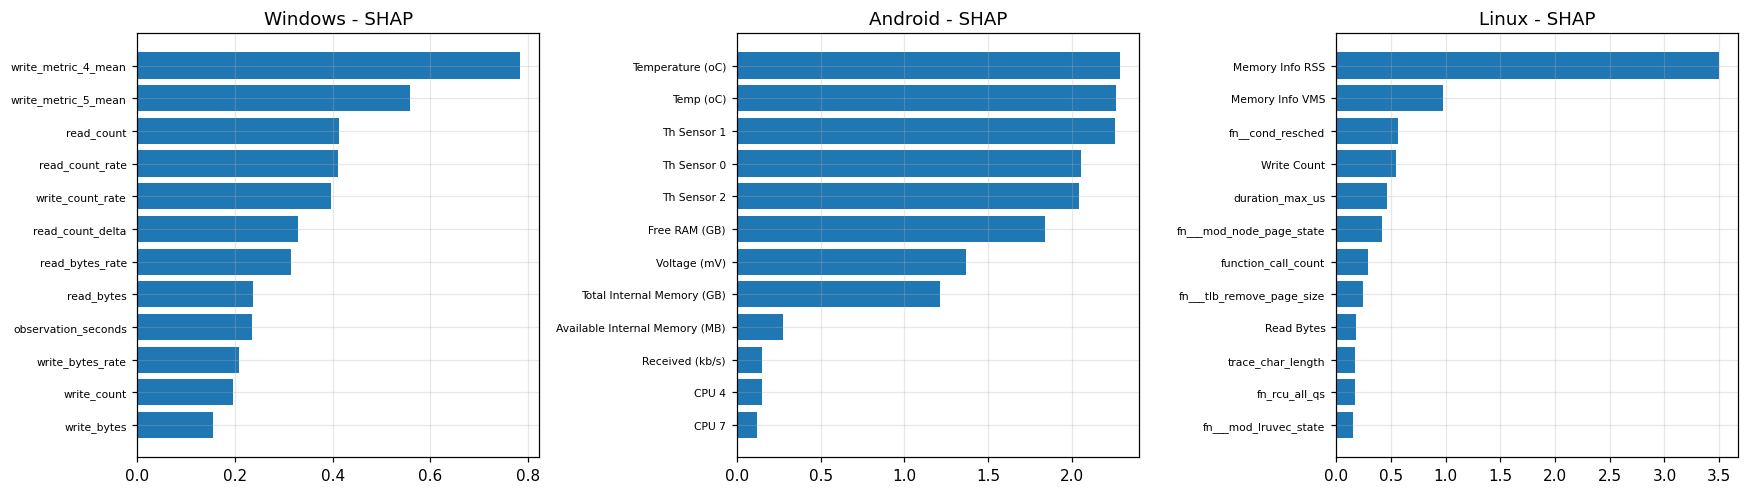

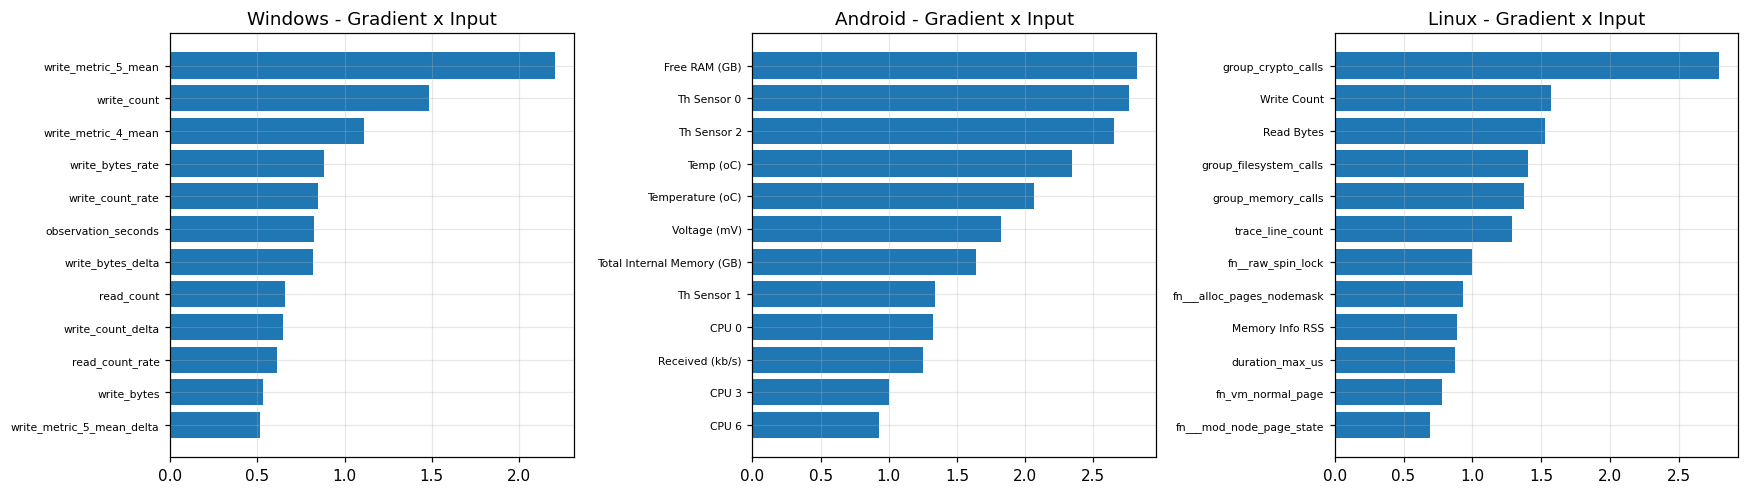

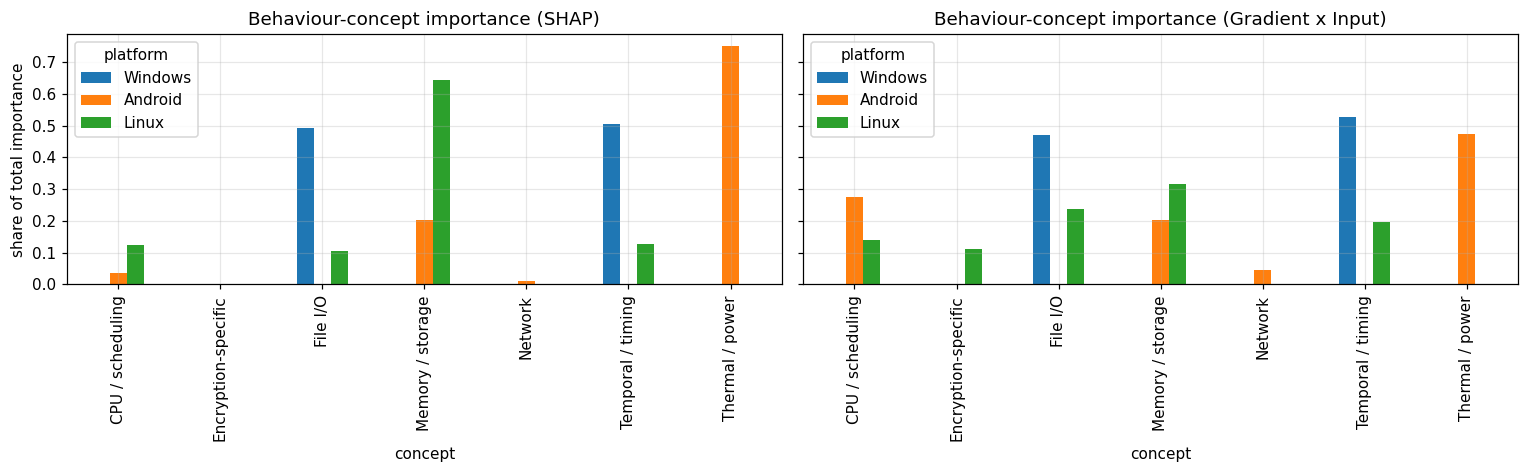

In [30]:
import matplotlib
matplotlib.use("Agg") if not "get_ipython" in globals() else None
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": 0.3})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show() if "get_ipython" in globals() else plt.close()


CONCEPT_RULES = [
    (r"crypto|aes|cipher|encrypt|decrypt|sha\d|chacha", "Encryption-specific"),
    (r"observation_seconds|_delta$|_rate$|duration|trace_|function_call|unique_function|line_count",
     "Temporal / timing"),
    (r"read|write|ext4|vfs|inode|dentry|filemap|writeback|filesystem|io_", "File I/O"),
    (r"cpu|frequency|sched|resched|rcu|lock|mutex|context", "CPU / scheduling"),
    (r"ram|memory|memcg|page|alloc|lru|rmap|vma|storage|vmstat|rss|vms|numa|mod_node|tlb|freelist",
     "Memory / storage"),
    (r"received|transmitted|network|net_|packet", "Network"),
    (r"voltage|temp|th sensor|thermal", "Thermal / power"),
]


def concept_of(feature):
    f = feature.lower()
    for pat, name in CONCEPT_RULES:
        if re.search(pat, f):
            return name
    return "Other"


def shap_importance(variant, max_rows=300):
    k = KEEP[(variant, "XGBoost")]
    X = k["d"]["Xte"]
    X = X[np.random.RandomState(SEED).choice(len(X), min(max_rows, len(X)), replace=False)]
    feats = k["d"]["features"]
    try:
        import shap
        sv = shap.TreeExplainer(k["model"]).shap_values(X)
        sv = sv[1] if isinstance(sv, list) else sv
        imp = np.abs(sv).mean(0)
        method = "SHAP"
    except Exception as e:                                         # shap missing: fall back to gain importance
        print(f"[{variant}] SHAP unavailable ({type(e).__name__}); using XGBoost gain importance")
        imp = k["model"].feature_importances_
        method = "XGB gain"
    return pd.DataFrame(dict(platform=variant.split("_")[0], variant=variant, feature=feats, importance=imp,
                             method=method))


def gxi_importance(max_rows=300):
    """Gradient x Input: mean |x * d logit / d x| over test rows, from the federated multi-task network."""
    kk = XP_KEEP[("primary", "FedAvg (full)")]
    out = []
    for n, net in kk["nets"].items():
        X = kk["data"][n]["Xte"]
        X = X[np.random.RandomState(SEED).choice(len(X), min(max_rows, len(X)), replace=False)]
        logit, cache = net.forward(X)
        _, dX = net.backward(cache, np.ones(len(X), np.float32))
        attr = np.abs(X * dX).mean(0)
        for f, a in zip(kk["data"][n]["features"], attr):
            out.append(dict(platform=n, feature=f, importance=float(a), method="Gradient x Input"))
    return pd.DataFrame(out)


primary_variants = ["Windows", PRIMARY_ANDROID, "Linux"]
shap_df = pd.concat([shap_importance(v) for v in primary_variants], ignore_index=True)
gxi_df = gxi_importance()
xai = pd.concat([shap_df.drop(columns="variant"), gxi_df], ignore_index=True)
xai["concept"] = xai["feature"].map(concept_of)
xai["importance_norm"] = xai.groupby(["platform", "method"])["importance"].transform(lambda s: s / max(s.sum(), 1e-12))
save_csv(xai, "06_feature_importance_all.csv")

concept = (xai.groupby(["platform", "method", "concept"])["importance_norm"].sum().reset_index())
save_csv(concept, "06_concept_importance.csv")
show(concept.pivot_table(index=["method", "concept"], columns="platform", values="importance_norm").round(3))

# figures: top-12 features per platform and method, then concept comparison
for method in xai.method.unique():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for ax, plat in zip(axes, PLATFORMS):
        t = xai[(xai.method == method) & (xai.platform == plat)].nlargest(12, "importance").iloc[::-1]
        ax.barh(t["feature"], t["importance"])
        ax.set_title(f"{plat} - {method}")
        ax.tick_params(axis="y", labelsize=7)
    savefig(f"fig_xai_top_features_{method.replace(' ', '_')}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, method in zip(axes, ["SHAP" if (xai.method == "SHAP").any() else "XGB gain", "Gradient x Input"]):
    pv = concept[concept.method == method].pivot_table(index="concept", columns="platform",
                                                       values="importance_norm").fillna(0)
    pv[[p for p in PLATFORMS if p in pv.columns]].plot.bar(ax=ax)
    ax.set_title(f"Behaviour-concept importance ({method})")
    ax.set_ylabel("share of total importance")
savefig("fig_xai_concept_comparison")

## 8b. Validating the explanations (stability, agreement, faithfulness, necessity)
Producing a SHAP plot is not evidence that the explanation is *right*. Four tests turn the explanations into measured claims:

| Test | Question | Pass rule (stated before looking) |
|---|---|---|
| Stability | Do 5 retrainings (different seeds / splits) rank features the same way? | mean Spearman rho >= 0.7 |
| Agreement | Do SHAP, permutation importance (test AUC drop) and Gradient x Input agree? | SHAP-permutation rho >= 0.5 |
| Faithfulness (deletion) | Does removing the features an explanation calls important hurt the model *more than removing random features*? | mean AUC-drop gap (top-k minus random-k) >= 0.02 |
| Necessity (concept ablation) | Does retraining *without* a behaviour concept hurt? | reported only; **no drop = redundancy, not unimportance** |

Deletion sets a feature to its training mean (0 in the standardised space).

In [31]:
from scipy.stats import spearmanr

STAB_RHO, AGREE_RHO, FAITH_GAP = 0.7, 0.5, 0.02


def imp_vector(model, X):
    try:
        import shap
        sv = shap.TreeExplainer(model).shap_values(X)
        sv = sv[1] if isinstance(sv, list) else sv
        sv = np.asarray(sv)
        if sv.ndim == 3:
            sv = sv[..., -1]
        return np.abs(sv).mean(0), "SHAP"
    except Exception:
        return np.asarray(model.feature_importances_, float), "XGB gain"


def _rho(a, b):
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan
    return float(spearmanr(a, b)[0])


def deletion_gap(predict, X, y, ranking, ks, n_random, rs):
    base = roc_auc_score(y, predict(X))
    rows, F = [], X.shape[1]
    for k in ks:
        k = min(k, F)
        Xd = X.copy()
        Xd[:, ranking[:k]] = 0.0
        top = base - roc_auc_score(y, predict(Xd))
        rnd = []
        for _ in range(n_random):
            Xr = X.copy()
            Xr[:, rs.choice(F, k, replace=False)] = 0.0
            rnd.append(base - roc_auc_score(y, predict(Xr)))
        rows.append(dict(k=k, auc_drop_top_k=top, auc_drop_random_k=float(np.mean(rnd)), gap=top - float(np.mean(rnd))))
    return pd.DataFrame(rows)


stab_rows, agree_rows, faith_rows, imp_store = [], [], [], {}
KS = [1, 2, 3, 5, 8]
for plat, variant in PLAT_VARIANT.items():
    feats = VARIANTS[variant]
    vecs, method = [], "SHAP"
    for seed in SEEDS:
        d = get_data(variant, seed)
        m = make_model("XGBoost", seed, d["ytr"])
        m.fit(d["Xtr"], d["ytr"])
        te = d["te"]
        idx = np.random.RandomState(0).choice(len(te), min(300, len(te)), replace=False)
        v, method = imp_vector(m, d["prep"].transform(te.iloc[idx]))
        vecs.append(v)
    V = np.vstack(vecs)
    pairs = list(combinations(range(len(V)), 2))
    rho = [_rho(V[i], V[j]) for i, j in pairs]
    top5 = [set(np.argsort(-V[i])[:5]) for i in range(len(V))]
    jac = [len(top5[i] & top5[j]) / len(top5[i] | top5[j]) for i, j in pairs]
    stab_rows.append(dict(platform=plat, method=method, seeds=len(V),
                          mean_spearman=float(np.nanmean(rho)) if pairs else np.nan,
                          min_spearman=float(np.nanmin(rho)) if pairs else np.nan,
                          mean_top5_jaccard=float(np.mean(jac)) if pairs else np.nan))

    # --- agreement + faithfulness on the seed-0 model
    k0 = KEEP[(variant, "XGBoost")]
    d0, m0 = k0["d"], k0["model"]
    rs = np.random.RandomState(SEED)
    n_s = min(20000, len(d0["Xte"]))
    for _try in range(20):                                              # sample with both classes present
        sel = rs.choice(len(d0["Xte"]), n_s, replace=False)
        if len(np.unique(d0["yte"][sel])) == 2:
            break
    Xs, ys = d0["Xte"][sel], d0["yte"][sel]
    predx = lambda X_: m0.predict_proba(X_)[:, 1]
    base_auc = roc_auc_score(ys, predx(Xs))
    perm = np.zeros(Xs.shape[1])
    for j in range(Xs.shape[1]):
        drops = []
        for _ in range(PERM_REPEATS):
            Xp = Xs.copy()
            Xp[:, j] = rs.permutation(Xp[:, j])
            drops.append(base_auc - roc_auc_score(ys, predx(Xp)))
        perm[j] = np.mean(drops)
    shap_v = vecs[0]
    gx = gxi_df[gxi_df.platform == plat]["importance"].to_numpy()
    imp_store[plat] = dict(features=feats, shap=shap_v, perm=perm, gxi=gx)
    agree_rows.append(dict(platform=plat, SHAP_vs_permutation=_rho(shap_v, perm), SHAP_vs_GradxInput=_rho(shap_v, gx),
                           permutation_vs_GradxInput=_rho(perm, gx)))

    kk = XP_KEEP[("primary", "FedAvg (full)")]
    net, Xn, yn = kk["nets"][plat], kk["data"][plat]["Xte"], kk["data"][plat]["yte"]
    seln = rs.choice(len(Xn), min(n_s, len(Xn)), replace=False)
    if len(np.unique(yn[seln])) < 2:
        seln = np.arange(len(Xn))
    for name, ranking, fn, X_, y_ in [
            ("SHAP", np.argsort(-shap_v), predx, Xs, ys),
            ("Permutation", np.argsort(-perm), predx, Xs, ys),
            ("Gradient x Input (FedAvg net)", np.argsort(-gx), net.prob, Xn[seln], yn[seln])]:
        g_ = deletion_gap(fn, X_, y_, ranking, KS, RANDOM_DELETIONS, np.random.RandomState(SEED))
        g_.insert(0, "method", name)
        g_.insert(0, "platform", plat)
        faith_rows.append(g_)
    print(f"{plat}: explanation validation done")

xai_stab, xai_agree = pd.DataFrame(stab_rows), pd.DataFrame(agree_rows)
xai_faith = pd.concat(faith_rows, ignore_index=True)
save_csv(xai_stab, "06b_explanation_stability.csv")
save_csv(xai_agree, "06b_explanation_agreement.csv")
save_csv(xai_faith, "06b_explanation_faithfulness_deletion.csv")
show(xai_stab.round(3)); show(xai_agree.round(3))
faith_sum = xai_faith.groupby(["platform", "method"])[["auc_drop_top_k", "auc_drop_random_k", "gap"]].mean().round(4).reset_index()
faith_sum["faithful"] = faith_sum["gap"] >= FAITH_GAP
show(faith_sum)

# --- necessity / sufficiency of behaviour concepts (retrain without / with only the concept)
nec = []
for plat, variant in PLAT_VARIANT.items():
    feats = VARIANTS[variant]
    cmap = {f: concept_of(f) for f in feats}
    for cname in sorted(set(cmap.values())):
        in_c = [f for f in feats if cmap[f] == cname]
        out_c = [f for f in feats if cmap[f] != cname]
        for mode, fset in [("without concept", out_c), ("only concept", in_c)]:
            if len(fset) < 1:
                continue
            for seed in SEEDS[:3]:
                trn = get_data(variant, seed)
                pr = Prep(fset).fit(trn["tr"])
                ytr = trn["ytr"]
                m = make_model("XGBoost", seed, ytr)
                m.fit(pr.transform(trn["tr"]), ytr)
                pva, pte = m.predict_proba(pr.transform(trn["va"]))[:, 1], m.predict_proba(pr.transform(trn["te"]))[:, 1]
                r = bin_metrics(trn["yte"], pte, pick_threshold(trn["yva"], pva))
                nec.append(dict(platform=plat, concept=cname, mode=mode, n_features=len(fset), seed=seed,
                                AUC=r["AUC"], Recall=r["Recall"], FPR=r["FPR"], TPR10=r["TPR10"]))
nec = pd.DataFrame(nec)
save_csv(nec, "06b_concept_ablation_per_seed.csv")
ref = central[central.variant.isin(PLAT_VARIANT.values()) & (central.model == "XGBoost")].copy()
ref["platform"] = ref["variant"].str.split("_").str[0]
ref_auc = ref.groupby("platform")["AUC"].mean()
nec_sum = nec.groupby(["platform", "concept", "mode"])[["AUC", "TPR10"]].mean().round(4).reset_index()
nec_sum["AUC_change_vs_full_model"] = nec_sum.apply(lambda r: r["AUC"] - ref_auc[r["platform"]], axis=1).round(4)
save_csv(nec_sum, "06b_concept_ablation_summary.csv")
show(nec_sum)

# --- verdict table used by the claims matrix
verdict = []
for plat in PLATFORMS:
    s = xai_stab[xai_stab.platform == plat].iloc[0]
    a = xai_agree[xai_agree.platform == plat].iloc[0]
    f = faith_sum[(faith_sum.platform == plat)]
    top_concept = (concept[(concept.platform == plat) & (concept.method == ("SHAP" if (xai.method == "SHAP").any() else "XGB gain"))]
                   .sort_values("importance_norm", ascending=False).head(1))
    tc = top_concept["concept"].iloc[0] if len(top_concept) else None
    tc_drop = nec_sum[(nec_sum.platform == plat) & (nec_sum.concept == tc) & (nec_sum["mode"] == "without concept")]["AUC_change_vs_full_model"]
    verdict.append(dict(platform=plat,
                        stable=bool(s["mean_spearman"] >= STAB_RHO) if not np.isnan(s["mean_spearman"]) else False,
                        mean_spearman=s["mean_spearman"],
                        methods_agree=bool(a["SHAP_vs_permutation"] >= AGREE_RHO) if not np.isnan(a["SHAP_vs_permutation"]) else False,
                        shap_vs_perm_rho=a["SHAP_vs_permutation"],
                        shap_faithful=bool(f[f.method == "SHAP"]["faithful"].iloc[0]),
                        gxi_faithful=bool(f[f.method.str.startswith("Gradient")]["faithful"].iloc[0]),
                        top_concept_by_shap=tc,
                        auc_change_when_top_concept_removed=float(tc_drop.iloc[0]) if len(tc_drop) else np.nan))
xai_verdict = pd.DataFrame(verdict)
xai_verdict["explanation_validated"] = xai_verdict["stable"] & xai_verdict["methods_agree"] & xai_verdict["shap_faithful"]
save_csv(xai_verdict, "06b_explanation_verdict.csv")
show(xai_verdict.round(3))

Windows: explanation validation done
Android: explanation validation done
Linux: explanation validation done


,platform,method,seeds,mean_spearman,min_spearman,mean_top5_jaccard
0,Windows,SHAP,5,0.959,0.923,0.867
1,Android,SHAP,5,0.994,0.986,1.000
2,Linux,SHAP,5,0.927,0.891,0.671


,platform,SHAP_vs_permutation,SHAP_vs_GradxInput,permutation_vs_GradxInput
0,Windows,0.955,0.626,0.603
1,Android,0.905,0.715,0.773
2,Linux,0.479,0.186,0.279


,platform,method,auc_drop_top_k,auc_drop_random_k,gap,faithful
0,Android,Gradient x Input (FedAvg net),0.0950,0.0054,0.0896,True
1,Android,Permutation,0.0826,0.0018,0.0808,True
2,Android,SHAP,0.0826,0.0018,0.0808,True
3,Linux,Gradient x Input (FedAvg net),0.1840,0.0217,0.1623,True
4,Linux,Permutation,0.4934,0.0220,0.4714,True
5,Linux,SHAP,0.3375,0.0220,0.3155,True
6,Windows,Gradient x Input (FedAvg net),0.2945,0.1537,0.1408,True
7,Windows,Permutation,0.1697,0.0528,0.1169,True
8,Windows,SHAP,0.1545,0.0528,0.1018,True


,platform,concept,mode,AUC,TPR10,AUC_change_vs_full_model
0,Android,CPU / scheduling,only concept,0.7668,0.3698,-0.2332
1,Android,CPU / scheduling,without concept,1.0000,1.0000,0.0000
2,Android,Memory / storage,only concept,0.9912,0.9770,-0.0088
3,Android,Memory / storage,without concept,1.0000,0.9999,0.0000
4,Android,Network,only concept,0.6921,0.3715,-0.3079
5,Android,Network,without concept,1.0000,1.0000,0.0000
6,Android,Thermal / power,only concept,1.0000,0.9999,0.0000
7,Android,Thermal / power,without concept,0.9947,0.9871,-0.0053
8,Linux,CPU / scheduling,only concept,0.9132,0.7733,-0.0818
9,Linux,CPU / scheduling,without concept,0.9977,1.0000,0.0027


,platform,stable,mean_spearman,methods_agree,shap_vs_perm_rho,shap_faithful,gxi_faithful,top_concept_by_shap,auc_change_when_top_concept_removed,explanation_validated
0,Windows,True,0.959,True,0.955,True,True,Temporal / timing,-0.012,True
1,Android,True,0.994,True,0.905,True,True,Thermal / power,-0.005,True
2,Linux,True,0.927,False,0.479,True,True,Memory / storage,-0.137,False


## 9. Figures: early-stage, cross-platform comparison, federated convergence

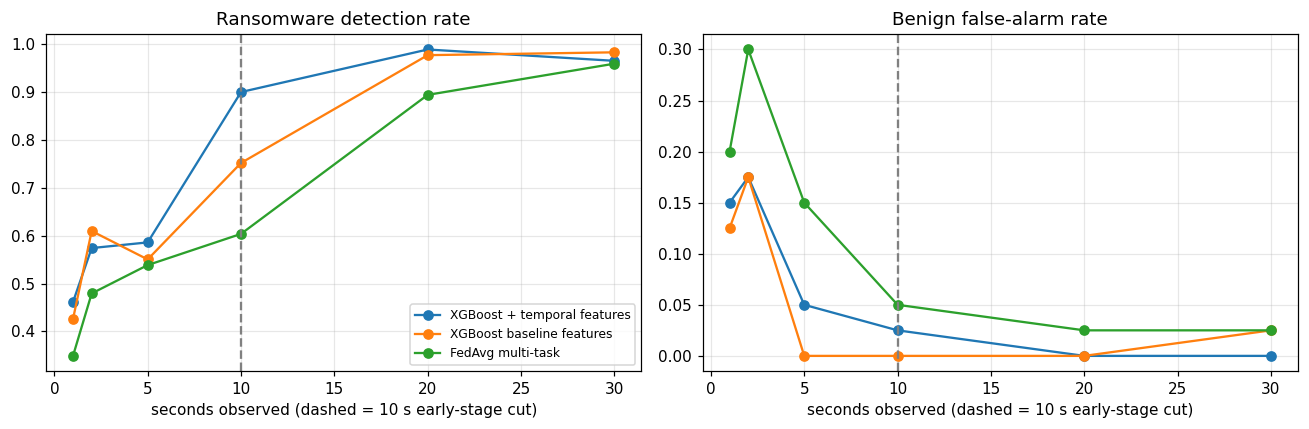

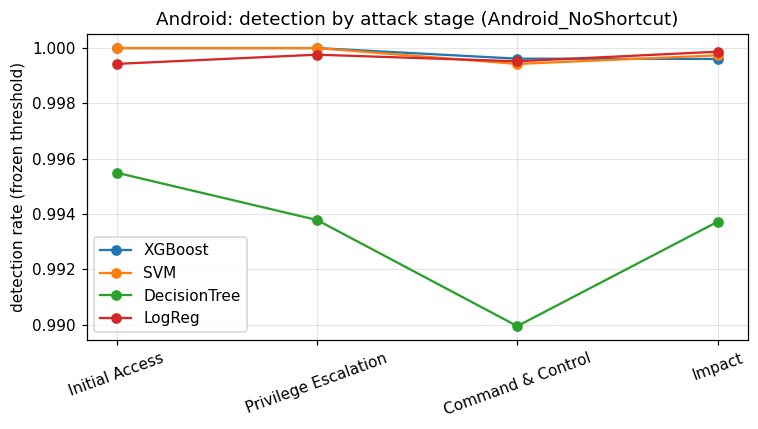

platform,Android,Linux,Windows
method,,,
Centralised DecisionTree,0.9991,0.9905,0.8421
Centralised LogReg,0.9998,0.4211,0.7064
Centralised SVM,0.9999,0.7718,0.8757
Centralised XGBoost,1.0000,0.9950,0.9365
Federated XGBoost,1.0000,1.0000,0.9142
Local-only XGBoost (mean of clients),1.0000,0.9312,0.8764
NN FedAvg (full),1.0000,0.9038,0.8975
NN Local-only (no aggregation),1.0000,0.8453,0.9232


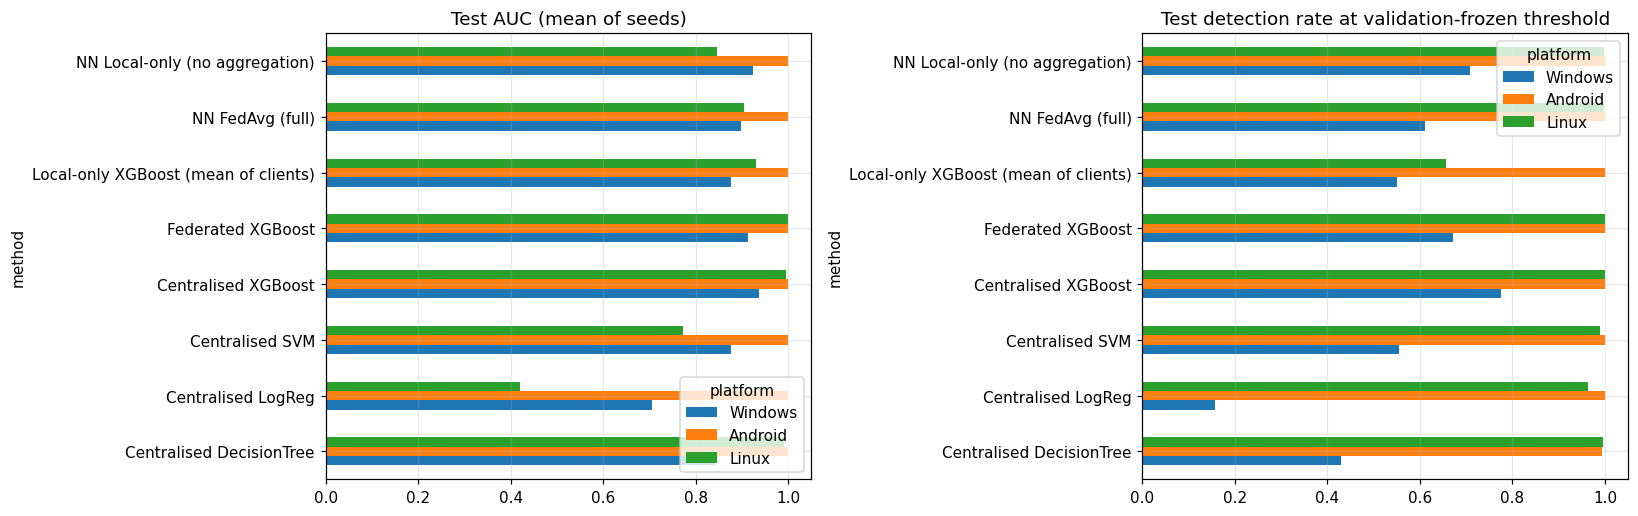

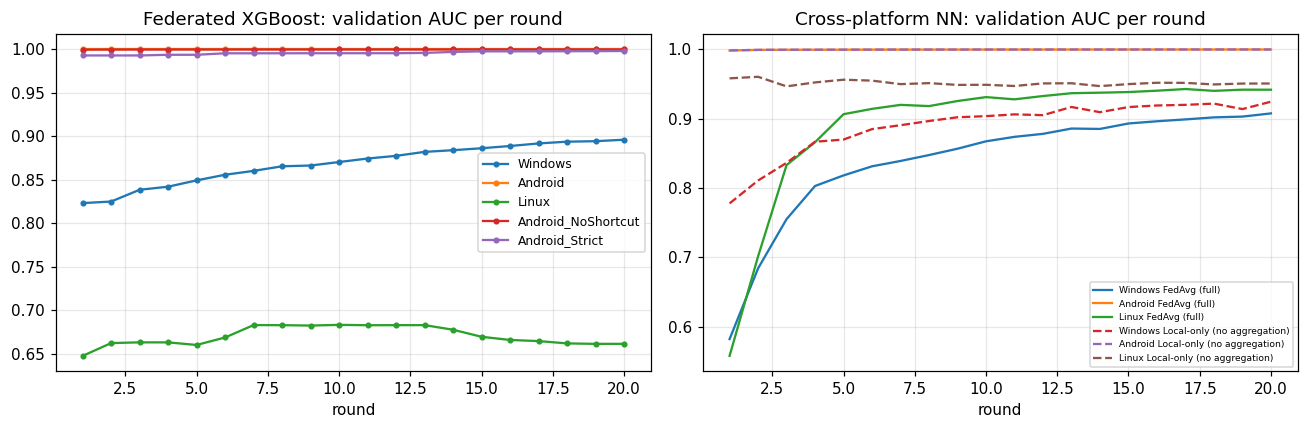

In [32]:
# Fig A: Windows early-stage (recall at <=10% FPR budget and the real FPR) vs observation time
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, sub in [("XGBoost + temporal features", win_early[(win_early.variant == "Windows") & (win_early.model == "XGBoost")]),
                   ("XGBoost baseline features", win_early[(win_early.variant == "Windows_Base7") & (win_early.model == "XGBoost")]),
                   ("FedAvg multi-task", fed_win_early)]:
    axes[0].plot(sub["observed_seconds"], sub["Recall"], marker="o", label=label)
    axes[1].plot(sub["observed_seconds"], sub["FPR"], marker="o", label=label)
for ax, t in zip(axes, ["Ransomware detection rate", "Benign false-alarm rate"]):
    ax.axvline(10, ls="--", c="grey")
    ax.set_xlabel("seconds observed (dashed = 10 s early-stage cut)")
    ax.set_title(t)
axes[0].legend(fontsize=8)
savefig("fig_windows_early_stage")

# Fig B: Android stage-resolved recall
fig, ax = plt.subplots(figsize=(7, 4))
for m in MODEL_KINDS:
    s = and_early[(and_early.variant == PRIMARY_ANDROID) & (and_early.model == m) & (and_early.stage > 0)]
    ax.plot(s["stage_name"], s["recall"], marker="o", label=m)
ax.set_ylabel("detection rate (frozen threshold)")
ax.set_title(f"Android: detection by attack stage ({PRIMARY_ANDROID})")
ax.tick_params(axis="x", rotation=20)
ax.legend()
savefig("fig_android_stage_detection")

# Fig C: all methods per platform (AUC and Recall @ <=10% FPR budget)
comp = []
for v in primary_variants:
    plat = v.split("_")[0]
    for m in MODEL_KINDS:
        s = central[(central.variant == v) & (central.model == m)]
        comp.append(dict(platform=plat, method=f"Centralised {m}", AUC=s.AUC.mean(), Recall=s.Recall.mean(), FPR=s.FPR.mean()))
    for m in ["Federated XGBoost", "Local-only XGBoost (mean of clients)"]:
        s = fedxgb[(fedxgb.variant == v) & (fedxgb.method == m)]
        comp.append(dict(platform=plat, method=m, AUC=s.AUC.mean(), Recall=s.Recall.mean(), FPR=s.FPR.mean()))
    for m in ["FedAvg (full)", "Local-only (no aggregation)"]:
        s = xp[(xp.set == "primary") & (xp.platform == plat) & (xp.method == m)]
        comp.append(dict(platform=plat, method=f"NN {m}", AUC=s.AUC.mean(), Recall=s.Recall.mean(), FPR=s.FPR.mean()))
comp = pd.DataFrame(comp).round(4)
save_csv(comp, "07_all_methods_comparison.csv")
show(comp.pivot_table(index="method", columns="platform", values="AUC"))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
comp.pivot_table(index="method", columns="platform", values="AUC")[PLATFORMS].plot.barh(ax=axes[0])
comp.pivot_table(index="method", columns="platform", values="Recall")[PLATFORMS].plot.barh(ax=axes[1])
axes[0].set_title("Test AUC (mean of seeds)")
axes[1].set_title("Test detection rate at validation-frozen threshold")
savefig("fig_all_methods_comparison")

# Fig D: federated convergence
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for v in [x for x in VARIANTS if x != "Windows_Base7"]:
    s = fedxgb_hist[fedxgb_hist.variant == v]
    axes[0].plot(s["round"], s["val_AUC"], marker=".", label=v)
axes[0].set_title("Federated XGBoost: validation AUC per round")
axes[0].set_xlabel("round")
axes[0].legend(fontsize=8)
h = xp_hist[(xp_hist.set == "primary")]
for method in ["FedAvg (full)", "Local-only (no aggregation)"]:
    s = h[h.method == method]
    for plat in PLATFORMS:
        axes[1].plot(s["round"], s[f"{plat}_val_AUC"], ls="-" if "Fed" in method else "--", label=f"{plat} {method}")
axes[1].set_title("Cross-platform NN: validation AUC per round")
axes[1].set_xlabel("round")
axes[1].legend(fontsize=6)
savefig("fig_federated_convergence")

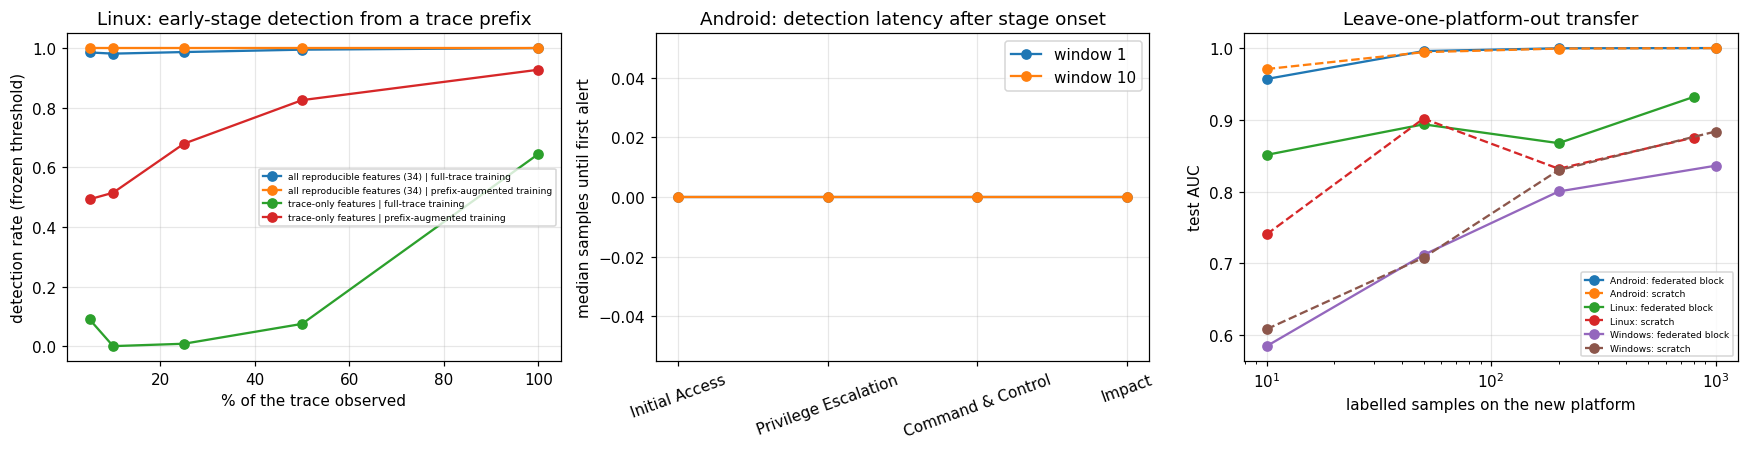

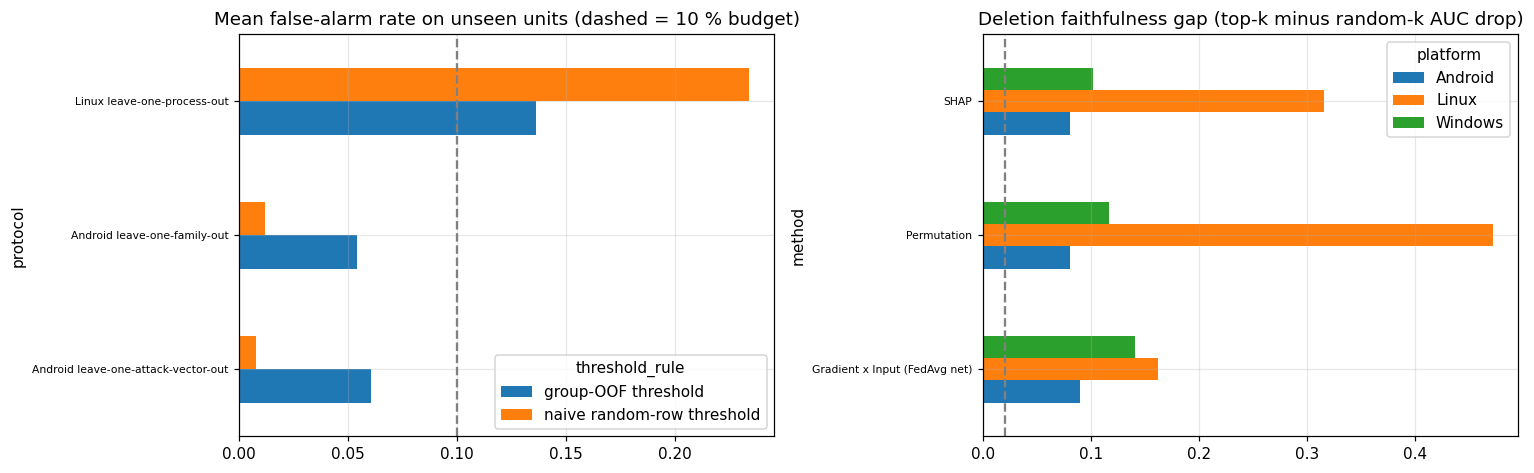

In [33]:
# Fig E: Linux early-stage (trace prefix) and Android detection latency
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
if lin_prefix_res is not None:
    for (fs, rg), g in lin_prefix_res.groupby(["features", "regime"]):
        s = g.groupby("prefix_frac")[["Recall", "FPR"]].mean()
        axes[0].plot(100 * s.index, s["Recall"], marker="o", label=f"{fs} | {rg}")
    axes[0].set_xlabel("% of the trace observed"); axes[0].set_ylabel("detection rate (frozen threshold)")
    axes[0].set_title("Linux: early-stage detection from a trace prefix"); axes[0].legend(fontsize=6)
else:
    axes[0].text(0.5, 0.5, "Linux prefix file not available", ha="center"); axes[0].set_axis_off()
for w in (1, 10):
    s = and_latency[(and_latency.variant == PRIMARY_ANDROID) & (and_latency.smoothing_window == w) & (and_latency.stage > 0)]
    axes[1].plot(s["stage_name"], s["median_latency_samples"], marker="o", label=f"window {w}")
axes[1].set_ylabel("median samples until first alert"); axes[1].set_title("Android: detection latency after stage onset")
axes[1].tick_params(axis="x", rotation=20); axes[1].legend()
sl = lopt_sum[lopt_sum.method.str.startswith("NN")]
for (plat, meth), g in sl.groupby(["held_out_platform", "method"]):
    axes[2].plot(g["shots"], g["AUC_mean"], marker="o", ls="-" if "frozen" in meth else "--", label=f"{plat}: {'federated block' if 'frozen' in meth else 'scratch'}")
axes[2].set_xscale("log"); axes[2].set_xlabel("labelled samples on the new platform"); axes[2].set_ylabel("test AUC")
axes[2].set_title("Leave-one-platform-out transfer"); axes[2].legend(fontsize=6)
savefig("fig_early_latency_transfer")

# Fig F: generalisation overview + explanation faithfulness
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
go = gen_overview.pivot_table(index="protocol", columns="threshold_rule", values="FPR_mean")
go.plot.barh(ax=axes[0]); axes[0].axvline(MAX_FPR, ls="--", c="grey")
axes[0].set_title("Mean false-alarm rate on unseen units (dashed = 10 % budget)"); axes[0].tick_params(axis="y", labelsize=7)
fp = xai_faith.groupby(["platform", "method"])["gap"].mean().unstack(0)
fp.plot.barh(ax=axes[1]); axes[1].axvline(FAITH_GAP, ls="--", c="grey")
axes[1].set_title("Deletion faithfulness gap (top-k minus random-k AUC drop)"); axes[1].tick_params(axis="y", labelsize=7)
savefig("fig_generalisation_faithfulness")

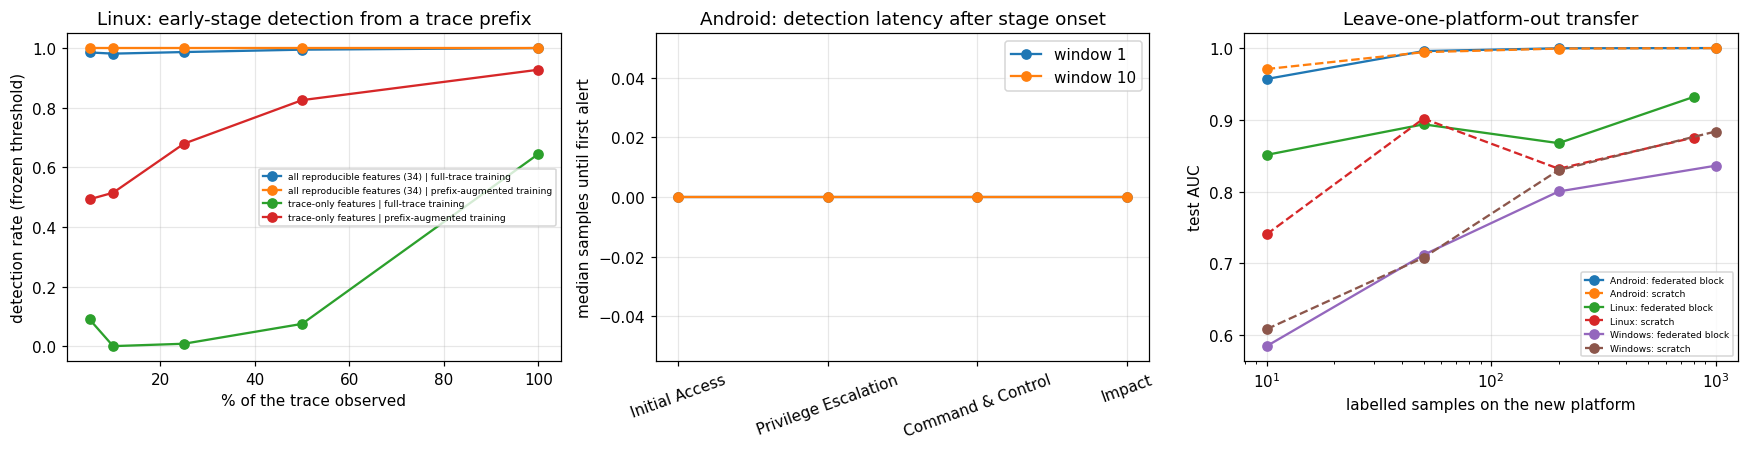

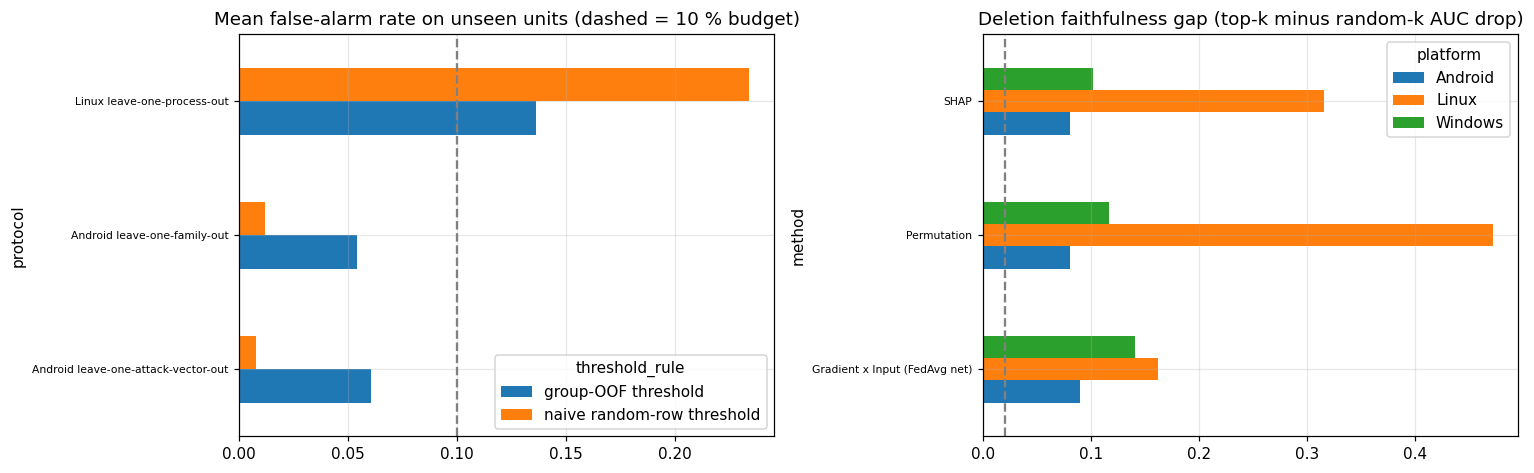

In [34]:
# Fig E: Linux early-stage (trace prefix) and Android detection latency
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
if lin_prefix_res is not None:
    for (fs, rg), g in lin_prefix_res.groupby(["features", "regime"]):
        s = g.groupby("prefix_frac")[["Recall", "FPR"]].mean()
        axes[0].plot(100 * s.index, s["Recall"], marker="o", label=f"{fs} | {rg}")
    axes[0].set_xlabel("% of the trace observed"); axes[0].set_ylabel("detection rate (frozen threshold)")
    axes[0].set_title("Linux: early-stage detection from a trace prefix"); axes[0].legend(fontsize=6)
else:
    axes[0].text(0.5, 0.5, "Linux prefix file not available", ha="center"); axes[0].set_axis_off()
for w in (1, 10):
    s = and_latency[(and_latency.variant == PRIMARY_ANDROID) & (and_latency.smoothing_window == w) & (and_latency.stage > 0)]
    axes[1].plot(s["stage_name"], s["median_latency_samples"], marker="o", label=f"window {w}")
axes[1].set_ylabel("median samples until first alert"); axes[1].set_title("Android: detection latency after stage onset")
axes[1].tick_params(axis="x", rotation=20); axes[1].legend()
sl = lopt_sum[lopt_sum.method.str.startswith("NN")]
for (plat, meth), g in sl.groupby(["held_out_platform", "method"]):
    axes[2].plot(g["shots"], g["AUC_mean"], marker="o", ls="-" if "frozen" in meth else "--", label=f"{plat}: {'federated block' if 'frozen' in meth else 'scratch'}")
axes[2].set_xscale("log"); axes[2].set_xlabel("labelled samples on the new platform"); axes[2].set_ylabel("test AUC")
axes[2].set_title("Leave-one-platform-out transfer"); axes[2].legend(fontsize=6)
savefig("fig_early_latency_transfer")

# Fig F: generalisation overview + explanation faithfulness
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
go = gen_overview.pivot_table(index="protocol", columns="threshold_rule", values="FPR_mean")
go.plot.barh(ax=axes[0]); axes[0].axvline(MAX_FPR, ls="--", c="grey")
axes[0].set_title("Mean false-alarm rate on unseen units (dashed = 10 % budget)"); axes[0].tick_params(axis="y", labelsize=7)
fp = xai_faith.groupby(["platform", "method"])["gap"].mean().unstack(0)
fp.plot.barh(ax=axes[1]); axes[1].axvline(FAITH_GAP, ls="--", c="grey")
axes[1].set_title("Deletion faithfulness gap (top-k minus random-k AUC drop)"); axes[1].tick_params(axis="y", labelsize=7)
savefig("fig_generalisation_faithfulness")

## 10. Operating-point audit and claims-evidence matrix
**10a. Threshold transfer.** The alert threshold is frozen on validation data. A detector is only deployable if the false-alarm rate
it produces on *test* data stays near the 10 % budget it was calibrated for.

In [35]:
# ---- 11a. threshold-transfer audit (validation-frozen threshold -> test false-alarm rate)
ta = []
for v in PRIMARY:
    for lab, df_ in [("Centralised XGBoost", central[(central.variant == v) & (central.model == "XGBoost")]),
                     ("Federated XGBoost", fedxgb[(fedxgb.variant == v) & (fedxgb.method == "Federated XGBoost")]),
                     ("FedAvg NN (cross-platform)", xp[(xp.set == "primary") & (xp.platform == v.split("_")[0]) & (xp.method == "FedAvg (full)")]),
                     ("Equal-effort tuned XGBoost", tuned[(tuned.variant == v) & (tuned.model == "XGBoost")])]:
        if len(df_):
            ta.append(dict(platform=v, method=lab, test_FPR=df_["FPR"].mean(), target_FPR=MAX_FPR,
                           gap=df_["FPR"].mean() - MAX_FPR, test_recall=df_["Recall"].mean(), oracle_TPR_at_10pct_FPR=df_["TPR10"].mean()))
thr_audit = pd.DataFrame(ta)
thr_audit["flag"] = thr_audit["gap"] > 0.05
save_csv(thr_audit.round(4), "09_threshold_transfer_audit.csv")
show(thr_audit.round(3))

,platform,method,test_FPR,target_FPR,gap,test_recall,oracle_TPR_at_10pct_FPR,flag
0,Windows,Centralised XGBoost,0.099,0.1,-0.001,0.776,0.774,False
1,Windows,Federated XGBoost,0.085,0.1,-0.015,0.672,0.699,False
2,Windows,FedAvg NN (cross-platform),0.094,0.1,-0.006,0.612,0.615,False
3,Windows,Equal-effort tuned XGBoost,0.082,0.1,-0.018,0.776,0.815,False
4,Android_NoShortcut,Centralised XGBoost,0.000,0.1,-0.100,1.000,1.000,False
5,Android_NoShortcut,Federated XGBoost,0.028,0.1,-0.072,1.000,1.000,False
6,Android_NoShortcut,FedAvg NN (cross-platform),0.083,0.1,-0.017,1.000,1.000,False
7,Android_NoShortcut,Equal-effort tuned XGBoost,0.000,0.1,-0.100,1.000,1.000,False
8,Linux,Centralised XGBoost,0.090,0.1,-0.010,1.000,1.000,False
9,Linux,Federated XGBoost,0.998,0.1,0.898,1.000,1.000,True


**10b. Claims-evidence matrix** (status is **computed from the tables above, not typed in**)
Each row restates one research component, the status you assigned before this revision, and the status the evidence now
supports. A component is marked *established* only when its numeric rule is met; otherwise the matrix says what failed.
Rules are fixed in the code (`EARLY_RECALL_TARGET`, `EARLY_FPR_LIMIT`, `STAB_RHO`, ...) and printed with the table.

In [36]:
def G(name, default=None):
    return globals().get(name, default)


def safe(fn):
    try:
        return fn()
    except Exception as e:
        return ("Could not be computed", f"{type(e).__name__}: {e}", "check the upstream cell")


CLAIMS = []

# ---- 1. datasets
def _c1():
    s = summary.set_index("platform")
    ev = "; ".join(f"{p}: {int(s.loc[p, 'features'])} features, {int(s.loc[p, 'train_rows'] + s.loc[p, 'val_rows'] + s.loc[p, 'test_rows'])} rows" for p in PLATFORMS)
    return "Established", ev, "Each platform has a different label semantics (see limitations); no common benign-software class across platforms."
CLAIMS.append(("Three heterogeneous datasets", "Implemented") + safe(_c1))

# ---- 2. explainability
def _c2():
    v = xai_verdict
    n = int(v["explanation_validated"].sum())
    ev = "; ".join(f"{r.platform}: stability rho={r.mean_spearman:.2f}, SHAP~permutation rho={r.shap_vs_perm_rho:.2f}, "
                   f"SHAP deletion faithful={r.shap_faithful}, removing top concept ({r.top_concept_by_shap}) changes AUC by "
                   f"{r.auc_change_when_top_concept_removed:+.3f}" for r in v.itertuples())
    status = ("Established (validated on all 3 platforms)" if n == 3 else
              f"Partly validated ({n}/3 platforms pass stability + agreement + faithfulness)" if n else
              "Not validated - report explanations as descriptions of the model, not of ransomware behaviour")
    redundant = [r.platform for r in v.itertuples() if abs(r.auc_change_when_top_concept_removed) < 0.01]
    rem = ((f"On {', '.join(redundant)} the top concept can be removed with <0.01 AUC change: its importance reflects redundancy among correlated features, not necessity - say so. "
            if redundant else "") + "Report SHAP and Gradient x Input side by side; they rank features differently (06_concept_importance.csv).")
    return status, ev, rem
CLAIMS.append(("Explainability", "Implemented; interpretation needs validation") + safe(_c2))

# ---- 3. federated xgboost
def _c3():
    s = fedxgb.groupby(["variant", "method"])["AUC"].mean().unstack()
    rows, close, beat = [], 0, 0
    for plat, v in PLAT_VARIANT.items():
        f, c, l = s.loc[v, "Federated XGBoost"], s.loc[v, "Centralised XGBoost"], s.loc[v, "Local-only XGBoost (mean of clients)"]
        close += int(c - f <= 0.02)
        beat += int(f - l > 0.0)
        rows.append(f"{plat}: federated {f:.3f} / centralised {c:.3f} / local-only {l:.3f} AUC")
    fpr = fedxgb[fedxgb.method == "Federated XGBoost"].groupby("variant")["FPR"].mean()
    bad = [v for v in PLAT_VARIANT.values() if fpr.get(v, 0) > MAX_FPR + 0.10]
    status = f"Established as a method; within 0.02 AUC of centralised on {close}/3 and above local-only on {beat}/3 platforms"
    rem = ("Threshold does not transfer on: " + ", ".join(bad) + " (test FPR far above the 10 % budget) - fix before claiming deployable operating points."
           if bad else "Operating points transfer within 10 points of the FPR budget.")
    return status, "; ".join(rows), rem
CLAIMS.append(("Federated XGBoost", "Implemented") + safe(_c3))

# ---- 4. cross-platform FedAvg
def _c4():
    d = pair[pair.metric == "AUC"].set_index("platform")["mean_diff_fedavg_minus_local"]
    g = lopt_gain[lopt_gain.shots <= 50].groupby("held_out_platform")["mean"].mean()
    better = [p for p in PLATFORMS if d.get(p, 0) > 0.005]
    transfer = [p for p in PLATFORMS if g.get(p, 0) > 0.02]
    ev = ("FedAvg minus local-only AUC: " + ", ".join(f"{p} {d[p]:+.3f}" for p in PLATFORMS) +
          " | frozen-shared-block minus scratch AUC (<=50 labels): " + ", ".join(f"{p} {g[p]:+.3f}" for p in g.index))
    if len(better) >= 2 and len(transfer) >= 2:
        st = "Established (FedAvg helps on >=2 platforms and the shared block transfers to >=2 unseen platforms)"
    elif better or transfer:
        st = f"Mixed - FedAvg helps on {better or 'no platform'}; shared block transfers to {transfer or 'no platform'}"
    else:
        st = "Implemented; no consistent benefit over local training shown"
    return st, ev, "Report negative/neutral results as they are; a cross-platform paper can still contribute the protocol and its honest evaluation."
CLAIMS.append(("Cross-platform neural FedAvg", "Implemented") + safe(_c4))

# ---- 5. early stage
def _c5():
    ok, ev = [], []
    w = win_early[(win_early.variant == "Windows") & (win_early.model == "XGBoost") & (win_early.observed_seconds == 10)].iloc[0]
    w5 = win_early[(win_early.variant == "Windows") & (win_early.model == "XGBoost") & (win_early.observed_seconds == 5)].iloc[0]
    okw = bool(w["Recall"] >= EARLY_RECALL_TARGET and w["FPR"] <= EARLY_FPR_LIMIT)
    ok.append(okw)
    dm = win_damage[(win_damage.variant == "Windows") & (win_damage.model == "XGBoost")].iloc[0]
    ev.append(f"Windows: recall {w['Recall']:.2f} at FPR {w['FPR']:.2f} after 10 s ({w5['Recall']:.2f} after 5 s); median {dm['median_share_of_bytes_already_written']:.0%} of the 30 s write volume already written at first alert")
    a = and_early[(and_early.variant == PRIMARY_ANDROID) & (and_early.model == "XGBoost")].set_index("stage")
    oka = bool(a.loc[1, "recall"] >= EARLY_RECALL_TARGET and a.loc[2, "recall"] >= EARLY_RECALL_TARGET and a.loc[0, "recall"] <= EARLY_FPR_LIMIT)
    ok.append(oka)
    lat = and_latency[(and_latency.variant == PRIMARY_ANDROID) & (and_latency.smoothing_window == 10) & (and_latency.stage == 1)].iloc[0]
    ev.append(f"Android: Initial-Access recall {a.loc[1, 'recall']:.2f}, Privilege-Escalation {a.loc[2, 'recall']:.2f}, clean-state false alarms {a.loc[0, 'recall']:.2f}; median latency {lat['median_latency_samples']} samples")
    if lin_prefix_res is not None:
        g = lin_prefix_res[(lin_prefix_res.features == "trace-only features") & (lin_prefix_res.regime == "prefix-augmented training")].groupby("prefix_frac")[["Recall", "FPR"]].mean()
        hit = g[(g.Recall >= EARLY_RECALL_TARGET) & (g.FPR <= EARLY_FPR_LIMIT)]
        okl = bool(len(hit) and hit.index.min() <= 0.25)
        ok.append(okl)
        ev.append("Linux (trace-only features, prefix-augmented): " + (f"target met from {hit.index.min():.0%} of the trace" if len(hit) else "target not met at any prefix"))
    else:
        ev.append("Linux: not measured (raw CSV unavailable)")
    n = sum(ok)
    st = (f"Measured on all 3 platforms; target (recall>={EARLY_RECALL_TARGET}, FPR<={EARLY_FPR_LIMIT}) met on {n}/3" if lin_prefix_res is not None
          else f"Measured on 2/3 platforms (Linux not measurable without raw data); target met on {n}/2")
    return st, "; ".join(ev), "Android 'early' is a stage proxy; Linux 'early' is a trace-fraction proxy, not seconds. State both in the paper."
CLAIMS.append(("Early-stage detection", "Partial") + safe(_c5))

# ---- 6. generalisable detection
def _c6():
    res, notes = {}, []
    h = hold[hold.observed_seconds == 30]
    h = h[h.threshold == ("group-oof" if (h.threshold == "group-oof").any() else "val")]
    hp = h.groupby("protocol")[["AUC", "Recall", "FPR"]].mean()
    res["Windows"] = bool(((hp.AUC >= 0.9) & (hp.Recall >= 0.8) & (hp.FPR <= 0.15)).all())
    notes.append("Windows (30 s, group-OOF threshold): " + ", ".join(f"{i}: recall {r.Recall:.2f}/FPR {r.FPR:.2f}" for i, r in hp.iterrows()))
    go_ = gen_overview[gen_overview.threshold_rule == "group-OOF threshold"].set_index("protocol")
    a = go_.loc[[i for i in go_.index if i.startswith("Android")]]
    res["Android"] = bool(((a.AUC_min >= 0.9) & (a.Recall_mean >= 0.8) & (a.FPR_mean <= 0.15)).all())
    notes.append("Android: " + ", ".join(f"{i.replace('Android ', '')}: AUC min {r.AUC_min:.2f}, recall {r.Recall_mean:.2f}, FPR {r.FPR_mean:.2f}" for i, r in a.iterrows()))
    l = go_.loc["Linux leave-one-process-out"]
    res["Linux"] = bool(l.Recall_mean >= 0.8 and l.FPR_mean <= 0.15)
    notes.append(f"Linux leave-one-process-out: recall {l.Recall_mean:.2f} (positive processes), FPR {l.FPR_mean:.2f} (negative processes)")
    n = sum(res.values())
    failing = [p for p, v in res.items() if not v]
    st = ("Established on all 3 platforms" if n == 3 else
          f"Not established on all platforms - holds on {n}/3 ({', '.join(p for p, v in res.items() if v) or 'none'}); fails on {', '.join(failing)}")
    rem = ("Android measures attack-in-progress vs the same device before infection (no benign-app class) - do not word it as "
           "'ransomware vs benign software'. Linux label is a function of the process, so held-out-process results are weak evidence.")
    return st, " | ".join(notes), rem
CLAIMS.append(("Generalizable ransomware detection", "Not yet established on all platforms") + safe(_c6))

# ---- 7. experimental comparisons
def _c7():
    checks = {
        "split/duplicate leakage audit": G("AUDIT_PASSED", 0) == G("AUDIT_TOTAL", -1),
        "label-shuffle control (AUC about 0.5)": bool(G("SHUFFLE_PASSED", False)),
        "equal-effort tuning of all 4 model families": "tuned" in globals(),
        "5 seeds (or the QUICK subset)": len(SEEDS) >= 5 or QUICK,
        "multiple-comparison correction (Holm)": "p_value_holm" in paired.columns,
        "cluster-bootstrap confidence intervals": "ci_df" in globals(),
        "threshold-transfer audit": True,
        "communication cost reported": "comm" in globals(),
    }
    n = sum(checks.values())
    win = G("TUNED_WINNER", {})
    sig = int(paired["significant_after_holm"].sum()) if "significant_after_holm" in paired.columns else 0
    ev = (f"{n}/{len(checks)} automated checks pass ({', '.join(k for k, v in checks.items() if not v) or 'none failing'}); "
          f"best model after equal tuning: {win}; {sig}/{len(paired)} paired-bootstrap comparisons significant after Holm")
    fp = G("thr_audit")
    bad = int((fp["flag"]).sum()) if fp is not None else 0
    return (f"Audited: {n}/{len(checks)} checks pass", ev,
            (f"{bad} method-platform operating points miss the 10 % FPR budget by >5 points on test (09_threshold_transfer_audit.csv) - discuss them in the paper. "
             if bad else "All audited operating points stay within 5 points of the 10 % FPR budget. ") +
            "Linux and Android splits are single fixed splits; the group-CV in 7f is the variance estimate for them.")
CLAIMS.append(("Experimental comparisons", "Substantial, but require further auditing") + safe(_c7))

claims = pd.DataFrame(CLAIMS, columns=["component", "assessment_before", "status_now", "evidence", "what_remains"])
save_csv(claims, "08_claims_evidence_matrix.csv")
pd.set_option("display.max_colwidth", 400)
show(claims[["component", "assessment_before", "status_now"]])
for r in claims.itertuples():
    print(f"\n[{r.component}]\n  before : {r.assessment_before}\n  now    : {r.status_now}\n  evidence: {r.evidence}\n  remains: {r.what_remains}")

,component,assessment_before,status_now
0,Three heterogeneous datasets,Implemented,Established
1,Explainability,Implemented; interpretation needs validation,Partly validated (2/3 platforms pass stability + agreement + faithfulness)
2,Federated XGBoost,Implemented,Established as a method; within 0.02 AUC of centralised on 2/3 and above local-only on 3/3 platforms
3,Cross-platform neural FedAvg,Implemented,Mixed - FedAvg helps on ['Linux']; shared block transfers to ['Linux']
4,Early-stage detection,Partial,"Measured on all 3 platforms; target (recall>=0.8, FPR<=0.15) met on 2/3"
5,Generalizable ransomware detection,Not yet established on all platforms,"Not established on all platforms - holds on 2/3 (Android, Linux); fails on Windows"
6,Experimental comparisons,"Substantial, but require further auditing",Audited: 8/8 checks pass



[Three heterogeneous datasets]
  before : Implemented
  now    : Established
  evidence: Windows: 20 features, 6264 rows; Android: 22 features, 299298 rows; Linux: 34 features, 1707 rows
  remains: Each platform has a different label semantics (see limitations); no common benign-software class across platforms.

[Explainability]
  before : Implemented; interpretation needs validation
  now    : Partly validated (2/3 platforms pass stability + agreement + faithfulness)
  evidence: Windows: stability rho=0.96, SHAP~permutation rho=0.95, SHAP deletion faithful=True, removing top concept (Temporal / timing) changes AUC by -0.013; Android: stability rho=0.99, SHAP~permutation rho=0.91, SHAP deletion faithful=True, removing top concept (Thermal / power) changes AUC by -0.005; Linux: stability rho=0.93, SHAP~permutation rho=0.48, SHAP deletion faithful=True, removing top concept (Memory / storage) changes AUC by -0.137
  remains: On Android the top concept can be removed with <0.01 AUC chang

## 11. Journal package: threshold audit, limitations, risk register, reproducibility manifest, LaTeX tables
Everything a reviewer or editor asks for beyond accuracy: whether the **alert threshold transfers**, what the
**limitations** are (generated from the data, so they cannot drift from the results), what could be **criticised**, and the
**manifest** that makes the study re-runnable.

In [37]:
# ---- 11b. limitations generated from the data
lim = []
try:
    lim.append(f"Label semantics differ by platform: Windows = benign vs ransomware executions; Android = same device before infection vs attack stages of "
               f"{_and_all['_family'].nunique()} ransomware families (no benign-application class); Linux = 'is this process encrypting' "
               f"({int(label_conf.set_index('platform').loc['Linux','pure_positive_units'])} encrypting and {int(label_conf.set_index('platform').loc['Linux','pure_negative_units'])} non-encrypting processes, each with a single label).")
    s_ = summary.set_index("platform")
    lim.append(f"Sample sizes: Windows test = {int(s_.loc['Windows','test_rows'])} windows from {win_test[WIN_EXEC].nunique()} executions "
               f"({int((win_test.groupby(WIN_EXEC)['label'].first() == 0).sum())} benign); Linux test = {int(s_.loc['Linux','test_rows'])} traces from "
               f"{lin_test['process_name'].nunique()} processes; confidence intervals are wide where clusters are few (13_cluster_bootstrap_ci.csv).")
    if ANDROID_SHORTCUT:
        lim.append(f"Android shortcut features ({', '.join(ANDROID_SHORTCUT)}) separate the classes almost perfectly on their own; results are reported with and without them "
                   f"and with a stricter feature set. Near-perfect Android scores should be read as an easy separation task, not as evidence of generalisation.")
    if ANDROID_FINGERPRINT:
        lim.append(f"Device-state features identify the recording family with {ANDROID_FINGERPRINT['accuracy']:.0%} accuracy (chance {ANDROID_FINGERPRINT['chance']:.0%}) on clean rows - session fingerprinting is possible.")
    bad = thr_audit[thr_audit["flag"]]
    if len(bad):
        lim.append("The validation-frozen threshold overshoots the 10 % false-alarm budget on test for: " +
                   "; ".join(f"{r.platform} / {r.method} (FPR {r.test_FPR:.2f})" for r in bad.itertuples()) + ".")
    lim.append("Linux 'early' is a fraction of a trace and Android 'early' is an attack stage; only Windows has wall-clock time. No dataset records the true onset of encryption.")
    lim.append("All three datasets are lab-generated; no independent external dataset or real-world traffic was used.")
    lim.append("Federated experiments are simulated on one machine: no network, stragglers, secure aggregation or differential privacy are modelled; communication cost is reported analytically (04_communication_cost.csv).")
except Exception as e:
    lim.append(f"(limitation generator failed: {e})")
(OUT / "09_limitations.txt").write_text("\n".join(f"- {x}" for x in lim))
print("LIMITATIONS (generated):")
for x in lim:
    print(" -", x)

# ---- 11c. reviewer risk register
def _flag(c): return "addressed in notebook" if c else "OPEN"
risk = pd.DataFrame([
    ("Data leakage between train and test", "00b_leakage_audit.csv", _flag(G("AUDIT_PASSED", 0) == G("AUDIT_TOTAL", -1))),
    ("Results only on easy / shortcut features (Android)", "01_android_shortcut_audit.csv, 01b fingerprint, 7f group-CV", "addressed, but Android remains an easy task"),
    ("Untuned baselines", "02b_default_vs_tuned.csv", _flag("tuned" in globals())),
    ("F1 / accuracy misleading at high prevalence", "02a_trivial_baselines.csv", "addressed"),
    ("Single split / few seeds", "5 seeds + 7f group-CV + bootstrap CIs", _flag(len(SEEDS) >= 5 or QUICK)),
    ("Multiple comparisons", "13_paired_bootstrap.csv (Holm)", _flag("p_value_holm" in paired.columns)),
    ("Operating point does not transfer", "09_threshold_transfer_audit.csv", _flag(not bool(thr_audit["flag"].any()))),
    ("Explanations not validated", "06b_*", _flag(bool(xai_verdict["explanation_validated"].all()))),
    ("Federation shows no benefit over local training", "05_fedavg_vs_local_paired.csv, 05b_*", _flag(not str(claims.loc[claims.component == 'Cross-platform neural FedAvg', 'status_now'].iloc[0]).startswith(("Implemented; no", "Mixed")))),
    ("No external / real-world validation", "-", "OPEN (cannot be closed inside this notebook)"),
    ("Android has no benign-application class", "-", "OPEN (dataset limitation; declare it)"),
    ("Linux label is confounded with process identity", "00b_label_confounding.csv", "OPEN (dataset limitation; declare it)"),
], columns=["reviewer_concern", "evidence_in_notebook", "status"])
save_csv(risk, "09_reviewer_risk_register.csv")
show(risk)
OPEN_ITEMS = risk[risk.status.str.startswith("OPEN")]["reviewer_concern"].tolist()
print(f"\nOpen items before submission ({len(OPEN_ITEMS)}):")
for x in OPEN_ITEMS:
    print("  *", x)

LIMITATIONS (generated):
 - Label semantics differ by platform: Windows = benign vs ransomware executions; Android = same device before infection vs attack stages of 12 ransomware families (no benign-application class); Linux = 'is this process encrypting' (11 encrypting and 7 non-encrypting processes, each with a single label).
 - Sample sizes: Windows test = 1254 windows from 209 executions (40 benign); Linux test = 407 traces from 5 processes; confidence intervals are wide where clusters are few (13_cluster_bootstrap_ci.csv).
 - Android shortcut features (Transmitted (kb/s), Available storage (GB)) separate the classes almost perfectly on their own; results are reported with and without them and with a stricter feature set. Near-perfect Android scores should be read as an easy separation task, not as evidence of generalisation.
 - Device-state features identify the recording family with 34% accuracy (chance 12%) on clean rows - session fingerprinting is possible.
 - The validation-f

,reviewer_concern,evidence_in_notebook,status
0,Data leakage between train and test,00b_leakage_audit.csv,addressed in notebook
1,Results only on easy / shortcut features (Android),"01_android_shortcut_audit.csv, 01b fingerprint, 7f group-CV","addressed, but Android remains an easy task"
2,Untuned baselines,02b_default_vs_tuned.csv,addressed in notebook
3,F1 / accuracy misleading at high prevalence,02a_trivial_baselines.csv,addressed
4,Single split / few seeds,5 seeds + 7f group-CV + bootstrap CIs,addressed in notebook
5,Multiple comparisons,13_paired_bootstrap.csv (Holm),addressed in notebook
6,Operating point does not transfer,09_threshold_transfer_audit.csv,OPEN
7,Explanations not validated,06b_*,OPEN
8,Federation shows no benefit over local training,"05_fedavg_vs_local_paired.csv, 05b_*",OPEN
9,No external / real-world validation,-,OPEN (cannot be closed inside this notebook)



Open items before submission (6):
  * Operating point does not transfer
  * Explanations not validated
  * Federation shows no benefit over local training
  * No external / real-world validation
  * Android has no benign-application class
  * Linux label is confounded with process identity


In [38]:
# ---- 11d. LaTeX tables (booktabs) for the manuscript
def _tex_escape(s):
    return str(s).replace("\\", " ").replace("&", "\\&").replace("%", "\\%").replace("_", "\\_").replace("#", "\\#")


def df_to_latex(df, caption, label, fmt="{:.3f}"):
    cols = list(df.columns)
    lines = ["\\begin{table}[t]", "\\centering", f"\\caption{{{_tex_escape(caption)}}}", f"\\label{{{label}}}",
             "\\begin{tabular}{" + "l" * 2 + "r" * (len(cols) - 2) + "}" if len(cols) > 2 else "\\begin{tabular}{" + "l" * len(cols) + "}",
             "\\toprule", " & ".join(_tex_escape(c) for c in cols) + " \\\\", "\\midrule"]
    for _, r in df.iterrows():
        lines.append(" & ".join(fmt.format(v) if isinstance(v, (float, np.floating)) and not np.isnan(v) else ("--" if isinstance(v, float) and np.isnan(v) else _tex_escape(v)) for v in r) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    return "\n".join(lines)


def mpm(df, col):
    g = df.groupby(["variant", "model"])[col].agg(["mean", "std"])
    return g.apply(lambda r: f"{r['mean']:.3f} $\\pm$ {0 if np.isnan(r['std']) else r['std']:.3f}", axis=1)


TEX = {}
t2 = pd.DataFrame({"AUC": mpm(central[central.variant.isin(PRIMARY)], "AUC"), "Recall@val-thr": mpm(central[central.variant.isin(PRIMARY)], "Recall"),
                   "FPR": mpm(central[central.variant.isin(PRIMARY)], "FPR"), "TPR@10%FPR": mpm(central[central.variant.isin(PRIMARY)], "TPR10")}).reset_index()
TEX["tab_centralised"] = df_to_latex(t2.rename(columns={"variant": "Platform", "model": "Model"}), "Centralised baselines on the held-out test split (mean $\\pm$ std over seeds).", "tab:central")
t3 = win_early[(win_early.variant == "Windows") & (win_early.model == "XGBoost")][["observed_seconds", "AUC", "Recall", "FPR", "F1"]]
TEX["tab_windows_early"] = df_to_latex(t3.rename(columns={"observed_seconds": "Seconds observed"}), "Windows early-stage detection (execution level, validation-frozen threshold).", "tab:win_early")
TEX["tab_generalisation"] = df_to_latex(gen_overview, "Generalisation to unseen families, attack vectors and processes.", "tab:gen")
t6 = xai_verdict[["platform", "mean_spearman", "shap_vs_perm_rho", "shap_faithful", "explanation_validated"]]
TEX["tab_explanations"] = df_to_latex(t6, "Explanation validation (stability, agreement, deletion faithfulness).", "tab:xai")
TEX["tab_claims"] = df_to_latex(claims[["component", "status_now"]], "Status of each research component after validation.", "tab:claims")
(OUT / "tables.tex").write_text("\n\n".join(TEX.values()))
print("LaTeX tables written:", list(TEX))

# ---- 11e. reproducibility manifest
import platform as _platform, hashlib as _hl


def _sha(path, n=1 << 20):
    h = _hl.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(n), b""):
            h.update(b)
    return h.hexdigest()


def _ver(mod):
    try:
        return __import__(mod).__version__
    except Exception:
        return "not installed"


manifest = dict(
    python=_platform.python_version(), platform=_platform.platform(),
    packages={m: _ver(m) for m in ["numpy", "pandas", "sklearn", "xgboost", "shap", "scipy", "matplotlib", "pyarrow"]},
    seeds=SEEDS, quick_mode=QUICK,
    config=dict(MAX_FPR=MAX_FPR, SVM_MAX_TRAIN=SVM_MAX_TRAIN, FED_ROUNDS=FED_ROUNDS, FED_LOCAL_STEPS=FED_LOCAL_STEPS,
                FED_BATCH=FED_BATCH, FED_LR=FED_LR, FXGB_ROUNDS=FXGB_ROUNDS, FXGB_LOCAL_TREES=FXGB_LOCAL_TREES,
                BOOT_N=BOOT_N, BOOT_N_CLUSTER=BOOT_N_CLUSTER, GEN_MAX_TRAIN=GEN_MAX_TRAIN, STRICT_SEP=STRICT_SEP,
                SHARED_DIM=SHARED_DIM, HID=HID, XGB_FED_PARAMS=XGB_FED_PARAMS, N_CLIENTS=N_CLIENTS,
                rules=dict(EARLY_RECALL_TARGET=EARLY_RECALL_TARGET, EARLY_FPR_LIMIT=EARLY_FPR_LIMIT, STAB_RHO=STAB_RHO,
                           AGREE_RHO=AGREE_RHO, FAITH_GAP=FAITH_GAP, ALPHA=ALPHA)),
    prepared_files={p.name: _sha(p) for p in sorted(PREP.iterdir()) if p.is_file()},
    result_files={p.name: _sha(p) for p in sorted(OUT.glob("*")) if p.is_file()},
    open_items=OPEN_ITEMS,
)
(OUT / "99_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("Manifest written with", len(manifest["result_files"]), "result files hashed.")

LaTeX tables written: ['tab_centralised', 'tab_windows_early', 'tab_generalisation', 'tab_explanations', 'tab_claims']
Manifest written with 61 result files hashed.


## 12. Package everything

In [39]:
zip_path = WORK / "Full_Pipeline_Results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(OUT.parent))
with zipfile.ZipFile(zip_path) as z:
    assert z.testzip() is None
    n_files = len(z.namelist())
print(f"ZIP ready: {zip_path} ({zip_path.stat().st_size / 1e6:.2f} MB, {n_files} files)")
try:
    from IPython.display import FileLink
    display(FileLink(str(zip_path)))
except Exception:
    pass

ZIP ready: /kaggle/working/Full_Pipeline_Results.zip (2.13 MB, 80 files)


/kaggle/working/Full_Pipeline_Results.zip